# Reconstrucción de Precipitaciones Diarias en la Provincia de Cajamarca
### Comparación LSTM vs. XGBoost integrando datos satelitales PISCO

**Autor:** Frank Gianmarco Casanova Quiroz — Ingeniería Hidráulica, Universidad Nacional de Cajamarca
**Asesor:** Dr. Ing. José Hilario Longa Álvarez

Este notebook implementa el flujo de trabajo descrito en el Capítulo III (Metodología) de la tesis, en el siguiente orden:

1. **Limpieza de datos** — carga de registros SENAMHI, identificación de `S/D`/`T`, diagnóstico de vacíos.
2. **Análisis exploratorio** — correlación espacial, estacionalidad, doble masa, mapas de calor, cadenas de Markov.
3. **Imputación multivariada (MICE)** — reconstrucción de vacíos ajustada *solo* con el tramo de entrenamiento, para no filtrar información del futuro.
4. **Extracción de PISCO** — series satelitales por estación, con chequeo de sanidad física.
5. **Integración y escalado** — unión Observado+PISCO, `RobustScaler`+`MinMaxScaler` ajustados *solo* con entrenamiento.
6. **Forzamiento astronómico** — variables cíclicas seno/coseno del día del año.
7. **Reconstrucción tensorial (Takens)** — ventanas de 15 días, partición cronológica 70/15/15.
8. **Búsqueda de hiperparámetros** — `RandomizedSearchCV` + `TimeSeriesSplit` para XGBoost; grid reducido con validación simple para LSTM.
9. **Entrenamiento final** — LSTM (pérdida asimétrica) y XGBoost (objetivo asimétrico equivalente), con las mejores configuraciones halladas.
10. **Evaluación** — RMSE/NSE/KGE para las 6 estaciones, validación por escenarios de vacíos simulados (10/20/30%) y chequeo de su sensibilidad al muestreo aleatorio.

> **Nota metodológica general:** las estadísticas usadas para imputar y escalar (medias, cuantiles, mínimos/máximos)
> se calculan **exclusivamente sobre el tramo de entrenamiento cronológico** y luego se aplican al resto de la serie.
> Esto evita que el conjunto de prueba influya, aunque sea indirectamente, en el preprocesamiento — un requisito
> básico para que las métricas finales reflejen capacidad real de generalización a futuro.

**Requisitos y ejecución:** Python 3.11 con `pandas`, `numpy`, `scikit-learn`, `xarray` (+ `netCDF4`), `tensorflow`/`keras`, `xgboost`, `seaborn`, `matplotlib` y `missingno`. Los datos se leen de `../datos/DATA_PP.csv` (registro SENAMHI) y `../datos/PISCOp_dv03.nc` (producto PISCO). El notebook se ejecuta de arriba hacia abajo; la semilla global es `SEMILLA = 42`.


## Antes de ejecutar: entorno y datos de entrada

Este notebook está pensado para correrse de principio a fin en **Google Colab** (o en un entorno local equivalente), en una sola sesión, sin reordenar celdas.

**1. Dependencias.** La celda de código siguiente instala todas las librerías necesarias. En Colab, `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `xgboost` y `tensorflow` ya vienen preinstaladas; la celda solo agrega las que normalmente faltan (`xarray`, `netCDF4`, `missingno`, `pydot`, `graphviz`).

**2. Datos de entrada.** El notebook necesita dos archivos en una carpeta `datos/` junto a este notebook (o en `../datos/` si lo ejecutas desde una subcarpeta, como en el repositorio original):

| Archivo | Fuente | Cómo obtenerlo |
|---|---|---|
| `DATA_PP.csv` | SENAMHI (Dirección Zonal 3, Cajamarca) | **No se distribuye en este repositorio.** Es el registro diario de precipitación de las seis estaciones, entregado mediante solicitud institucional directa a SENAMHI (ver Anexo E de la tesis). Si deseas reproducir este trabajo con datos propios, solicita el registro diario de tus estaciones de interés a SENAMHI (https://www.senamhi.gob.pe/) y guárdalo con el mismo formato: CSV separado por `;`, columna `FECHA` en formato `D/M/AA`, una columna por estación. |
| `PISCOp_dv03.nc` | SENAMHI — PISCOp v3.0 (Gutiérrez & Lavado-Casimiro, 2025) | Descarga pública y gratuita: dataset *"High-resolution grids of rainfall for Peru - PISCOp v3.0"*, DOI [10.6084/m9.figshare.32411886](https://doi.org/10.6084/m9.figshare.32411886). Descarga el archivo `PISCOp_d.nc` (precipitación diaria, ~1.5 GB) y renómbralo a `PISCOp_dv03.nc`, o ajusta la ruta en la celda de extracción de PISCO más abajo. |

Sin `DATA_PP.csv` las celdas de limpieza de datos (más abajo) fallarán al no encontrar el archivo — es el comportamiento esperado si no cuentas con un registro propio de SENAMHI.

Las variables de ERA5-Land (humedad relativa, temperatura mínima, viento) **no se extraen en este notebook**: se calculan aparte, vía Google Earth Engine, en `scripts/extraer_era5land_gee.py` del repositorio, y no son necesarias para reproducir el flujo principal de comparación LSTM vs. XGBoost (18 variables = 6 OBS + 6 PISCO + 4 ERA5-Land + 2 forzamiento estacional; si no cuentas con las 4 variables de ERA5-Land, el notebook puede adaptarse fácilmente a un tensor de 14 variables comentando esa sección de integración).


In [ ]:
# Instalación de dependencias (Google Colab ya trae preinstaladas pandas, numpy,
# matplotlib, seaborn, scikit-learn, xgboost y tensorflow; esta celda solo agrega
# lo que normalmente falta). Si ejecutas localmente, usa requirements.txt en su
# lugar (pip install -r requirements.txt) y puedes omitir esta celda.
!pip install -q xarray netCDF4 missingno pydot graphviz


# LIMPIEZA DE DATOS


En este bloque de código, lo que se hace es cargar las librerías necesarias y los datos de precipitación real medida diariamente desde el año 2000 hasta 2025.

También se muestra un gráfico que representa la cantidad de datos registrados desde 01-01-2000 hasta 31-12-2025 de forma que los vacíos muestran las temporadas no registradas.


In [1]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Reproducibilidad global ---
# Fijamos las semillas de todas las fuentes de aleatoriedad usadas en el notebook
# (imputación MICE, muestreo de escenarios de vacíos, búsqueda de hiperparámetros).
# La semilla de TensorFlow se fija por separado más adelante, junto a su import,
# para no cargar la librería completa antes de que sea necesaria.
SEMILLA = 42
np.random.seed(SEMILLA)
random.seed(SEMILLA)

# --- Lista canónica de estaciones ---
# Fuente única de verdad para el orden y nombres de las 6 estaciones pluviométricas.
# Coincide con el orden real de columnas de DATA_PP.csv; se reutiliza en todo el
# notebook (extracción PISCO, dispersión OBS-PISCO, entrenamiento, evaluación) en
# vez de reescribir la lista en cada celda, para evitar desincronizaciones.
ESTACIONES = ['AUGUSTO_WEBERBAUER', 'ASUNCION', 'JESUS', 'LA_ENCANADA', 'NAMORA', 'SAN_JUAN']


In [2]:
import missingno as msno # Librería crítica para evaluar la aleatoriedad de los vacíos

# 1. Configuración del entorno visual
plt.rcParams['figure.figsize'] = (12, 6)

# 2. Ingesta de datos
# DATA_PP.csv NO se distribuye en este repositorio (dato entregado por SENAMHI
# mediante solicitud institucional, ver la celda de introducción al inicio del
# notebook y el Anexo E de la tesis). Colócalo en datos/DATA_PP.csv antes de
# ejecutar esta celda, con el mismo formato: CSV separado por ';', columna
# FECHA en formato D/M/AA, una columna por estación.
df = pd.read_csv('../datos/DATA_PP.csv', sep=';', parse_dates=['FECHA'], date_format='%d/%m/%y')

# Transformar la fecha en el índice temporal del dataframe
df.set_index('FECHA', inplace=True)

# Mostrar los primeros datos de cada estación
print(df.head())


           AUGUSTO_WEBERBAUER ASUNCION JESUS LA_ENCANADA NAMORA SAN_JUAN
FECHA                                                                   
2000-01-01                4.4      3.1     0         1.4      0      2.7
2000-01-02                0.0        0     0           0      0      0.6
2000-01-03                0.0        0     0           0      0        0
2000-01-04                0.0        0     0           0      0      0.3
2000-01-05                0.0        0     0           0      0        0


# Identificando y reemplazando las S/D y Trazas


Identificando las columnas con tipos de datos que no sean numéricos


In [3]:
# Identificamos en las columnas datos que no sean números
valores_no_numericos = {}
for col in df.columns[:]:
    non_numeric = df[pd.to_numeric(df[col], errors='coerce').isna()][col].unique()
    valores_no_numericos[col] = set(non_numeric)
    print(f"Column {col} non-numeric values: {non_numeric}")


Column AUGUSTO_WEBERBAUER non-numeric values: <StringArray>
['T', 'S/D']
Length: 2, dtype: str
Column ASUNCION non-numeric values: <StringArray>
['S/D']
Length: 1, dtype: str
Column JESUS non-numeric values: <StringArray>
['T', 'S/D']
Length: 2, dtype: str
Column LA_ENCANADA non-numeric values: <StringArray>
['T', 'S/D']
Length: 2, dtype: str
Column NAMORA non-numeric values: <StringArray>
['S/D']
Length: 1, dtype: str
Column SAN_JUAN non-numeric values: <StringArray>
['T', 'S/D']
Length: 2, dtype: str


En esta sección se reemplazaran los datos "S/D" (sin dato) con NaN y "T" (trazas) con 0.0


In [4]:
df_clean = df.copy()

# Códigos no numéricos conocidos y su tratamiento físico:
# 'S/D' (sin dato) -> NaN (vacío real, se imputará más adelante)
# 'T' (trazas)     -> 0.0 (lluvia por debajo del umbral de detección del pluviómetro)
CODIGOS_CONOCIDOS = {'S/D': np.nan, 'T': 0.0}

# Validamos contra el diagnóstico de la celda anterior: si apareciera algún código
# no numérico distinto a los dos ya contemplados, lo reportamos explícitamente en
# vez de dejar que pd.to_numeric falle con una excepción genérica y poco informativa.
codigos_inesperados = set()
for col, valores in valores_no_numericos.items():
    codigos_inesperados |= (valores - set(CODIGOS_CONOCIDOS.keys()))

if codigos_inesperados:
    raise ValueError(
        f"Se encontraron códigos no numéricos no contemplados en la limpieza: {codigos_inesperados}. "
        "Revisar el diccionario CODIGOS_CONOCIDOS antes de continuar."
    )

# Recorremos las columnas asegurándonos que "S/D" y "T" sean reemplazados
for col in df_clean.columns: # Loop que recorre todas las columnas
    df_clean[col] = df_clean[col].replace(CODIGOS_CONOCIDOS)
    df_clean[col] = pd.to_numeric(df_clean[col], errors='raise')

# Representamos el rango de datos registrados
print("Indice de rango de datos:", df_clean.index.min(), "to", df_clean.index.max())

# Mostramos un resumen de los datos faltantes
print("\n--- Datos faltantes por estación (S/D) ---")
print(df_clean.isnull().sum())


Indice de rango de datos: 2000-01-01 00:00:00 to 2025-12-31 00:00:00

--- Datos faltantes por estación (S/D) ---
AUGUSTO_WEBERBAUER    138
ASUNCION              779
JESUS                 234
LA_ENCANADA            62
NAMORA                107
SAN_JUAN              277
dtype: int64


Gráfico de cantidad de datos faltantes por estación


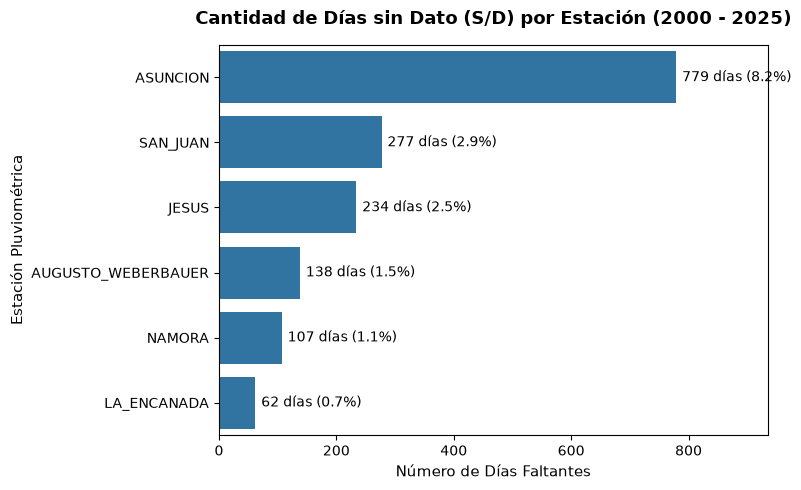

In [5]:
estaciones = df_clean.columns

missing_counts = df_clean[estaciones].isnull().sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing_counts.values, y=missing_counts.index, ax=ax)
ax.set_title("Cantidad de Días sin Dato (S/D) por Estación (2000 - 2025)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Número de Días Faltantes", fontsize=11)
ax.set_ylabel("Estación Pluviométrica", fontsize=11)
for i, v in enumerate(missing_counts.values):
    ax.text(v + 10, i, f"{v} días ({v/len(df_clean)*100:.1f}%)", va='center', fontsize=10)
ax.set_xlim(0, missing_counts.max() * 1.2)
plt.tight_layout()
plt.savefig("figuras_notebook/1_datos_faltantes.png", dpi=300)
plt.show()


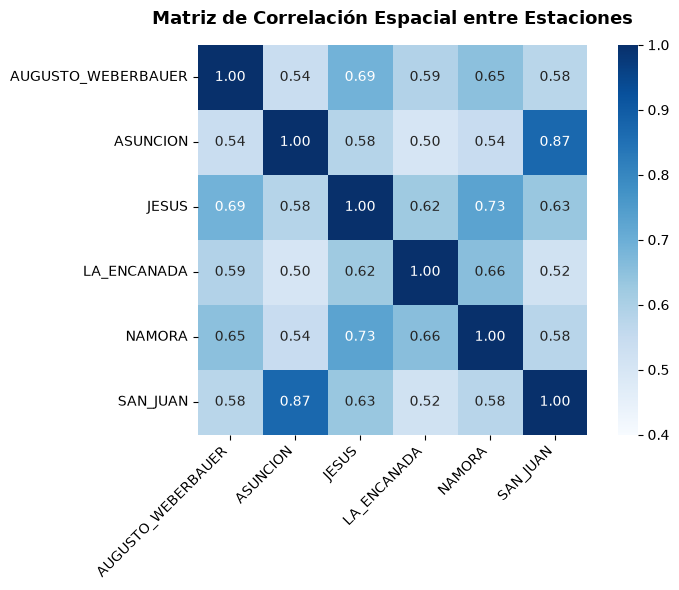

In [6]:
corr_matrix = df_clean[estaciones].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", cbar=True, ax=ax, vmin=0.4, vmax=1.0, square=True)
ax.set_title("Matriz de Correlación Espacial entre Estaciones", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("figuras_notebook/2_correlacion_espacial.png", dpi=300)
plt.show()


--- Resumen Estadístico de las Estaciones ---


,AUGUSTO_WEBERBAUER,ASUNCION,JESUS,LA_ENCANADA,NAMORA,SAN_JUAN
count,9359.000000,8718.000000,9263.000000,9435.000000,9390.000000,9220.000000
mean,1.949225,3.048234,1.869837,2.669147,2.451118,2.940293
std,4.142436,6.882117,4.188471,5.647642,5.070519,6.144855
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.900000,2.800000,1.500000,2.600000,2.500000,3.000000
max,51.800000,114.000000,60.800000,52.800000,46.500000,74.100000


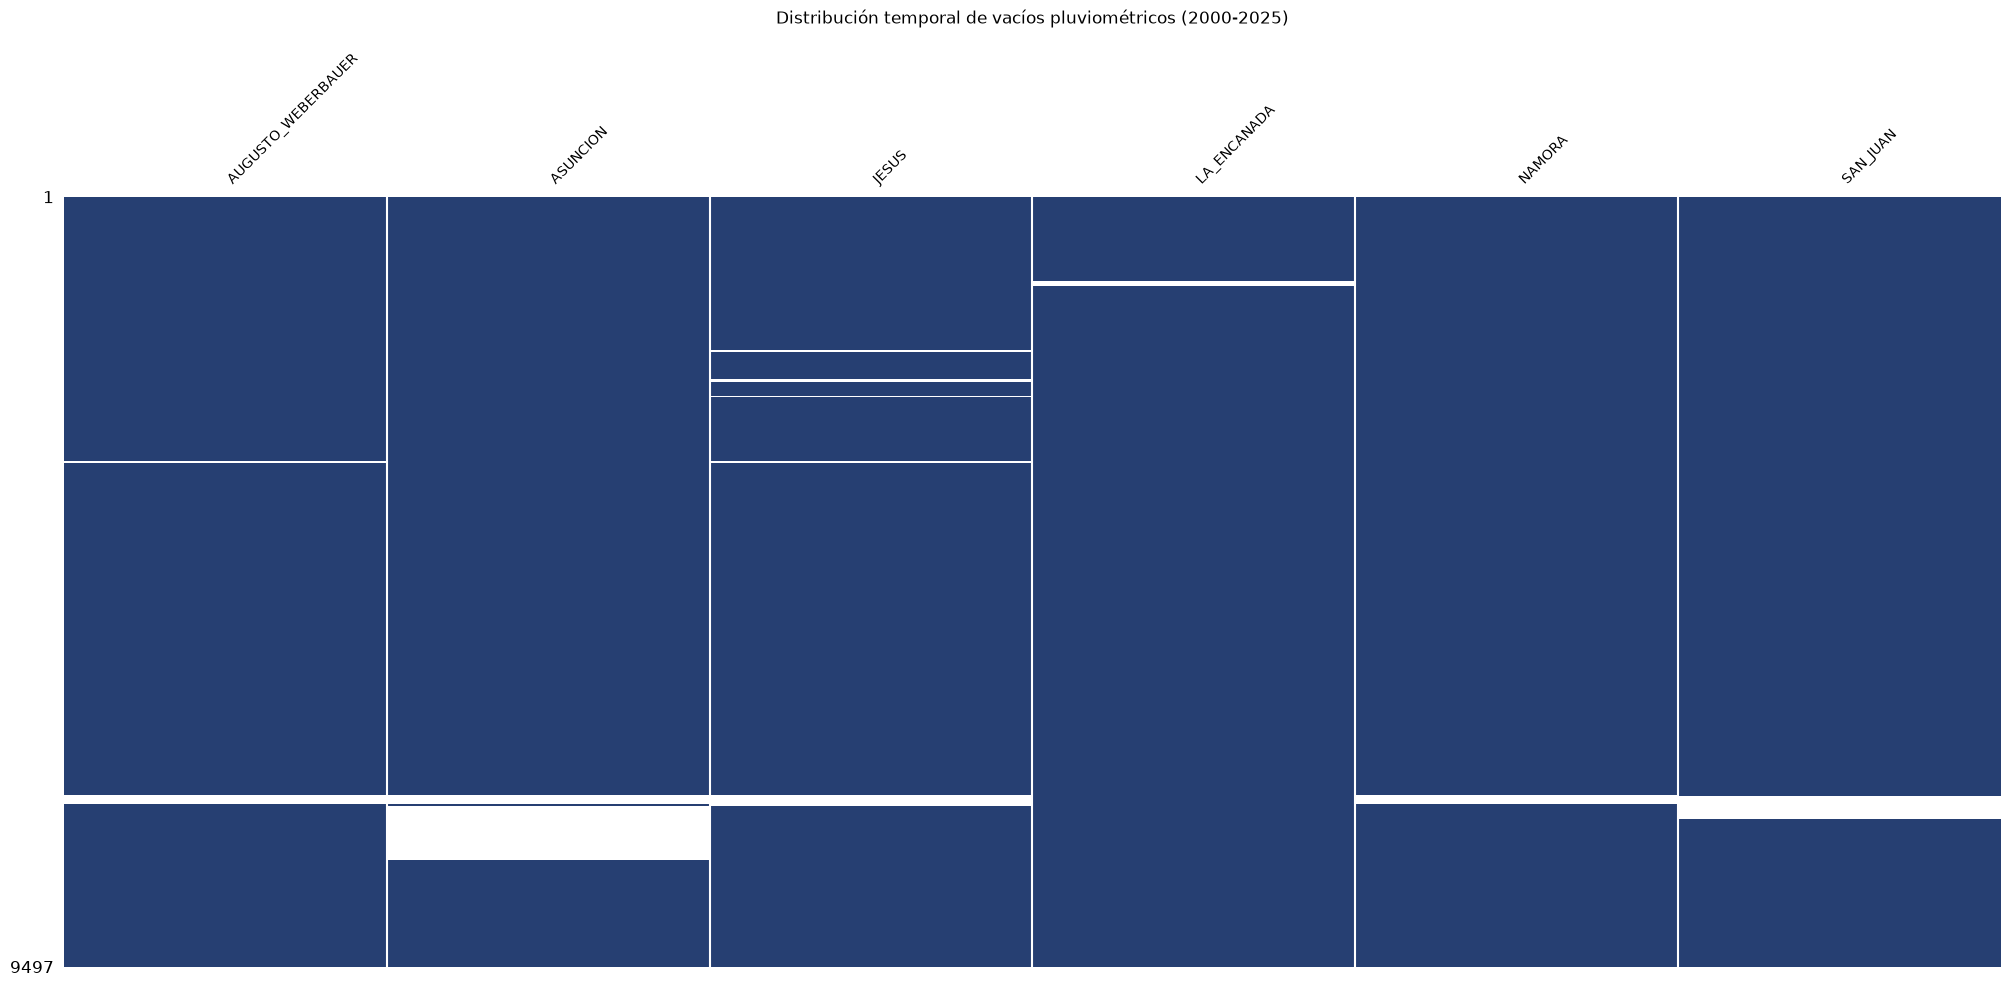

In [7]:
# Diagnóstico estadístico básico
print("--- Resumen Estadístico de las Estaciones ---")
display(df_clean.describe())

# Distribución temporal de los vacíos (permite juzgar si son MCAR o MNAR)
msno.matrix(df_clean, sparkline=False, fontsize=10, color=(0.15, 0.25, 0.45))
plt.title('Distribución temporal de vacíos pluviométricos (2000-2025)', fontsize=12, pad=20)
plt.show()


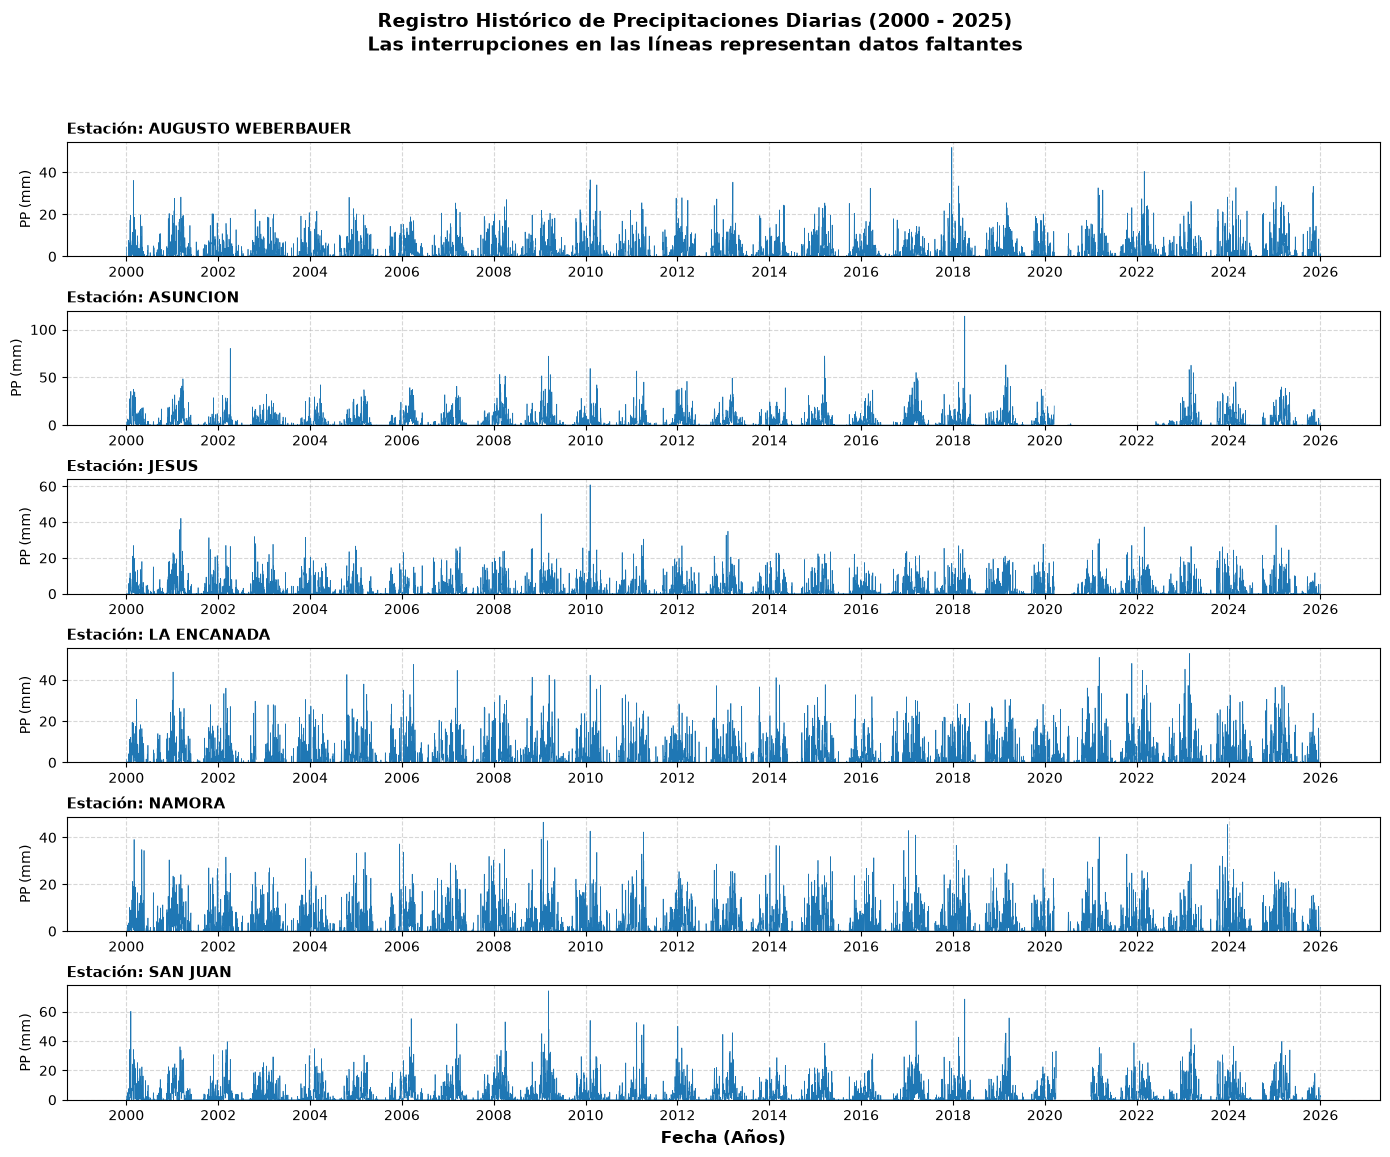

In [8]:
import matplotlib.dates as mdates

# 1. Configuración de los subplots apilados
estaciones = df_clean.columns
num_estaciones = len(estaciones)

# Creamos una figura con 'num_estaciones' filas y 1 columna.
# Un subplot por estación, apilados verticalmente
fig, axes = plt.subplots(nrows=num_estaciones, ncols=1, figsize=(14, 12), sharex=False)

# 2. Bucle para graficar cada estación en su respectivo subplot
for i, estacion in enumerate(estaciones):
    # Al graficar, matplotlib omitirá automáticamente los valores NaN dejando el espacio en blanco
    axes[i].plot(df_clean.index, df_clean[estacion], color='tab:blue', linewidth=0.5)

    # Configuraciones estéticas para cada subplot
    axes[i].set_ylabel('PP (mm)', fontsize=10)
    axes[i].set_title(f'Estación: {estacion.replace("_", " ")}', loc='left', fontsize=11, fontweight='bold')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].set_ylim(bottom=0) # Forzamos a que el eje Y empiece en 0

    # Configurar el eje X para mostrar ticks cada 2 años
    axes[i].xaxis.set_major_locator(mdates.YearLocator(2))
    axes[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


# 3. Ajustes finales de la figura global
plt.xlabel('Fecha (Años)', fontsize=12, fontweight='bold')
fig.suptitle('Registro Histórico de Precipitaciones Diarias (2000 - 2025)\nLas interrupciones en las líneas representan datos faltantes',
             fontsize=14, fontweight='bold', y=0.96)

# tight_layout ajusta automáticamente los márgenes para que no se superpongan los textos
plt.tight_layout()
plt.subplots_adjust(top=0.85) # Pequeño ajuste para darle espacio al título principal

# Mostrar o guardar el gráfico
plt.show()


### Distribución de Precipitaciones por Estación (Histogramas)

Estos histogramas muestran la distribución de los valores de precipitación diaria para cada estación. Los datos de 0 mm/día (días secos) están incluidos y representan una parte significativa de la distribución, lo cual es normal en registros pluviométricos. Los picos en valores más altos representan los eventos de lluvia más intensos.


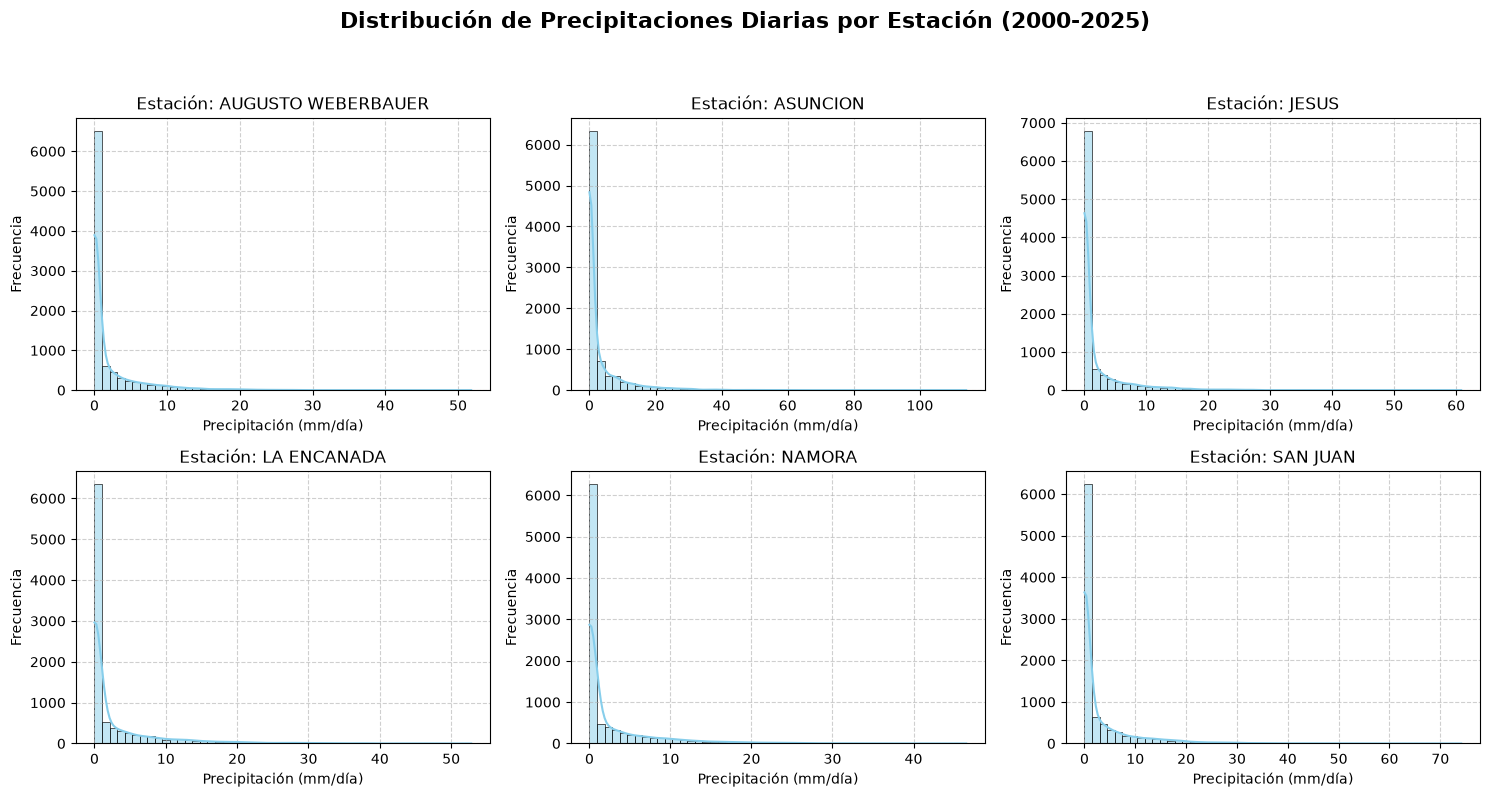

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Obtener los nombres de las estaciones (columnas de df_clean)
estaciones = df_clean.columns
num_estaciones = len(estaciones)

# Calcular el número de filas y columnas para la cuadrícula de subplots
# Si hay 6 estaciones, una cuadrícula de 2x3 o 3x2 funciona bien.
n_cols = 3
n_rows = (num_estaciones + n_cols - 1) // n_cols # Asegura suficientes filas

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, n_rows * 4), sharex=False, sharey=False)
axes = axes.flatten() # Aplanar la matriz de ejes para iterar fácilmente

for i, estacion in enumerate(estaciones):
    sns.histplot(df_clean[estacion].dropna(), bins=50, kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Estación: {estacion.replace("_", " ")}', fontsize=12)
    axes[i].set_xlabel('Precipitación (mm/día)', fontsize=10)
    axes[i].set_ylabel('Frecuencia', fontsize=10)
    axes[i].grid(True, linestyle='--', alpha=0.6)

# Ocultar cualquier subplot vacío si el número de estaciones no llena la cuadrícula perfectamente
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

fig.suptitle('Distribución de Precipitaciones Diarias por Estación (2000-2025)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Ajustar diseño para evitar superposición con el supertítulo
plt.show()



--- Matriz de Correlación entre Estaciones ---


,AUGUSTO_WEBERBAUER,ASUNCION,JESUS,LA_ENCANADA,NAMORA,SAN_JUAN
AUGUSTO_WEBERBAUER,1.000000,0.542365,0.688668,0.588334,0.652202,0.575289
ASUNCION,0.542365,1.000000,0.582063,0.502117,0.544551,0.870287
JESUS,0.688668,0.582063,1.000000,0.623012,0.730141,0.633603
LA_ENCANADA,0.588334,0.502117,0.623012,1.000000,0.655602,0.518177
NAMORA,0.652202,0.544551,0.730141,0.655602,1.000000,0.576550
SAN_JUAN,0.575289,0.870287,0.633603,0.518177,0.576550,1.000000



--- Gráficos de Dispersión entre Estaciones ---


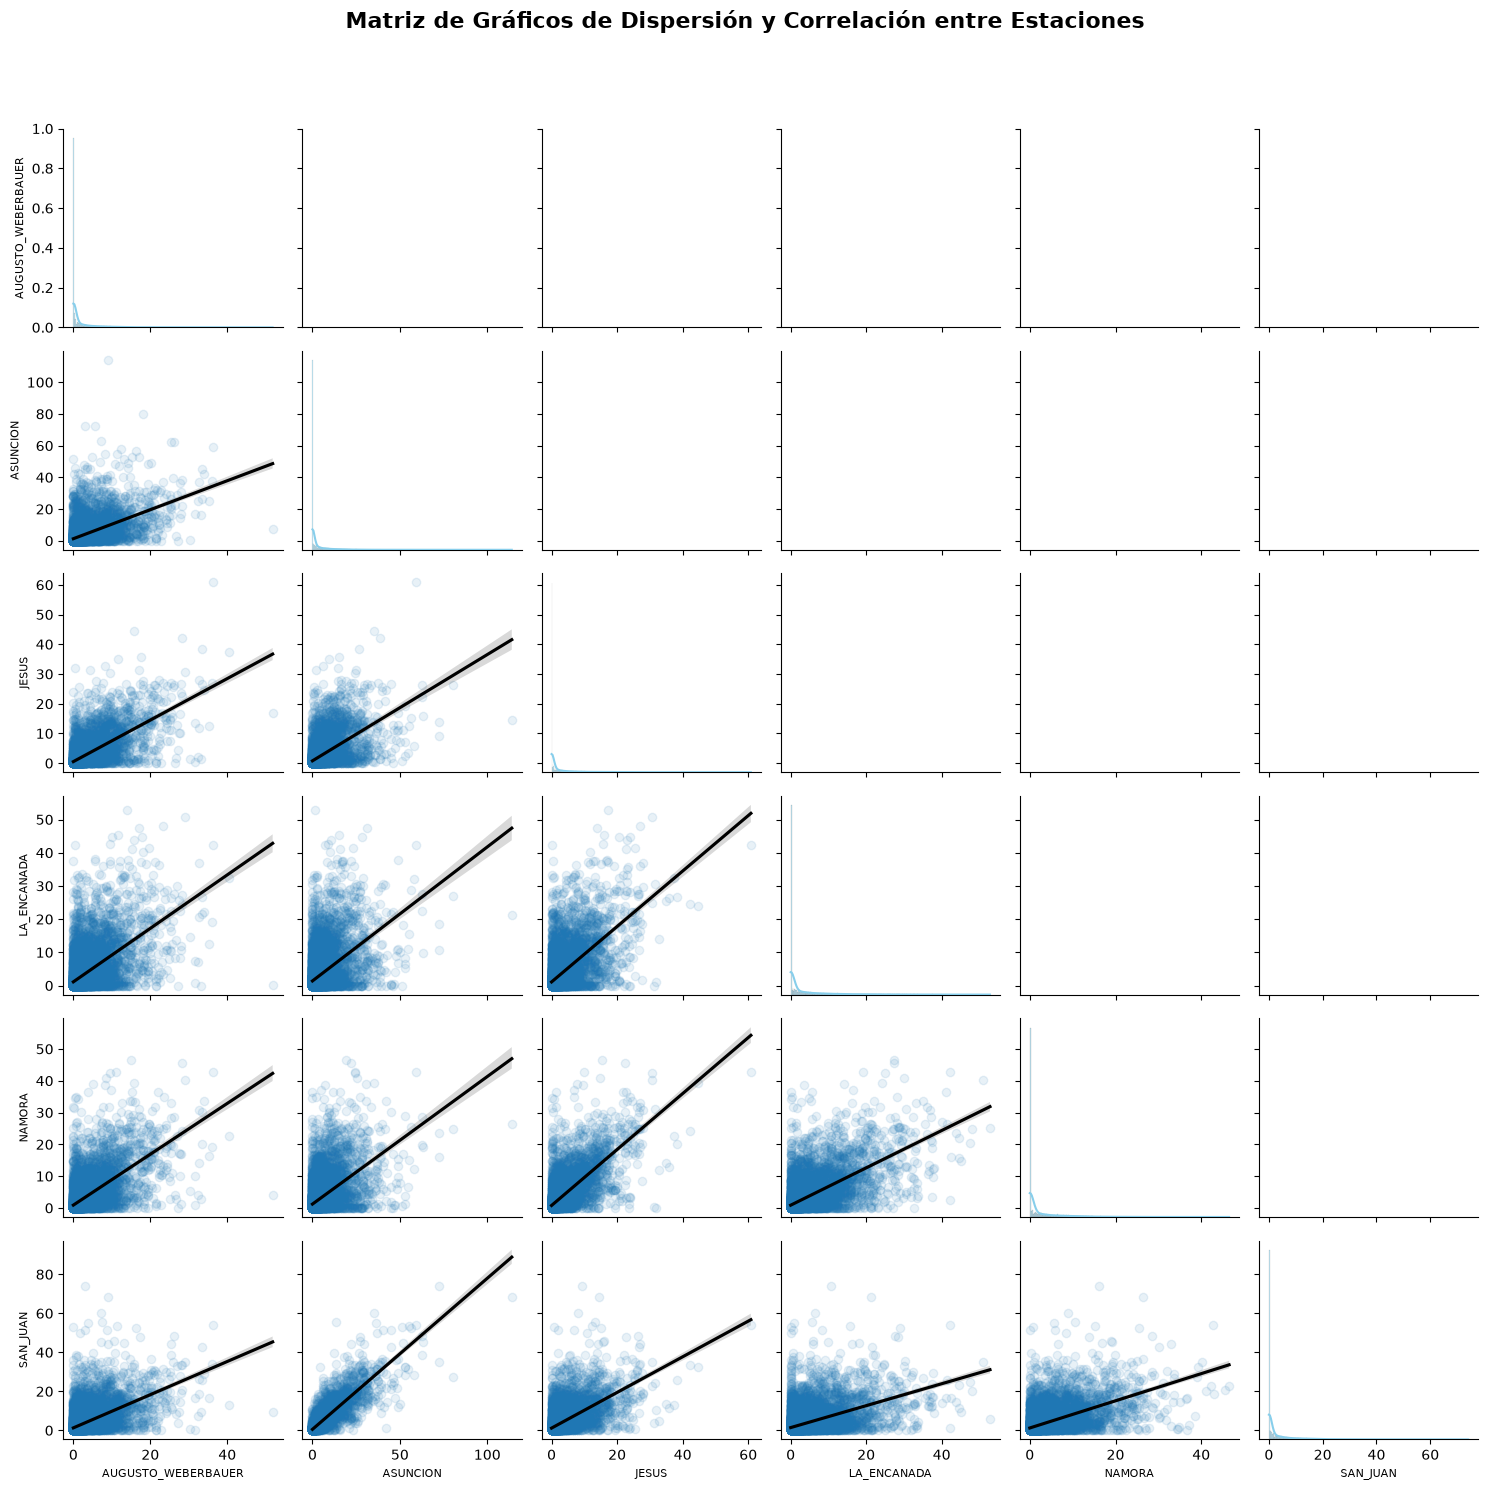

In [10]:
# Obtener los nombres de las estaciones
estaciones = df_clean.columns.tolist()

print("\n--- Matriz de Correlación entre Estaciones ---")
corr_matrix = df_clean[estaciones].corr()
display(corr_matrix)

# Generar el pairplot para visualizar las relaciones
print("\n--- Gráficos de Dispersión entre Estaciones ---")

# Crear un PairGrid para mayor control sobre los gráficos.
g = sns.PairGrid(df_clean[estaciones], diag_sharey=False)

# Mapear histogramas o KDEs en la diagonal para ver la distribución de cada estación
g.map_diag(sns.histplot, kde=True, color='skyblue')

# Mapear gráficos de dispersión con línea de regresión para las relaciones bivariadas
g.map_lower(sns.regplot, scatter_kws={'alpha':0.1}, line_kws={'color':'black'})

# Añadir títulos a los ejes
for ax in g.axes.flatten():
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=8)
        ax.set_ylabel(ax.get_ylabel(), fontsize=8)

g.fig.suptitle('Matriz de Gráficos de Dispersión y Correlación entre Estaciones', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Ajustar diseño para evitar superposición con el supertítulo
plt.show()


### Media Mensual de Precipitación por Estación para Detectar Estacionalidad

Este análisis calcula la precipitación promedio para cada mes del año, consolidando todos los años disponibles en el conjunto de datos. Esto ayuda a visualizar el ciclo estacional típico de precipitación para cada estación, identificando los meses más húmedos y más secos.


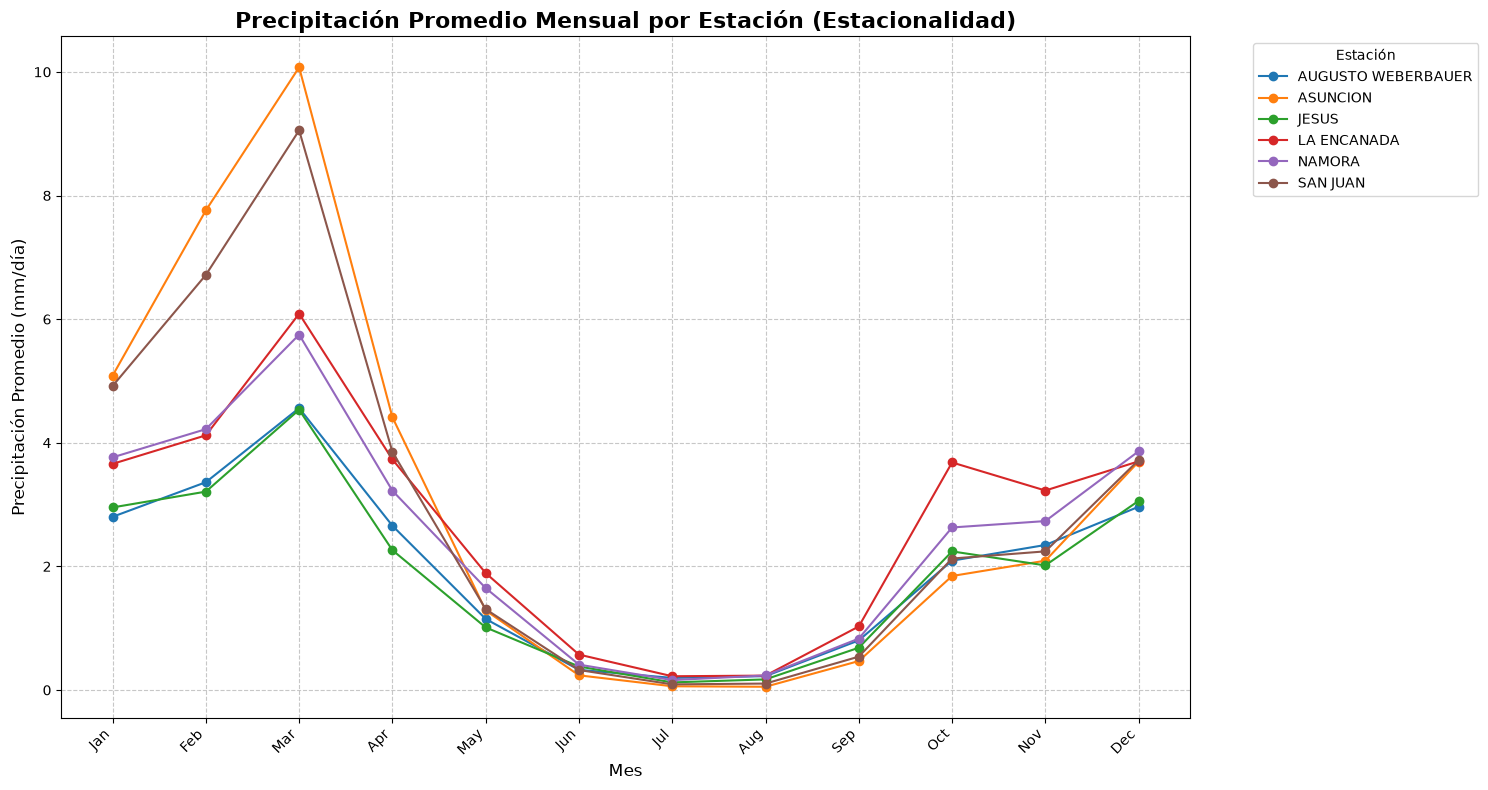

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import calendar

# Calcular la precipitación promedio para cada mes del año, a través de todos los años
# 'df_clean.index.month' extrae el número del mes (1-12)
# 'mean()' calcula el promedio de precipitación para ese mes en todas las estaciones.
monthly_avg_precipitation = df_clean.groupby(df_clean.index.month).mean()

# Asignar nombres de meses en lugar de números para una mejor visualización
monthly_avg_precipitation.index = [calendar.month_abbr[i] for i in monthly_avg_precipitation.index]

# Visualización
plt.figure(figsize=(15, 8))

# Iterar sobre cada estación para graficar su promedio mensual
for estacion in monthly_avg_precipitation.columns:
    plt.plot(monthly_avg_precipitation.index, monthly_avg_precipitation[estacion], marker='o', label=estacion.replace('_', ' '))

plt.title('Precipitación Promedio Mensual por Estación (Estacionalidad)', fontsize=16, fontweight='bold')
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Precipitación Promedio (mm/día)', fontsize=12)
plt.legend(title='Estación', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### Estacionalidad: Ciclo Climatológico Anual Regional

A diferencia del bloque anterior (que promedia directamente los valores diarios por mes), aquí se **acumula la precipitación a escala mensual** por estación y luego se promedia entre estaciones para obtener un régimen pluviométrico regional único. Se calculan la media y la desviación estándar interanual ($\pm 1\sigma$) de cada mes para cuantificar no solo el ciclo estacional, sino también su variabilidad de un año a otro. Las barras de error grandes indican meses con comportamiento más errático (ej. transición seco-húmedo), mientras que barras de error pequeñas indican meses con régimen más consistente.


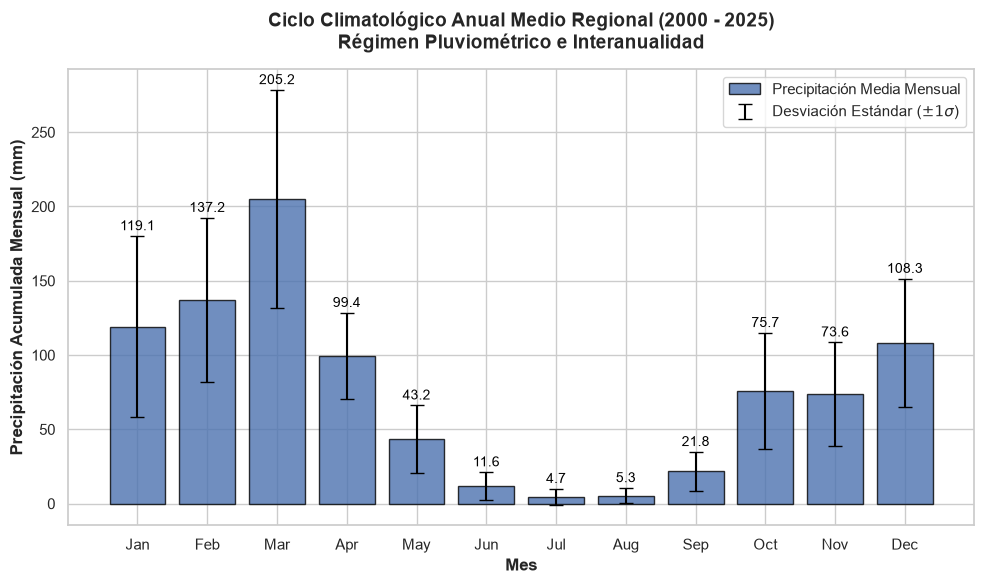

In [12]:
import calendar

# 1. Procesamiento Matemático
# Acumulamos de diario a mensual. min_count=1 asegura que si todo el mes es NaN, el total sea NaN.
df_monthly = df_clean.resample('ME').sum(min_count=1)

# Calculamos el promedio regional para simplificar la visualización de la cuenca
df_monthly['Promedio_Regional'] = df_monthly.mean(axis=1)

# Agrupamos por los 12 meses y calculamos Media y Desviación Estándar
climatology = df_monthly.groupby(df_monthly.index.month)['Promedio_Regional'].agg(['mean', 'std'])
meses = [calendar.month_abbr[i] for i in range(1, 13)]

# 2. Visualización
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de barras para la media multianual
barras = ax.bar(meses, climatology['mean'], color='#4C72B0', alpha=0.8,
                edgecolor='black', linewidth=1, label='Precipitación Media Mensual')

# Barras de error para la desviación estándar
ax.errorbar(meses, climatology['mean'], yerr=climatology['std'], fmt='none',
            ecolor='black', capsize=5, elinewidth=1.5, label='Desviación Estándar ($\pm 1\sigma$)')

# Textos y etiquetas
ax.set_title('Ciclo Climatológico Anual Medio Regional (2000 - 2025)\nRégimen Pluviométrico e Interanualidad',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Mes', fontsize=12, fontweight='bold')
ax.set_ylabel('Precipitación Acumulada Mensual (mm)', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', frameon=True)

# Imprimir el valor numérico exacto sobre cada barra
for i, rect in enumerate(barras):
    height = rect.get_height()
    # Posicionamos el texto justo por encima de la barra de error
    ax.text(rect.get_x() + rect.get_width()/2., height + climatology['std'].iloc[i] + 2,
            f'{height:.1f}', ha='center', va='bottom', fontsize=10, color='black')

plt.tight_layout()
plt.show()


### Estacionalidad por Cada Estación Pluviométrica

Se repite el mismo análisis climatológico del bloque anterior, pero **desagregado por estación** en lugar de promediar la cuenca. Todos los subgráficos comparten la misma escala del eje Y (`sharey=True`) para permitir comparar directamente la magnitud de precipitación entre estaciones. Esto permite identificar si alguna estación tiene un régimen (temporada de lluvias, meses secos) notablemente distinto al resto, lo cual sería relevante para la etapa de modelado posterior.


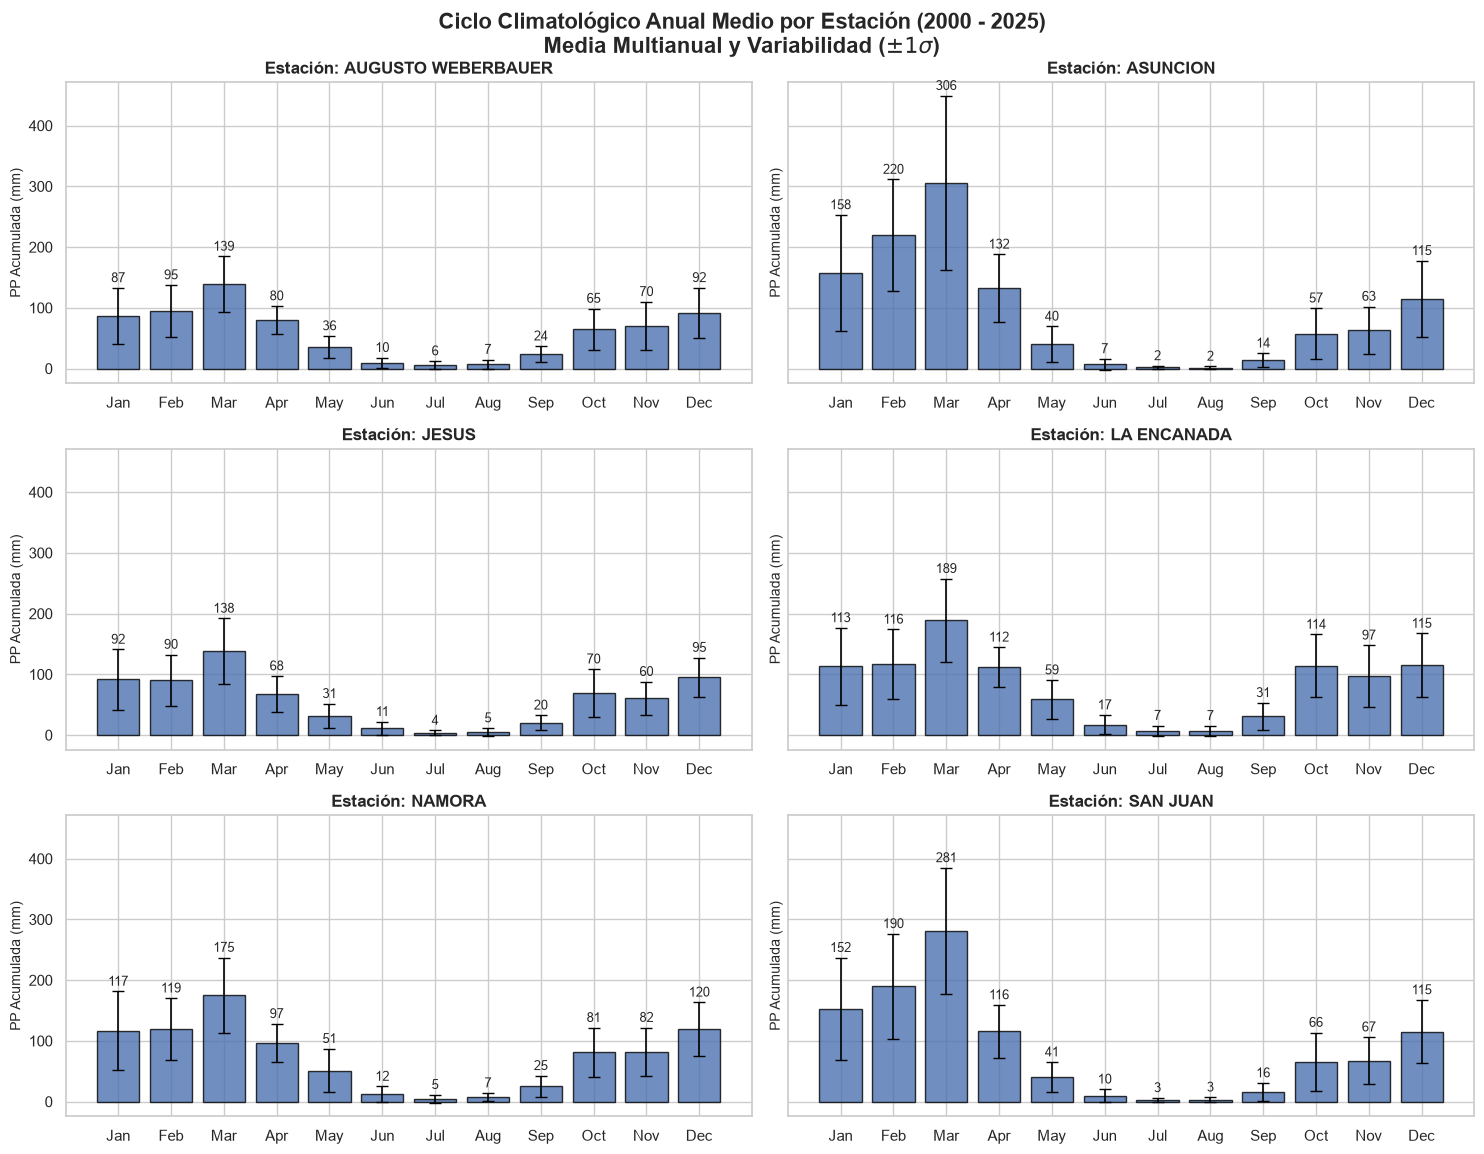

In [13]:
import calendar

# 1. Procesamiento Matemático Estación por Estación
# Acumulamos a escala mensual
df_monthly = df_clean.resample('ME').sum(min_count=1)

# Calculamos media y desviación estándar para cada estación independientemente
climatology_mean = df_monthly.groupby(df_monthly.index.month).mean()
climatology_std = df_monthly.groupby(df_monthly.index.month).std()

meses = [calendar.month_abbr[i] for i in range(1, 13)]
estaciones = df_clean.columns

# 2. Visualización en Grilla (3x2)
sns.set_theme(style="whitegrid")
# sharey=True es vital para que todas las estaciones se puedan comparar en la misma escala (ej. 0 a 250 mm)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 12), sharex=False, sharey=True)
axes = axes.flatten() # Aplanamos la matriz de ejes para iterar fácilmente

for i, estacion in enumerate(estaciones):
    ax = axes[i]
    medias = climatology_mean[estacion]
    desviaciones = climatology_std[estacion]

    # Gráfico de barras
    barras = ax.bar(meses, medias, color='#4C72B0', alpha=0.8,
                    edgecolor='black', linewidth=1)

    # Barras de error
    ax.errorbar(meses, medias, yerr=desviaciones, fmt='none',
                ecolor='black', capsize=4, elinewidth=1.2)

    # Configuraciones estéticas de cada subplot
    ax.set_title(f'Estación: {estacion.replace("_", " ")}', fontsize=12, fontweight='bold')
    ax.set_ylabel('PP Acumulada (mm)', fontsize=10)

    # Etiquetas numéricas (reducidas a 0 decimales para no saturar la gráfica)
    for j, rect in enumerate(barras):
        height = rect.get_height()
        if not np.isnan(height):
            # Posicionamos el texto sobre la barra de error
            ax.text(rect.get_x() + rect.get_width()/2., height + desviaciones.iloc[j] + 5,
                    f'{height:.0f}', ha='center', va='bottom', fontsize=9)

# Ajustes globales de la figura
plt.suptitle('Ciclo Climatológico Anual Medio por Estación (2000 - 2025)\nMedia Multianual y Variabilidad ($\pm 1\sigma$)',
             fontsize=16, fontweight='bold', y=0.96)
plt.tight_layout()
plt.subplots_adjust(top=0.90) # Espacio para el título principal
plt.show()


### Análisis de Doble Masa (Control de Consistencia Temporal)

La **curva de doble masa** es la técnica estándar en hidrología para evaluar la consistencia de un registro pluviométrico a lo largo del tiempo. Para cada estación se grafica su precipitación acumulada anual contra el promedio acumulado de las demás estaciones ("estaciones patrón"). Si el registro es consistente, la nube de puntos debe seguir una línea recta (alto $R^2$); un quiebre de pendiente indicaría un cambio físico no climático (reubicación del pluviómetro, cambio de instrumento, error de digitación, etc.) que rompe la homogeneidad de la serie. Esto justifica la confiabilidad de los datos que se usarán en la imputación y el modelado.


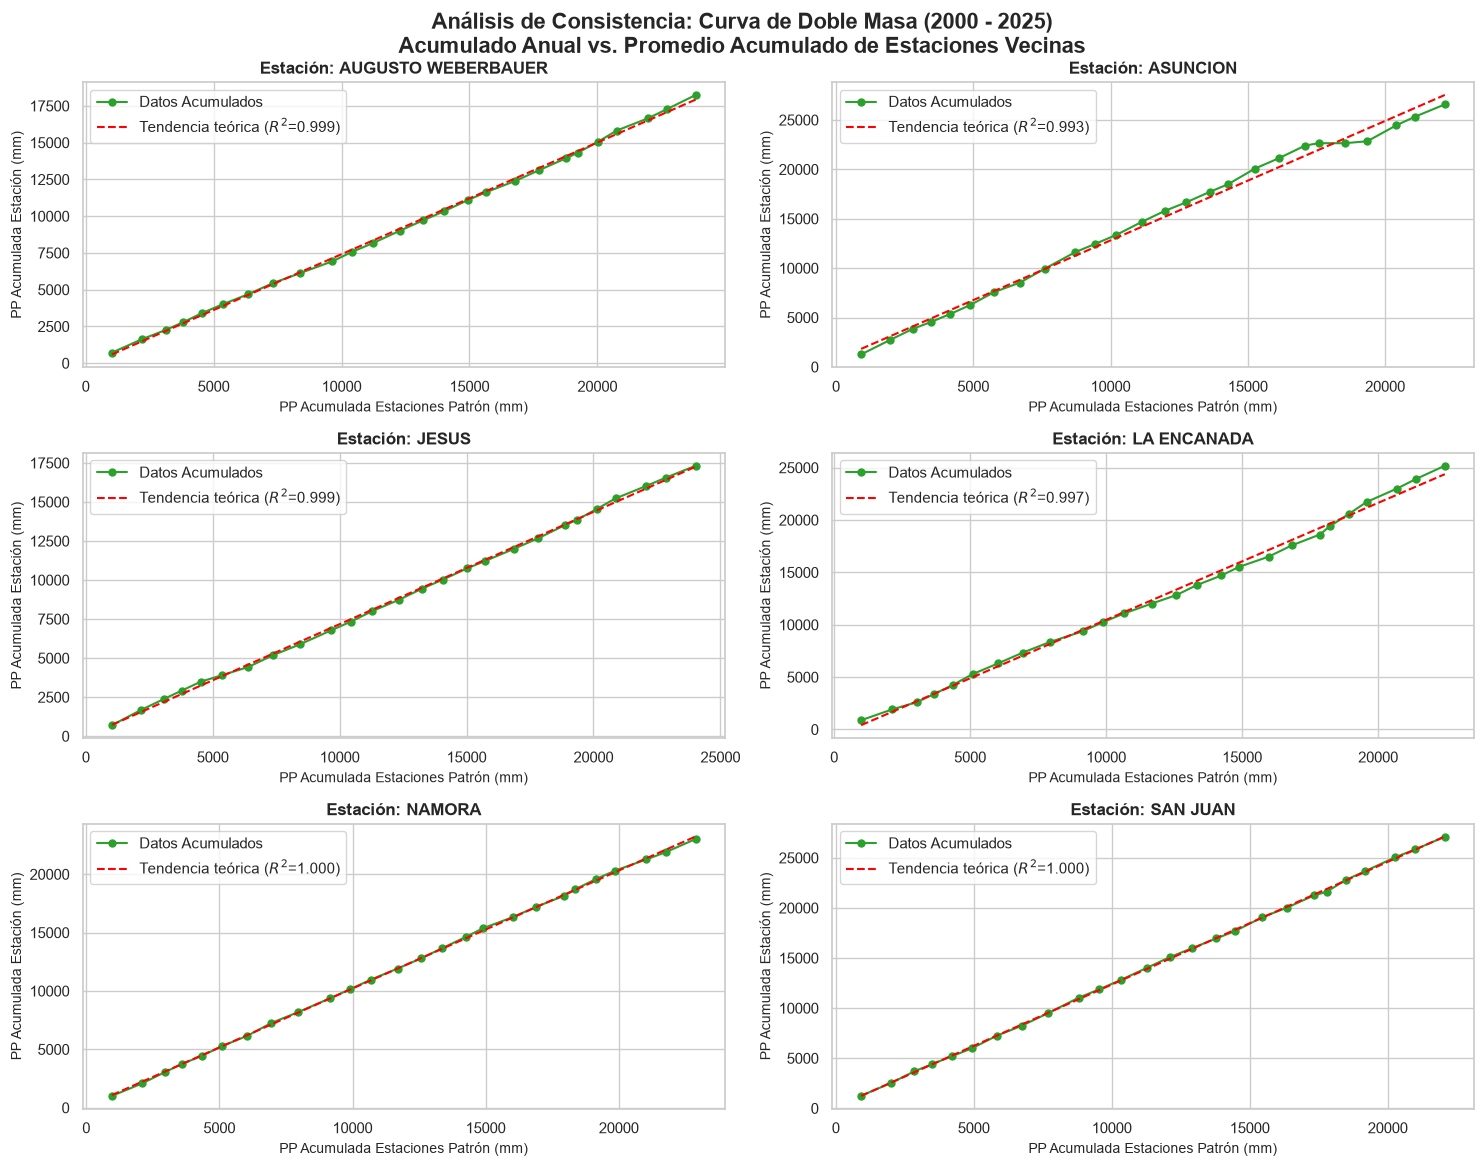

In [14]:
from sklearn.linear_model import LinearRegression

# 1. Acumulación Anual
# La doble masa requiere datos a nivel anual (o mensual acumulado continuo)
df_annual = df_clean.resample('YE').sum(min_count=1)

sns.set_theme(style="whitegrid")
estaciones = df_clean.columns

# 2. Configuración de Subplots (3x2)
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 12))
axes = axes.flatten()

for i, estacion in enumerate(estaciones):
    ax = axes[i]

    # Aislar las estaciones patrón (todas menos la que estamos evaluando en este ciclo)
    estaciones_patron = [e for e in estaciones if e != estacion]

    # Calcular el promedio anual de las estaciones patrón
    promedio_patron_anual = df_annual[estaciones_patron].mean(axis=1)

    # Aplicar la suma acumulada histórica
    acumulado_patron = promedio_patron_anual.cumsum()
    acumulado_estacion = df_annual[estacion].cumsum()

    # Limpiar posibles NaNs de años incompletos para que la regresión no falle
    valid_mask = ~np.isnan(acumulado_patron) & ~np.isnan(acumulado_estacion)
    x = acumulado_patron[valid_mask].values.reshape(-1, 1)
    y = acumulado_estacion[valid_mask].values

    # Trazar el Gráfico de Doble Masa (puntos y línea de unión)
    ax.plot(acumulado_patron, acumulado_estacion, marker='o', markersize=5,
            linestyle='-', color='#2CA02C', label='Datos Acumulados')

    # Calcular y trazar línea de tendencia teórica (Regresión Lineal)
    if len(x) > 0:
        model = LinearRegression()
        model.fit(x, y)
        y_pred = model.predict(x)
        r2 = model.score(x, y)
        ax.plot(x, y_pred, color='red', linestyle='--', linewidth=1.5,
                label=f'Tendencia teórica ($R^2$={r2:.3f})')

    # Estética de los subgráficos
    ax.set_title(f'Estación: {estacion.replace("_", " ")}', fontsize=12, fontweight='bold')
    ax.set_xlabel('PP Acumulada Estaciones Patrón (mm)', fontsize=10)
    ax.set_ylabel('PP Acumulada Estación (mm)', fontsize=10)
    ax.legend(loc='upper left', frameon=True)

plt.suptitle('Análisis de Consistencia: Curva de Doble Masa (2000 - 2025)\nAcumulado Anual vs. Promedio Acumulado de Estaciones Vecinas',
             fontsize=16, fontweight='bold', y=0.97)
plt.tight_layout()
plt.subplots_adjust(top=0.91)
plt.show()


### Mapa de Calor Temporal (Año x Mes)

Se construye una matriz Año x Mes de precipitación mensual acumulada para cada estación y se visualiza como *heatmap*, con una escala de color común (`vmax_global`) para poder comparar intensidades entre estaciones. Esta vista compacta permite detectar de un vistazo tanto la estacionalidad (columnas más oscuras en época de lluvias) como anomalías interanuales (años particularmente secos o húmedos, franjas de datos faltantes rellenadas con 0 que podrían confundirse con meses realmente secos).


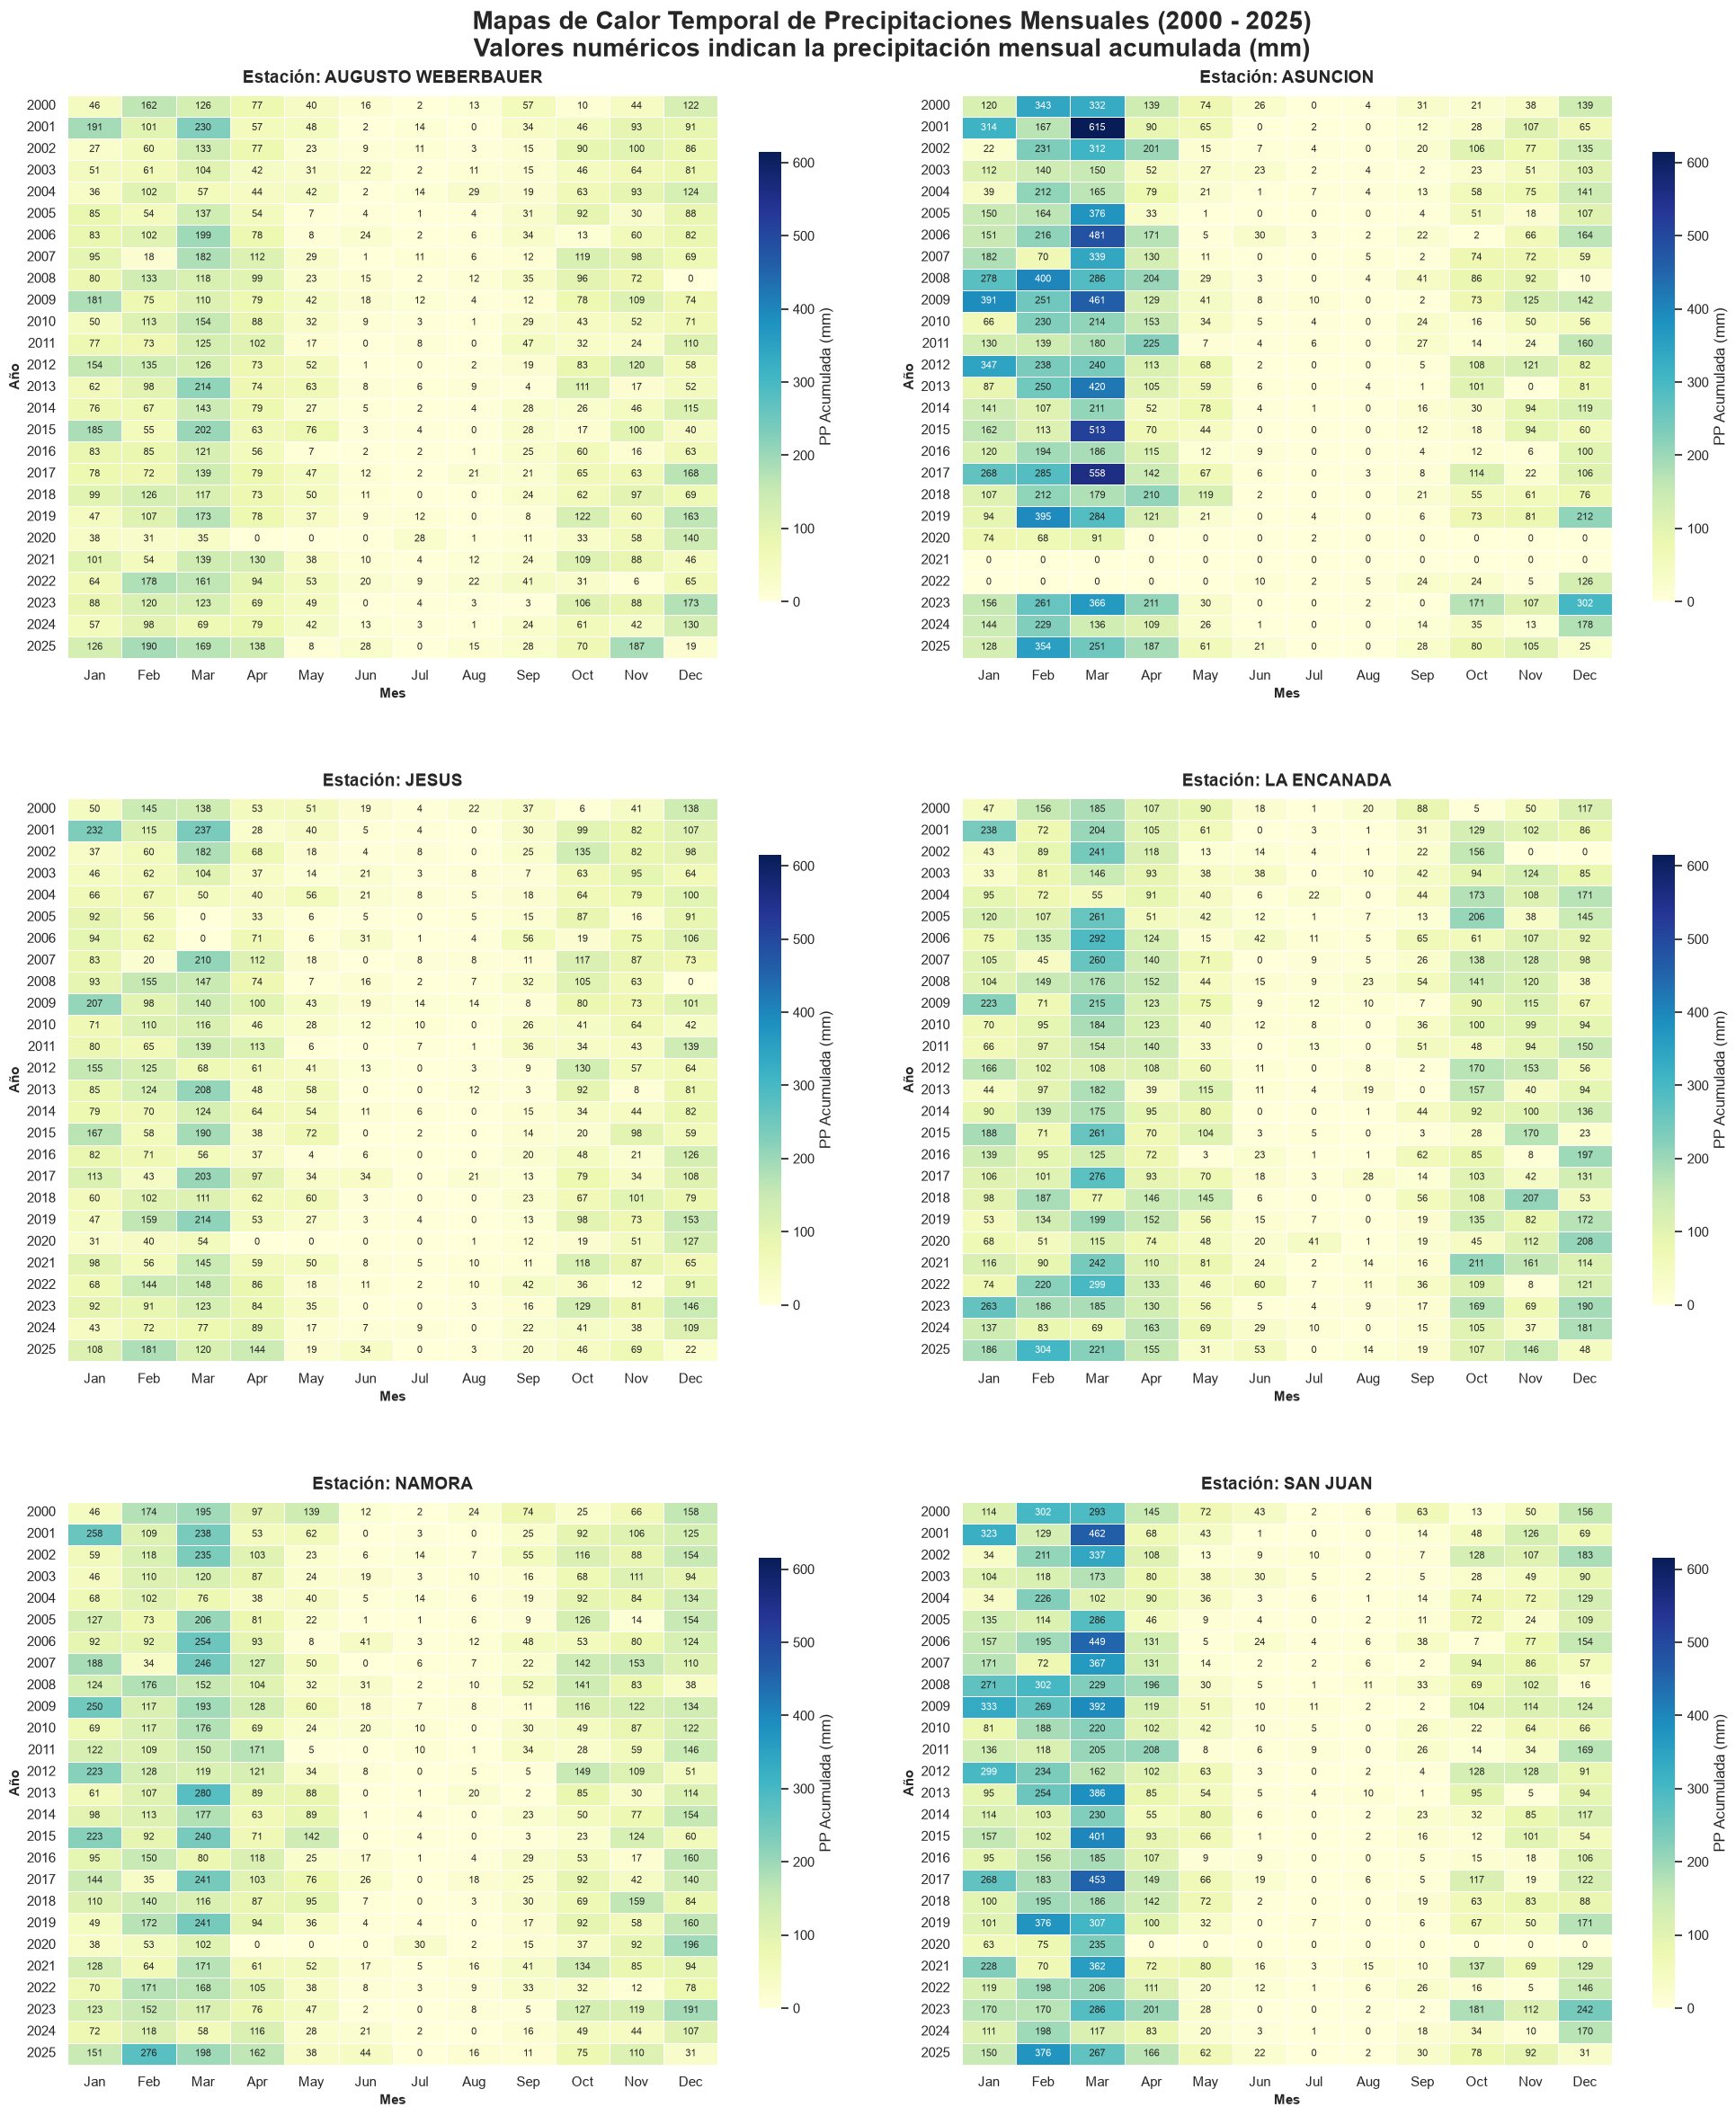

In [15]:
import calendar

estaciones = df_clean.columns

# 1. Acumulado mensual; los meses sin datos se rellenan con 0 para que el mapa de calor no tenga celdas en blanco
df_monthly = df_clean.resample('ME').sum().fillna(0)

# Añadimos las columnas temporales para el pivote
df_monthly['Año'] = df_monthly.index.year
df_monthly['Mes'] = df_monthly.index.month

meses_nombres = [calendar.month_abbr[i] for i in range(1, 13)]

# 2. Configuración del Gráfico (2 columnas x 3 filas)
sns.set_theme(style="white")
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(20, 24))
axes = axes.flatten()

vmax_global = df_monthly[estaciones].max().max()

for i, estacion in enumerate(estaciones):
    ax = axes[i]
    pivot_table = df_monthly.pivot_table(values=estacion, index='Año', columns='Mes')
    pivot_table.columns = meses_nombres

    # Dibujado del Heatmap
    sns.heatmap(pivot_table, cmap='YlGnBu', ax=ax, vmin=0, vmax=vmax_global,
                annot=True,              # Muestra los números
                fmt=".0f",               # Sin decimales
                annot_kws={"size": 8},   # Tamaño de letra de las celdas
                cbar_kws={'label': 'PP Acumulada (mm)', 'shrink': 0.8},
                linewidths=0.5, linecolor='white')

    # Textos de los subgráficos
    ax.set_title(f'Estación: {estacion.replace("_", " ")}', fontsize=14, fontweight='bold', pad=10)
    ax.set_xlabel('Mes', fontsize=11, fontweight='bold')
    ax.set_ylabel('Año', fontsize=11, fontweight='bold')
    ax.tick_params(axis='y', rotation=0)

plt.suptitle('Mapas de Calor Temporal de Precipitaciones Mensuales (2000 - 2025)\nValores numéricos indican la precipitación mensual acumulada (mm)',
             fontsize=20, fontweight='bold', y=0.98)

plt.tight_layout()
plt.subplots_adjust(top=0.94, hspace=0.25, wspace=0.1)

# Guardar y mostrar
plt.savefig('figuras_notebook/4_mapa_calor_temporal.png', dpi=300)
plt.show()


### Análisis de Transición (Cadenas de Markov de 1er Orden)

Se modela cada día como un estado binario **Húmedo** (precipitación > 0) o **Seco** (precipitación = 0), y se calcula la probabilidad de persistencia mes a mes: $P(\text{Húmedo}_t \mid \text{Húmedo}_{t-1})$ y $P(\text{Seco}_t \mid \text{Seco}_{t-1})$. Esta es una cadena de Markov de primer orden, ya que el estado de mañana depende únicamente del estado de hoy. El resultado cuantifica cuán "pegajoso" es el clima en cada estación: valores altos de $P(\text{Seco}\mid\text{Seco})$ en meses de estiaje confirman rachas secas prolongadas, mientras que $P(\text{Húmedo}\mid\text{Húmedo})$ alto en época de lluvias confirma persistencia de eventos húmedos consecutivos.


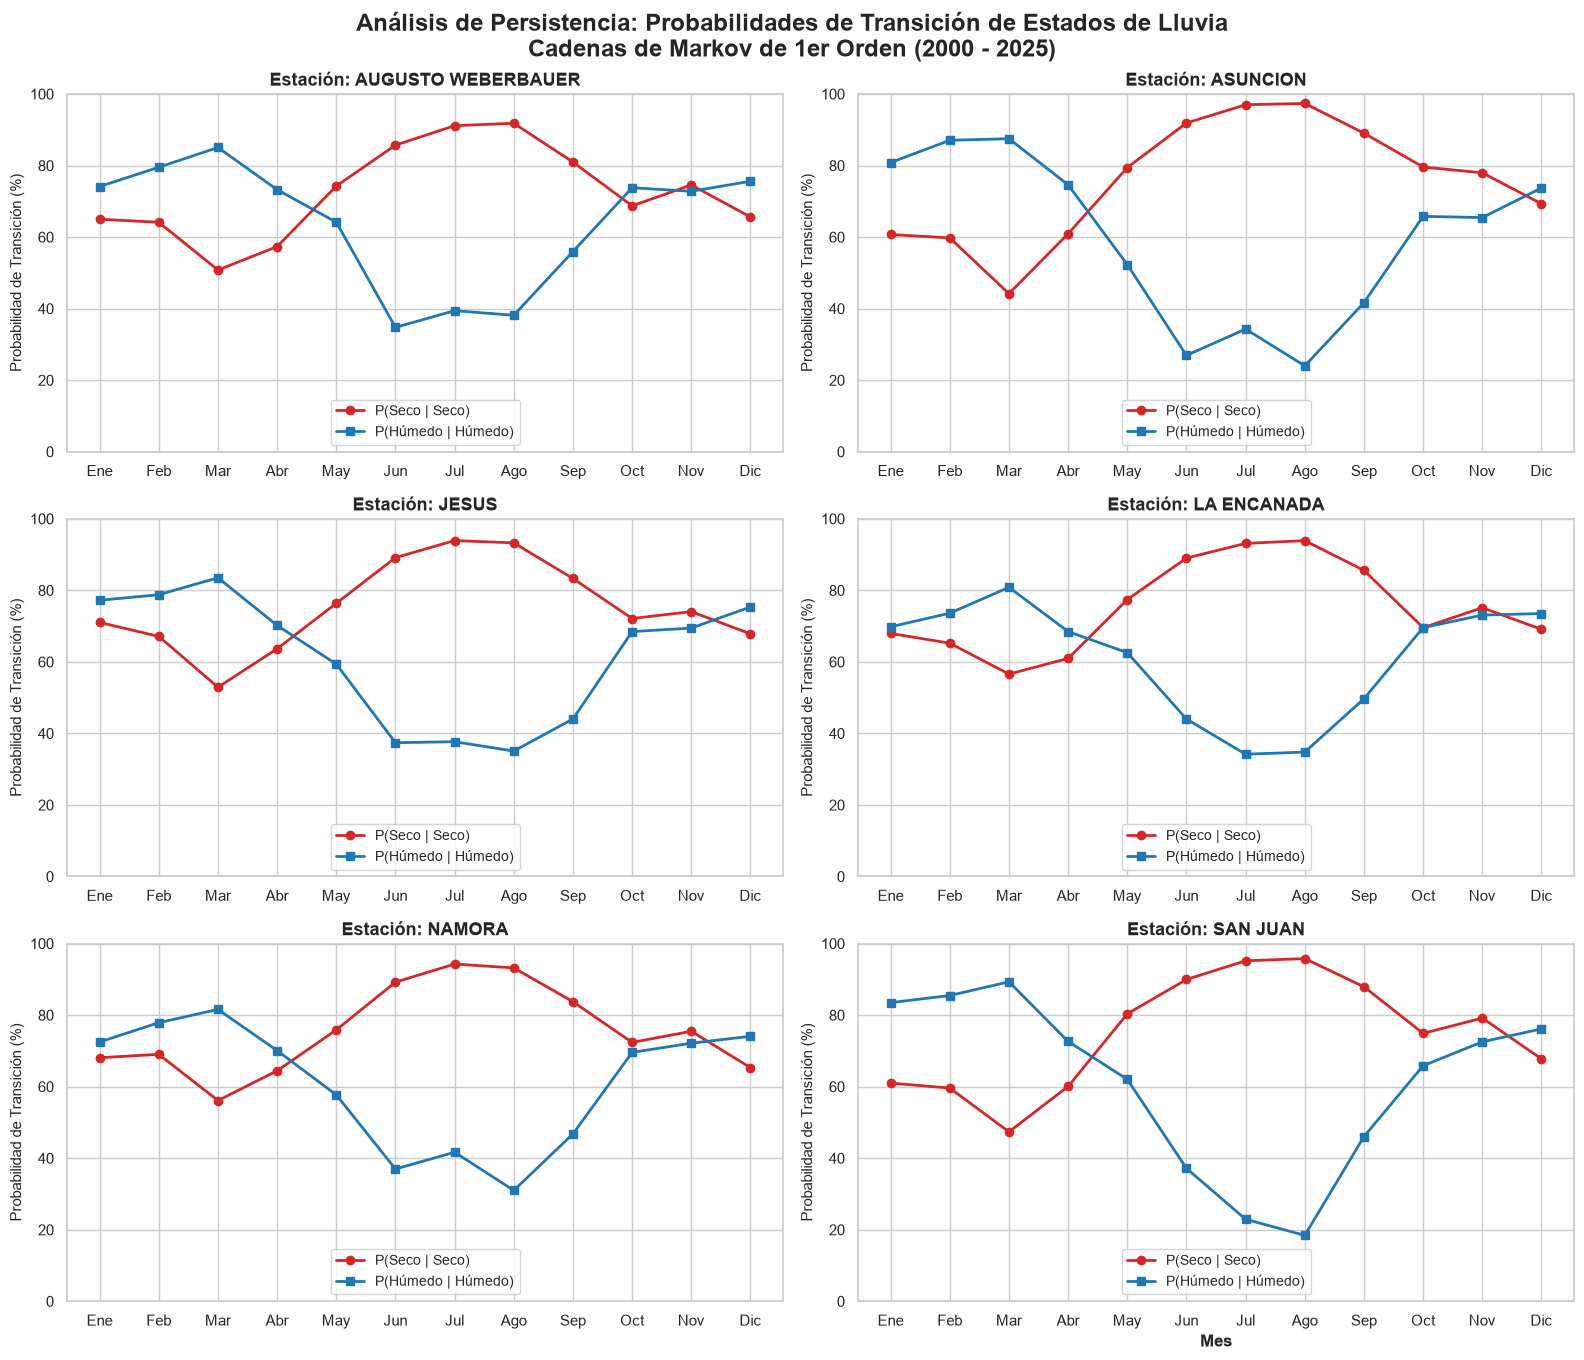

In [16]:
estaciones = df_clean.columns
meses_nombres = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

# 1. Configuración del Gráfico (3 filas x 2 columnas)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(16, 14), sharex=False, sharey=False)
axes = axes.flatten()

# 2. Cálculo de Persistencia de Markov por estación
for i, estacion in enumerate(estaciones):
    ax = axes[i]

    # Extraer la serie de la estación y aislar el mes correspondiente
    serie = df_clean[[estacion]].copy()
    serie['Mes'] = serie.index.month

    # Crear variable binaria: 1 si es Húmedo (>0), 0 si es Seco (==0), NaN se mantiene NaN
    serie['Estado'] = np.where(serie[estacion] > 0, 1, np.where(serie[estacion] == 0, 0, np.nan))

    # Desplazar la serie un día para obtener el "Estado de Ayer"
    serie['Estado_Ayer'] = serie['Estado'].shift(1)

    # Listas para almacenar las probabilidades de cada mes
    p_ww_list = []
    p_dd_list = []

    for mes in range(1, 13):
        datos_mes = serie[serie['Mes'] == mes]

        # Conteos de transiciones
        w_w = len(datos_mes[(datos_mes['Estado'] == 1) & (datos_mes['Estado_Ayer'] == 1)])
        w_d = len(datos_mes[(datos_mes['Estado'] == 0) & (datos_mes['Estado_Ayer'] == 1)])

        d_d = len(datos_mes[(datos_mes['Estado'] == 0) & (datos_mes['Estado_Ayer'] == 0)])
        d_w = len(datos_mes[(datos_mes['Estado'] == 1) & (datos_mes['Estado_Ayer'] == 0)])

        # Evitar división por cero
        p_ww = (w_w / (w_w + w_d)) * 100 if (w_w + w_d) > 0 else 0
        p_dd = (d_d / (d_d + d_w)) * 100 if (d_d + d_w) > 0 else 0

        p_ww_list.append(p_ww)
        p_dd_list.append(p_dd)

    # 3. Trazado de las curvas
    ax.plot(meses_nombres, p_dd_list, marker='o', color='#D62728', linewidth=2, label='P(Seco | Seco)')
    ax.plot(meses_nombres, p_ww_list, marker='s', color='#1F77B4', linewidth=2, label='P(Húmedo | Húmedo)')

    # Configuraciones estéticas
    ax.set_title(f'Estación: {estacion.replace("_", " ")}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Probabilidad de Transición (%)', fontsize=11)
    ax.set_ylim(0, 100) # Límite en 100% de probabilidad
    ax.legend(loc='lower center', frameon=True, fontsize=10)

# Ajustes globales
plt.xlabel('Mes', fontsize=12, fontweight='bold')
plt.suptitle('Análisis de Persistencia: Probabilidades de Transición de Estados de Lluvia\nCadenas de Markov de 1er Orden (2000 - 2025)',
             fontsize=17, fontweight='bold', y=0.97 )

plt.tight_layout()
plt.subplots_adjust(top=0.91)
plt.savefig('figuras_notebook/5_analisis_transicion.png', dpi=300)
plt.show()


# Imputación Multivariada y Escalado Robusto

Los vacíos detectados en la sección de limpieza de datos (S/D) no pueden dejarse como NaN para el modelado, ya que las redes neuronales y los árboles de decisión requieren matrices completas. En lugar de imputar cada estación de forma aislada (ej. con la media), se usa **IterativeImputer (MICE — Multivariate Imputation by Chained Equations)**: cada estación con vacíos se predice a partir de las demás estaciones usando un modelo de regresión (`ExtraTreesRegressor`), aprovechando la correlación espacial entre estaciones vecinas mostrada en el mapa de calor de correlación de la sección de limpieza de datos. Se restringe `min_value=0` porque no pueden existir precipitaciones negativas. El resultado se valida comparando las estadísticas descriptivas (media, desviación estándar) antes y después de imputar, para confirmar que la imputación no distorsiona el régimen pluviométrico original.

**Prevención de fuga de datos (*data leakage*):** el `IterativeImputer` aprende, durante el `fit`, cómo se relacionan estadísticamente las estaciones entre sí. Si se ajusta con la serie completa (2000-2025), el modelo de imputación ya "conocería" patrones del período que más adelante se usará como conjunto de prueba, inflando artificialmente el desempeño reportado. Para evitarlo, el imputador se ajusta **únicamente con el primer 70% cronológico de los días** (el mismo corte que se usará más adelante para el entrenamiento de LSTM/XGBoost) y luego se aplica (`transform`, no `fit_transform`) a la serie completa. Esto es seguro porque `.transform()` en `IterativeImputer` reconstruye cada fila usando solo las demás columnas de esa misma fila — no usa información de otras filas — por lo que aplicar la transformación ya ajustada a fechas posteriores no filtra nada del futuro hacia el pasado.


In [17]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.ensemble import ExtraTreesRegressor

# 1. Corte cronológico para evitar fuga de datos en el ajuste del imputador
# (mismo criterio 70/15/15 que se usará más adelante para el tensor de secuencias)
idx_train_imputer = int(len(df_clean) * 0.70)
print(f"Ajustando el imputador solo con los primeros {idx_train_imputer} días "
      f"({df_clean.index[0].date()} a {df_clean.index[idx_train_imputer - 1].date()})")

# 2. Imputación Multivariada (MICE)
# Utiliza la correlación espacial entre estaciones vecinas para reconstruir vacíos
# Se emplea ExtraTreesRegressor para modelar relaciones no lineales
imputer = IterativeImputer(
    estimator=ExtraTreesRegressor(n_estimators=10, random_state=SEMILLA),
    max_iter=10,
    random_state=SEMILLA,
    min_value=0  # Restricción física: no existen precipitaciones negativas
)

# El ajuste (fit) solo ve el tramo de entrenamiento; el transform se aplica a toda
# la serie, evitando que las estadísticas de imputación se contaminen con el futuro.
imputer.fit(df_clean.iloc[:idx_train_imputer])
df_imputed = pd.DataFrame(imputer.transform(df_clean), columns=df_clean.columns, index=df.index)

display(df_clean.describe().loc[['min', 'max', 'mean', 'std']])
display(df_imputed.describe().loc[['min', 'max', 'mean', 'std']])


Ajustando el imputador solo con los primeros 6647 días (2000-01-01 a 2018-03-13)


/Users/frankcasanova/Documents/TESIS UNC/CODIGO_TESIS/.venv/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


,AUGUSTO_WEBERBAUER,ASUNCION,JESUS,LA_ENCANADA,NAMORA,SAN_JUAN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,51.800000,114.000000,60.800000,52.800000,46.500000,74.100000
mean,1.949225,3.048234,1.869837,2.669147,2.451118,2.940293
std,4.142436,6.882117,4.188471,5.647642,5.070519,6.144855


,AUGUSTO_WEBERBAUER,ASUNCION,JESUS,LA_ENCANADA,NAMORA,SAN_JUAN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,51.800000,114.000000,60.800000,52.800000,46.500000,74.100000
mean,1.966280,3.142604,1.918213,2.675330,2.480222,2.965518
std,4.125897,6.847887,4.196812,5.639024,5.060471,6.117696


### Validación visual de la imputación

Se grafica un tramo de la serie de una estación para comprobar que los valores imputados (puntos rojos) se integran de forma plausible con el registro original.


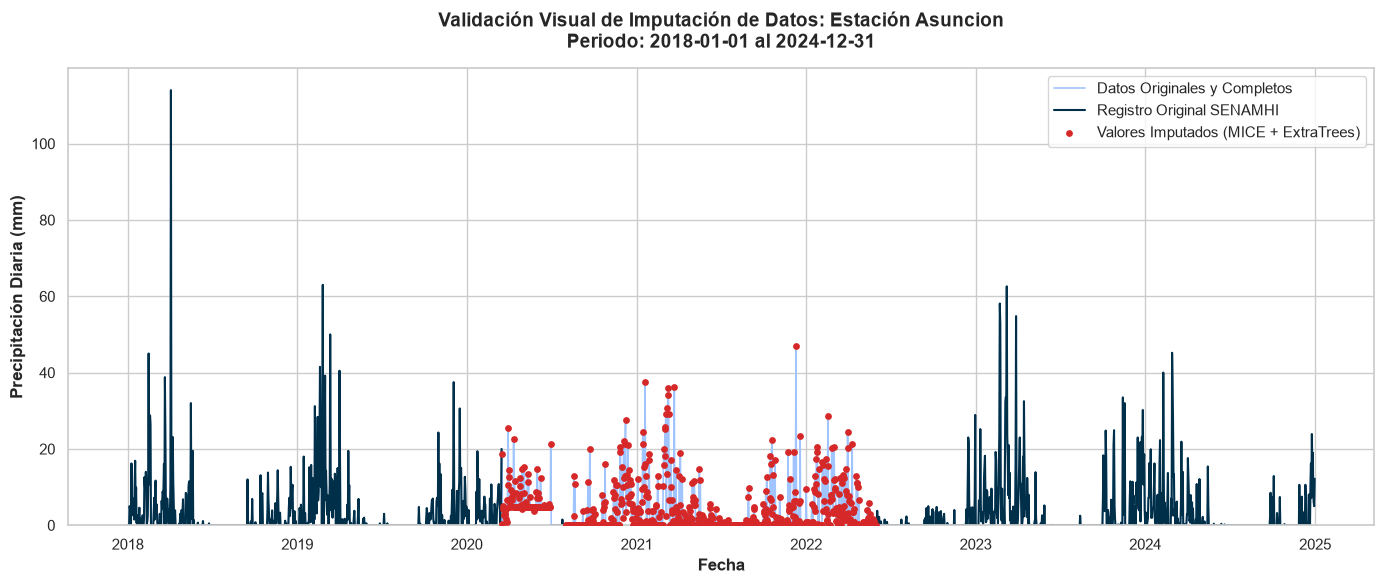

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Parámetros de visualización (estación y rango de fechas)
estacion = 'ASUNCION'  # estación con mayor proporción de vacíos
fecha_inicio = '2018-01-01'
fecha_fin = '2024-12-31'

# 2. Recortar los DataFrames al periodo de interés
# Ambos DataFrames tienen 'FECHA' como índice de tipo datetime
df_raw_zoom = df_clean.loc[fecha_inicio:fecha_fin, estacion]
df_imp_zoom = df_imputed.loc[fecha_inicio:fecha_fin, estacion]

# 3. Aislar estrictamente los datos imputados para pintarlos de otro color
# Condición: Donde el original es nulo (NaN) pero el imputado tiene un valor
mascara_imputados = df_raw_zoom.isna()
solo_imputados = df_imp_zoom[mascara_imputados]

# 4. Configuración del Gráfico
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(14, 6))

# Serie completa (observada + imputada) como línea base en azul claro
ax.plot(df_imp_zoom.index, df_imp_zoom, color='#A0C4FF', linewidth=1.2, label='Datos Originales y Completos', zorder=1)

# Registro original encima, en azul oscuro: los tramos que quedan en celeste son los rellenados
ax.plot(df_raw_zoom.index, df_raw_zoom, color='#003049', linewidth=1.5, label='Registro Original SENAMHI', zorder=2)

# Puntos imputados destacados en rojo
ax.scatter(solo_imputados.index, solo_imputados, color='#D62828', s=15,
           marker='o', label='Valores Imputados (MICE + ExtraTrees)', zorder=3)

# Configuraciones estéticas
ax.set_title(f'Validación Visual de Imputación de Datos: Estación {estacion.capitalize()}\nPeriodo: {fecha_inicio} al {fecha_fin}',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Fecha', fontsize=12, fontweight='bold')
ax.set_ylabel('Precipitación Diaria (mm)', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()


# Extracción de Datos PISCO v03

**PISCO** (Peruvian Interpolated data of SENAMHI's Climatological and hydrological Observations) es un producto grillado de precipitación que combina observaciones terrestres con estimaciones satelitales, cubriendo todo el territorio peruano de forma continua desde 1981. Se usa como fuente complementaria a los pluviómetros físicos porque no tiene vacíos de registro, y sirve como variable auxiliar (forzante espacial) para el modelo predictivo.

En este bloque se abre el archivo NetCDF `PISCOp_dv03.nc` con `xarray` y, para cada estación pluviométrica, se extrae la serie temporal del píxel más cercano a sus coordenadas (`method='nearest'`). Como el NetCDF no trae fechas explícitas, se reconstruye el eje temporal asumiendo que la primera observación corresponde al 1981-01-01, y luego se recorta el rango 2000-2025 para que coincida con el periodo de estudio de los pluviómetros.

**Limitación reconocida:** esta reconstrucción de fechas por posición es una suposición no verificable directamente contra un metadato de tiempo explícito del NetCDF. Como control indirecto, más adelante (bloque de Dispersión OBS-PISCO) se compara día a día la precipitación satelital contra la observada; un desfase de fechas incorrecto se manifestaría como una correlación anómalamente baja y sistemática entre ambas fuentes, cosa que no se observa. Adicionalmente, en esta celda se valida que los valores extraídos estén dentro de un rango físicamente plausible, para detectar valores de relleno (*fill values*) de la grilla que a veces aparecen en píxeles de borde.


In [19]:
import xarray as xr
import pandas as pd

# 1. Definición del diccionario espacial (lon, lat) por estación
estaciones_coords = {
    'AUGUSTO_WEBERBAUER': (-78.49, -7.17),
    'ASUNCION': (-78.52, -7.33),
    'JESUS': (-78.39, -7.25),
    'LA_ENCANADA': (-78.33, -7.12),
    'NAMORA': (-78.33, -7.20),
    'SAN_JUAN': (-78.49, -7.30)
}
assert list(estaciones_coords.keys()) == ESTACIONES, (
    "Las claves de estaciones_coords deben coincidir exactamente con ESTACIONES"
)

# 2. Carga del archivo NetCDF
# PISCOp_dv03.nc es publico y gratuito: dataset PISCOp v3.0 (Gutierrez &
# Lavado-Casimiro, 2025), DOI 10.6084/m9.figshare.32411886 -> descarga el
# archivo 'PISCOp_d.nc' (precipitacion diaria, ~1.5 GB) y renombralo a
# PISCOp_dv03.nc en datos/, o ajusta la ruta de abajo.
ruta_PISCO = '../datos/PISCOp_dv03.nc'
ds_pisco = xr.open_dataset(ruta_PISCO)

# 3. DataFrame vacío
df_pisco = pd.DataFrame()

# Umbral físico razonable para precipitación diaria en la sierra norte del Perú.
# Un valor por encima de esto (o negativo) es más probable que sea un fill-value
# de la grilla que un evento real, y se reporta para inspección manual.
UMBRAL_FISICO_MAX_MM = 300.0

# 4. Extracción iterativa y conversión de tiempo
for estacion, (lon, lat) in estaciones_coords.items():

    # Extracción usando el método del vecino más cercano
    serie_pixel = ds_pisco.sel(longitude=lon, latitude=lat, method='nearest')['precipitation']

    # Convertir a DataFrame
    df_temp = serie_pixel.to_dataframe().reset_index()

    # Crear un rango de fechas real desde 1981-01-01
    fechas_reales = pd.date_range(start='1981-01-01', periods=len(df_temp), freq='D')
    df_temp['FECHA'] = fechas_reales

    # Limpiar y estructurar (nos quedamos solo con la fecha y la precipitación)
    df_temp = df_temp[['FECHA', 'precipitation']]
    df_temp.set_index('FECHA', inplace=True)
    df_temp.columns = [estacion]

    # --- Chequeo de sanidad física ---
    valores = df_temp[estacion]
    n_negativos = (valores < 0).sum()
    n_extremos = (valores > UMBRAL_FISICO_MAX_MM).sum()
    if n_negativos > 0 or n_extremos > 0:
        print(f"[AVISO] {estacion}: {n_negativos} valores negativos, "
              f"{n_extremos} valores > {UMBRAL_FISICO_MAX_MM} mm/día "
              f"(posibles fill-values de la grilla PISCO, revisar píxel seleccionado).")

    # Unir columnas
    if df_pisco.empty:
        df_pisco = df_temp
    else:
        df_pisco = df_pisco.join(df_temp, how='outer')

# 5. Filtrado del Rango Temporal
# Se recorta el rango temporal del estudio
df_pisco = df_pisco.loc['2000-01-01':'2025-12-31']

# Imprimir validación
print("--- Extracción Exitosa de Datos PISCO ---")
print(df_pisco.head())
print(df_pisco.tail())
print("\n--- Rango físico por estación (verificación post-filtro) ---")
print(df_pisco.describe().loc[['min', 'max']])



--- Extracción Exitosa de Datos PISCO ---
            AUGUSTO_WEBERBAUER  ASUNCION     JESUS  LA_ENCANADA    NAMORA  \
FECHA                                                                       
2000-01-01            3.391534  2.891655  0.129957     1.035263  1.035263   
2000-01-02            0.103505  0.000000  0.010817     0.162570  0.162570   
2000-01-03            0.015730  0.163876  0.022701     0.021216  0.021216   
2000-01-04            0.032735  0.000000  0.015218     0.006511  0.006511   
2000-01-05            0.154752  0.878328  0.026181     0.000000  0.000000   

            SAN_JUAN  
FECHA                 
2000-01-01  2.069021  
2000-01-02  0.130634  
2000-01-03  0.030857  
2000-01-04  0.088273  
2000-01-05  0.000000  
            AUGUSTO_WEBERBAUER  ASUNCION     JESUS  LA_ENCANADA    NAMORA  \
FECHA                                                                       
2025-12-27            0.002489  0.003180  0.000000     0.013741  0.013741   
2025-12-28            0.04

# Uniendo los DataFrames (Observado + PISCO)

Se combinan en un único DataFrame (`df_final`) los datos observados ya imputados (`df_imputed`, sufijo `_OBS`) y los datos satelitales de PISCO (`df_pisco`, sufijo `_PISCO`), usando la fecha como clave de unión (`join(how='inner')`). El resultado final tiene 12 columnas (6 estaciones x 2 fuentes) y solo conserva los días presentes en ambas fuentes. Este DataFrame combinado es la base sobre la que se construirán las variables de entrada del modelo: la idea es que el modelo aprenda a corregir/complementar el registro observado usando el patrón espacial que aporta PISCO.

Esta unión es una simple concatenación por fecha (no involucra ajustar ningún modelo estadístico), por lo que no introduce fuga de datos por sí misma.


In [20]:
import pandas as pd

# 1. Asegurar que ambos DataFrames tengan 'FECHA' como índice en formato datetime
df_imputed.index = pd.to_datetime(df_clean.index)
df_pisco.index = pd.to_datetime(df_pisco.index)

# 2. Agregar sufijos para identificar la fuente de los datos
# _OBS = Datos Observados (Pluviómetros físicos)
# _PISCO = Datos Satelitales/Interpolados (SENAMHI)
df_imputed_renombrado = df_imputed.add_suffix('_OBS')
df_pisco_renombrado = df_pisco.add_suffix('_PISCO')

# 3. Unir ambos DataFrames usando el índice temporal ('FECHA')
# 'inner' asegura que solo nos quedemos con los días que existan en ambos registros
df_final = df_imputed_renombrado.join(df_pisco_renombrado, how='inner')

# Imprimir información para validar
print("--- DataFrame Final Consolidado ---")
print(f"Número total de filas (días): {len(df_final)}")
print(f"Número total de columnas (características): {len(df_final.columns)}")
print(df_final.describe().isnull().sum())
print(df_final.describe().isnull())


--- DataFrame Final Consolidado ---
Número total de filas (días): 9497
Número total de columnas (características): 12
AUGUSTO_WEBERBAUER_OBS      0
ASUNCION_OBS                0
JESUS_OBS                   0
LA_ENCANADA_OBS             0
NAMORA_OBS                  0
SAN_JUAN_OBS                0
AUGUSTO_WEBERBAUER_PISCO    0
ASUNCION_PISCO              0
JESUS_PISCO                 0
LA_ENCANADA_PISCO           0
NAMORA_PISCO                0
SAN_JUAN_PISCO              0
dtype: int64
       AUGUSTO_WEBERBAUER_OBS  ASUNCION_OBS  JESUS_OBS  LA_ENCANADA_OBS  \
count                   False         False      False            False   
mean                    False         False      False            False   
std                     False         False      False            False   
min                     False         False      False            False   
25%                     False         False      False            False   
50%                     False         False      False     

# Dispersión de Datos por Estación (Observado vs. PISCO)

Antes de usar PISCO como variable de entrada del modelo, es necesario cuantificar qué tan bien representa la lluvia realmente medida en cada estación. Se grafican dos vistas complementarias:

1. **Matriz de dispersión 1:1**: compara el valor diario observado contra el valor PISCO del mismo día y estación. La línea roja discontinua es la recta ideal $y=x$; entre más cerca estén los puntos de esa línea (y más alto el $R^2$), mejor es el ajuste de PISCO para esa estación.
2. **Distribución del error residual** (celda siguiente): calcula el error `PISCO - OBS` por estación y lo visualiza en boxplots, permitiendo ver si PISCO tiende a sobreestimar o subestimar la lluvia real de forma sistemática (sesgo) en cada estación.

Esta comparación también sirve como control indirecto de la suposición de fecha de inicio 1981-01-01 hecha en la extracción de PISCO: si las fechas estuvieran desalineadas, el $R^2$ punto-grilla sería sistemáticamente bajo en todas las estaciones.


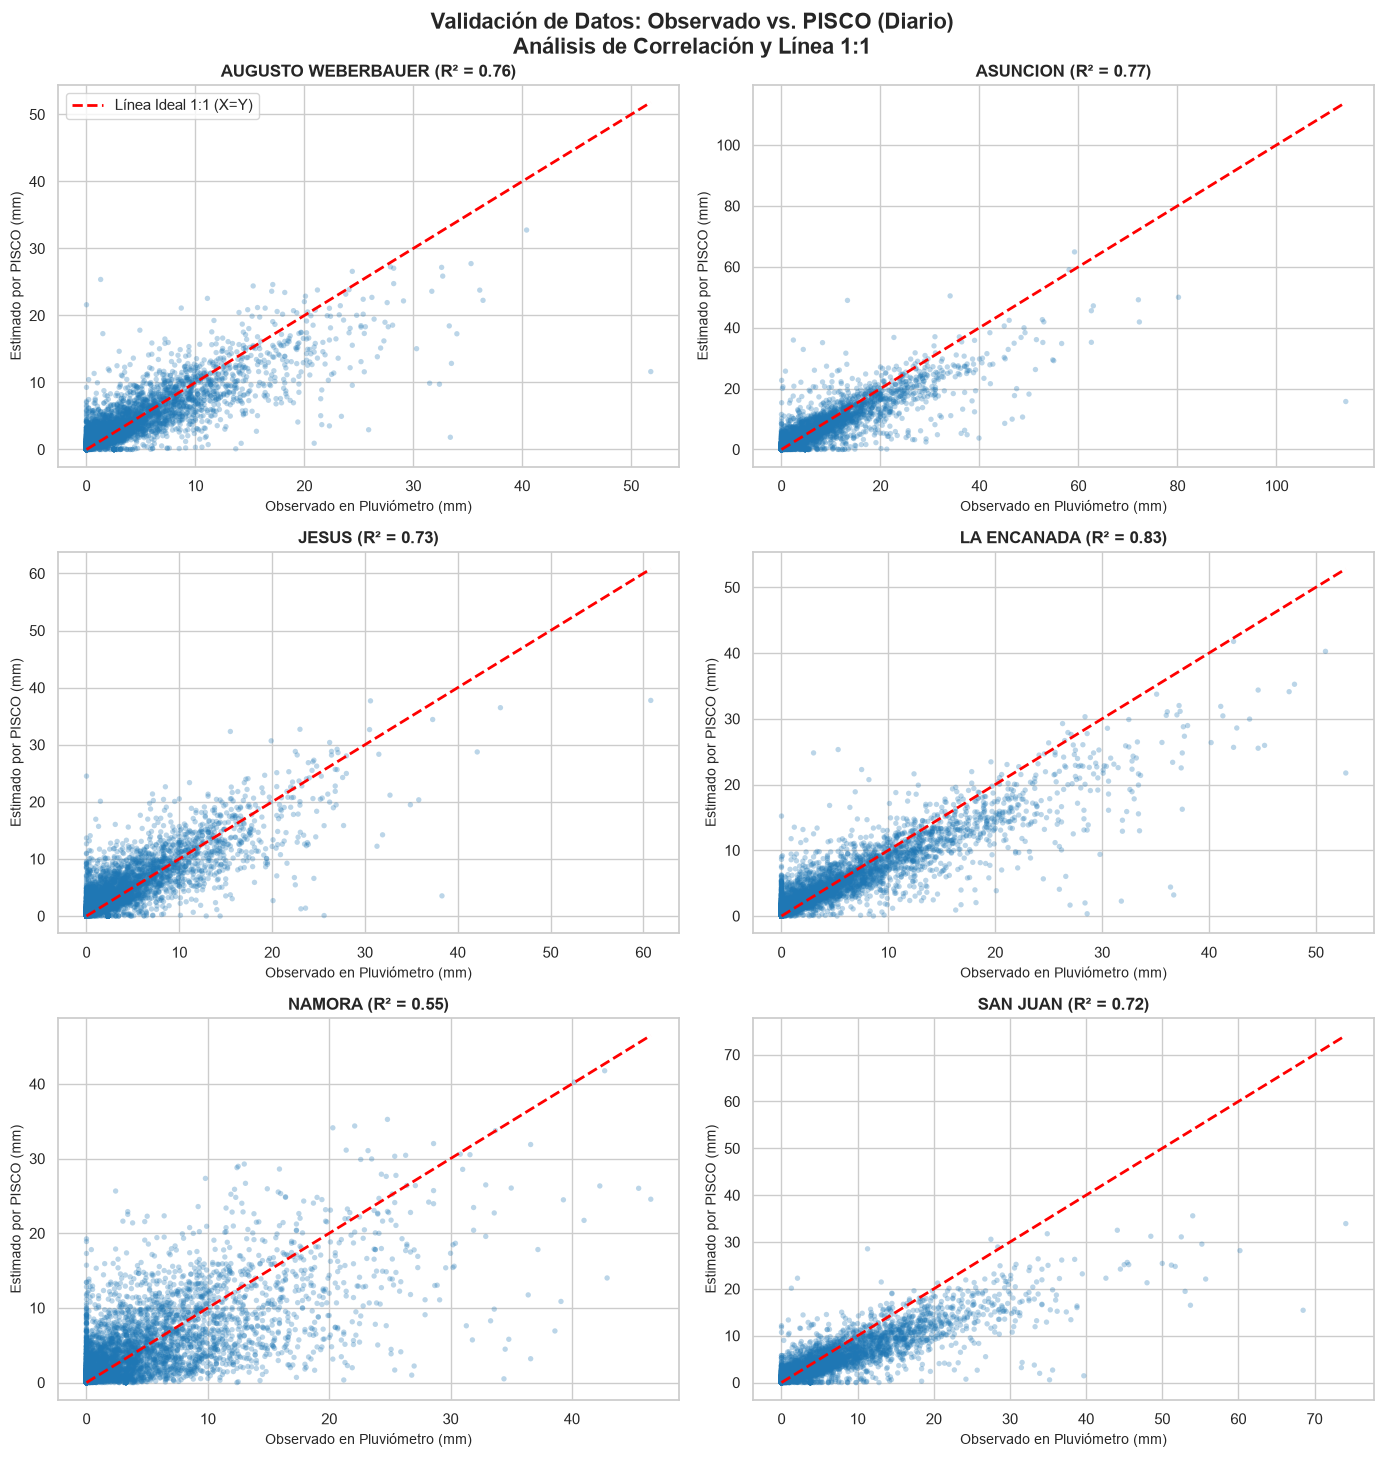

In [21]:
from sklearn.metrics import r2_score

# Reutilizamos la lista canónica de estaciones definida al inicio del notebook
estaciones = ESTACIONES

# ==============================================================================
# GRÁFICO 1: Matriz de Dispersión 1:1 (Scatter Plots)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig1, axes1 = plt.subplots(nrows=3, ncols=2, figsize=(14, 15))
axes1 = axes1.flatten()

for i, estacion in enumerate(estaciones):
    ax = axes1[i]
    col_obs = f"{estacion}_OBS"
    col_pisco = f"{estacion}_PISCO"

    # Extraer datos y eliminar NaNs si los hubiera quedado alguno
    x = df_final[col_obs].dropna()
    y = df_final[col_pisco].dropna()

    # Alinear índices para asegurar comparación del mismo día
    comunes = x.index.intersection(y.index)
    x = x.loc[comunes]
    y = y.loc[comunes]

    # Calcular R2 (Coeficiente de determinación)
    r2 = r2_score(x, y)

    # Graficar nube de puntos con transparencia (alpha) para ver densidad
    ax.scatter(x, y, alpha=0.3, color='#1F77B4', edgecolor='none', s=15)

    # Dibujar la línea ideal 1:1 (Recta a 45 grados)
    max_val = max(x.max(), y.max())
    ax.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Línea Ideal 1:1 (X=Y)')

    # Estética
    ax.set_title(f'{estacion.replace("_", " ")} (R² = {r2:.2f})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Observado en Pluviómetro (mm)', fontsize=10)
    ax.set_ylabel('Estimado por PISCO (mm)', fontsize=10)

    if i == 0:
        ax.legend(loc='upper left')

fig1.suptitle('Validación de Datos: Observado vs. PISCO (Diario)\nAnálisis de Correlación y Línea 1:1',
              fontsize=16, fontweight='bold', y=0.97)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()


/var/folders/lv/8y8zq6zx4h5b678x7x87dnyr0000gn/T/ipykernel_25725/2494350529.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Estación', y='Error (mm)', data=df_errores_melted,
/var/folders/lv/8y8zq6zx4h5b678x7x87dnyr0000gn/T/ipykernel_25725/2494350529.py:27: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([e.replace('_', '\n') for e in estaciones])


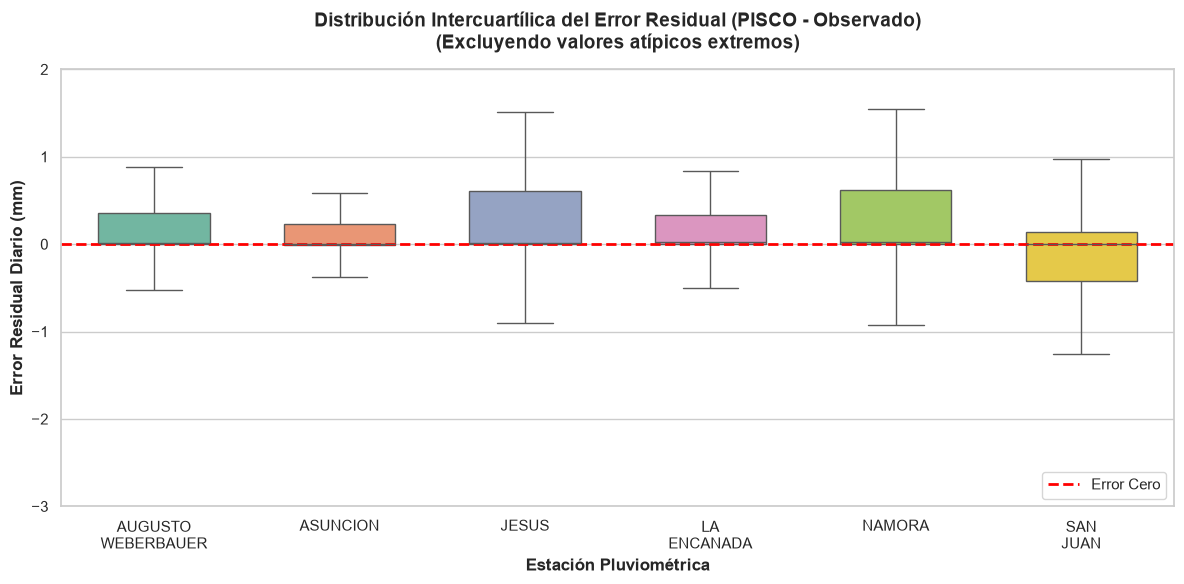

In [22]:
# Calcular el error para cada estación (PISCO - OBS)
df_errores = pd.DataFrame(index=df_final.index)

for estacion in estaciones:
    df_errores[estacion] = df_final[f"{estacion}_PISCO"] - df_final[f"{estacion}_OBS"]

# Reestructurar los datos (Melt) para que Seaborn pueda hacer el boxplot fácilmente
df_errores_melted = df_errores.melt(var_name='Estación', value_name='Error (mm)')
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 6))

# Boxplot con showfliers=False para ocultar los puntos que aplastan la gráfica
sns.boxplot(x='Estación', y='Error (mm)', data=df_errores_melted,
            palette='Set2', showfliers=False, ax=ax, width=0.6)

# Línea de referencia
ax.axhline(0, color='red', linestyle='--', linewidth=2, label='Error Cero')

# Límites del eje Y ajustados al rango intercuartílico (-3 a 2 mm) para que las cajas se vean con claridad
ax.set_ylim(-3, 2)

# Estética
ax.set_title('Distribución Intercuartílica del Error Residual (PISCO - Observado)\n(Excluyendo valores atípicos extremos)',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Estación Pluviométrica', fontsize=12, fontweight='bold')
ax.set_ylabel('Error Residual Diario (mm)', fontsize=12, fontweight='bold')
ax.set_xticklabels([e.replace('_', '\n') for e in estaciones])
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()


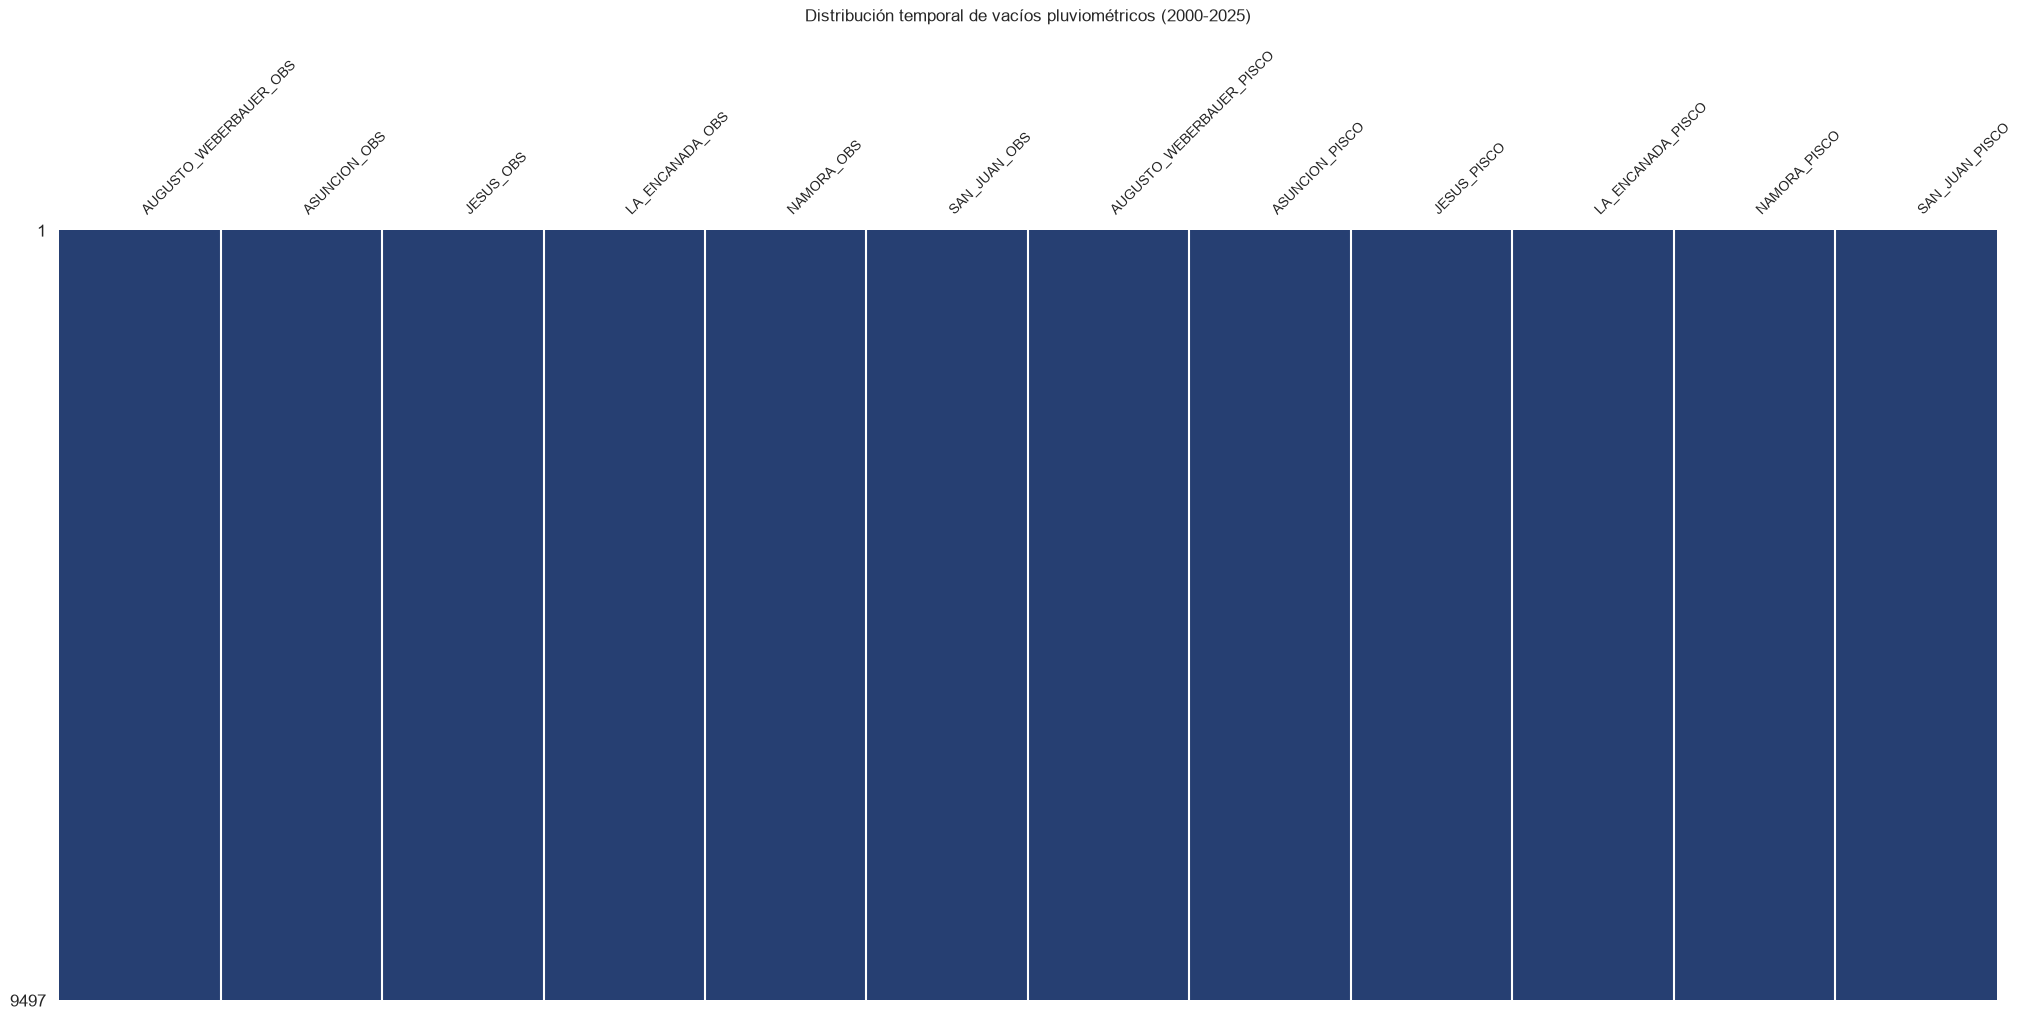

In [23]:
# Distribución temporal de los vacíos en el conjunto integrado (Observado + PISCO)
msno.matrix(df_final, sparkline=False, fontsize=10, color=(0.15, 0.25, 0.45))
plt.title('Distribución temporal de vacíos pluviométricos (2000-2025)', fontsize=12, pad=20)
plt.show()


# Normalización de los Datos (Observado y PISCO)

Las redes neuronales (LSTM) convergen mejor y de forma más estable cuando las variables de entrada están en rangos acotados y comparables entre sí. Se aplica un escalado en dos etapas:

1. **RobustScaler**: centra y escala usando el rango intercuartílico (percentiles 25-75) en lugar de la media/desviación estándar o el máximo absoluto. Esto es clave en series de precipitación porque los eventos de tormenta extrema (outliers) distorsionarían un escalado clásico (`StandardScaler`) o de mínimos-máximos aplicado directamente.
2. **MinMaxScaler**: tras mitigar el efecto de los outliers, se reescala todo al rango $[0, 1]$, que es el rango de entrada recomendado para las capas LSTM.

Ambos escaladores (`robust_scaler`, `minmax_scaler`) se conservan porque serán necesarios más adelante para **invertir la escala** de las predicciones del modelo y recuperar milímetros de precipitación reales.

**Prevención de fuga de datos:** al igual que con el imputador MICE, ajustar estos escaladores con la serie completa filtraría estadísticas del período de prueba (percentiles, mínimo y máximo) hacia el preprocesamiento. Por eso se ajustan **solo con el mismo 70% cronológico de entrenamiento**, y se aplican (`transform`) a la serie completa. Nuevamente esto es seguro porque `RobustScaler`/`MinMaxScaler` son transformaciones fila-independientes: cada fila se reescala usando únicamente las estadísticas ya aprendidas, sin mirar otras filas.


In [24]:
from sklearn.preprocessing import RobustScaler, MinMaxScaler

# Corte cronológico consistente con el usado para el imputador MICE.
# Se recalcula sobre df_final (no se reutiliza el índice de df_clean) porque,
# tras el join con PISCO, el número de filas podría diferir levemente.
idx_train_scaler = int(len(df_final) * 0.70)
print(f"Ajustando los escaladores solo con los primeros {idx_train_scaler} días "
      f"({df_final.index[0].date()} a {df_final.index[idx_train_scaler - 1].date()})")

# 1. Manejo de Outliers mediante RobustScaler a TODAS las variables
# Esto mitiga los picos de tormentas extremas tanto en mediciones físicas como satelitales
# Centra y escala los datos basándose en percentiles (rango intercuartílico), no en el máximo absoluto
robust_scaler = RobustScaler(quantile_range=(25.0, 75.0))
robust_scaler.fit(df_final.iloc[:idx_train_scaler])
df_robust = pd.DataFrame(robust_scaler.transform(df_final),
                         columns=df_final.columns,
                         index=df_final.index)

# 2. Escalamiento MinMax final para la capa de entrada de la LSTM
# Ahora el MinMax dejará las 12 columnas estrictamente en el rango [0, 1] *en el tramo de entrenamiento*;
# val/test pueden caer levemente fuera de [0,1] si superan el máximo histórico de entrenamiento,
# lo cual es esperado y correcto (evita que el escalador "sepa" el máximo real del futuro).
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
minmax_scaler.fit(df_robust.iloc[:idx_train_scaler])
df_escalado = pd.DataFrame(minmax_scaler.transform(df_robust),
                           columns=df_robust.columns,
                           index=df_robust.index)

print("--- Validación de la Transformación Final ---")
print("Valores nulos post-escalamiento:", df_escalado.isnull().sum())
print("Valores nulos post-escalamiento:", df_escalado.isnull().sum().sum())
display(df_escalado.describe())


Ajustando los escaladores solo con los primeros 6647 días (2000-01-01 a 2018-03-13)
--- Validación de la Transformación Final ---
Valores nulos post-escalamiento: AUGUSTO_WEBERBAUER_OBS      0
ASUNCION_OBS                0
JESUS_OBS                   0
LA_ENCANADA_OBS             0
NAMORA_OBS                  0
SAN_JUAN_OBS                0
AUGUSTO_WEBERBAUER_PISCO    0
ASUNCION_PISCO              0
JESUS_PISCO                 0
LA_ENCANADA_PISCO           0
NAMORA_PISCO                0
SAN_JUAN_PISCO              0
dtype: int64
Valores nulos post-escalamiento: 0


,AUGUSTO_WEBERBAUER_OBS,ASUNCION_OBS,JESUS_OBS,LA_ENCANADA_OBS,NAMORA_OBS,SAN_JUAN_OBS,AUGUSTO_WEBERBAUER_PISCO,ASUNCION_PISCO,JESUS_PISCO,LA_ENCANADA_PISCO,NAMORA_PISCO,SAN_JUAN_PISCO
count,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000,9497.000000
mean,0.037959,0.039185,0.031550,0.056323,0.053338,0.040020,0.070901,0.043923,0.059821,0.059965,0.059965,0.061944
std,0.079651,0.085385,0.069027,0.118716,0.108827,0.082560,0.126369,0.085058,0.109367,0.106158,0.106158,0.111281
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000173,0.000000,0.000000,0.000355,0.000355,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.009242,0.003131,0.005232,0.008587,0.008587,0.006830
75%,0.038610,0.038653,0.029605,0.056842,0.058065,0.043185,0.086690,0.050070,0.072998,0.075099,0.075099,0.076579
max,1.000000,1.421446,1.000000,1.111579,1.000000,1.000000,1.180488,1.000000,1.000000,1.000000,1.000000,1.000000


# Integración del Seno y Coseno Anual (Forzamiento Astronómico)

Se añaden dos variables cíclicas derivadas del día del año ($\sin$ y $\cos$ con periodo 365.25 días) como "reloj estacional continuo". Esto es una técnica estándar para codificar estacionalidad en modelos de series temporales: a diferencia de usar el número de mes o día del año directamente (que crea un salto artificial de diciembre a enero), la representación seno/coseno es continua y cíclica, permitiendo que el modelo aprenda patrones estacionales (época de lluvias vs. estiaje) sin depender exclusivamente de la memoria de corto plazo de la ventana temporal. El gráfico siguiente superpone estas ondas trigonométricas con la precipitación observada de una estación para verificar visualmente que la fase de las ondas se alinea con el calendario real.

Estas variables son una función determinística de la fecha (no se "ajustan" con datos), por lo que no hay riesgo de fuga al calcularlas sobre la serie completa.


--- Auditoría del Tensor Base ---
Dimensiones de la matriz: (9497, 14)
Variables activas: ['AUGUSTO_WEBERBAUER_OBS', 'ASUNCION_OBS', 'JESUS_OBS', 'LA_ENCANADA_OBS', 'NAMORA_OBS', 'SAN_JUAN_OBS', 'AUGUSTO_WEBERBAUER_PISCO', 'ASUNCION_PISCO', 'JESUS_PISCO', 'LA_ENCANADA_PISCO', 'NAMORA_PISCO', 'SAN_JUAN_PISCO', 'Sen_Estacional', 'Cos_Estacional']


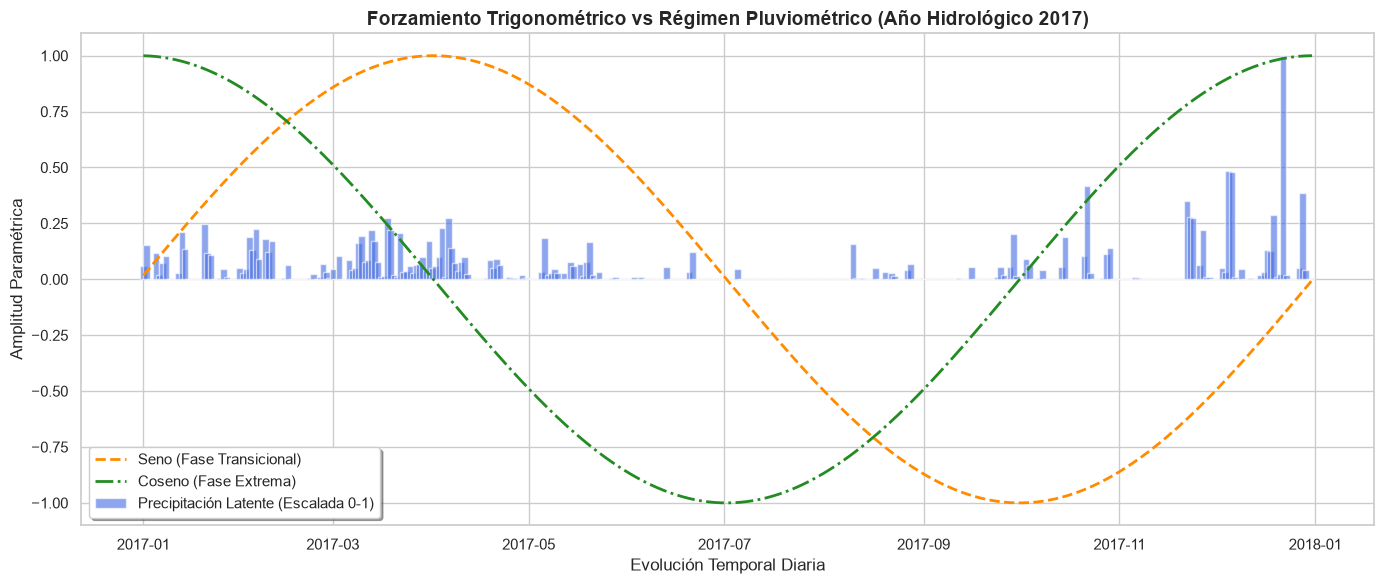

In [25]:
# Inyección del forzamiento astronómico (reloj estacional continuo)
dias_del_ano = df_escalado.index.dayofyear
df_escalado['Sen_Estacional'] = np.sin(2 * np.pi * dias_del_ano / 365.25)
df_escalado['Cos_Estacional'] = np.cos(2 * np.pi * dias_del_ano / 365.25)

print("--- Auditoría del Tensor Base ---")
print(f"Dimensiones de la matriz: {df_escalado.shape}")
print(f"Variables activas: {df_escalado.columns.tolist()}")

# ==============================================================================
# MÓDULO VISUAL: ALINEACIÓN ASTRONÓMICO-PLUVIOMÉTRICA
# ==============================================================================
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Se aísla un año (2017) para la claridad visual
df_plot = df_escalado.loc['2017-01-01':'2017-12-31']

# Trazado de las ondas trigonométricas
plt.plot(df_plot.index, df_plot['Sen_Estacional'], label='Seno (Fase Transicional)', color='darkorange', linestyle='--', linewidth=2)
plt.plot(df_plot.index, df_plot['Cos_Estacional'], label='Coseno (Fase Extrema)', color='forestgreen', linestyle='-.', linewidth=2)

# Superposición de la precipitación observada (se usa barra para emular un hietograma)
# Se selecciona la estación Augusto Weberbauer como representante espacial
plt.bar(df_plot.index, df_plot['AUGUSTO_WEBERBAUER_OBS'], label='Precipitación Latente (Escalada 0-1)', color='royalblue', alpha=0.6, width=2)

plt.title('Forzamiento Trigonométrico vs Régimen Pluviométrico (Año Hidrológico 2017)', fontsize=14, fontweight='bold')
plt.ylabel('Amplitud Paramétrica', fontsize=12)
plt.xlabel('Evolución Temporal Diaria', fontsize=12)
plt.legend(loc='lower left', frameon=True, shadow=True)
plt.tight_layout()
plt.show()


# Reconstrucción Tensorial (Teorema de Takens)

El **teorema de Takens** (reconstrucción del espacio de fase por retraso temporal) establece que el estado de un sistema dinámico puede reconstruirse a partir de una ventana de sus observaciones pasadas. Se aplica aquí construyendo, para cada día objetivo, un tensor 3D `X` con los últimos 15 días (`lookback_window`) de las 14 variables (6 estaciones OBS + 6 PISCO + seno + coseno), y un vector `Y` con la precipitación real de las 6 estaciones para el día siguiente.

La partición en entrenamiento/validación/prueba es **estrictamente cronológica** (70%/15%/15%, sin mezclar aleatoriamente) para respetar la flecha del tiempo y evaluar la capacidad real de generalización a futuro, evitando fuga de información (*data leakage*) desde el futuro hacia el pasado. Adicionalmente se aplana (`reshape`) el mismo tensor a una matriz 2D, ya que XGBoost —a diferencia de la LSTM— no maneja secuencias temporales de forma nativa y requiere que cada día previo se represente como una columna/característica independiente.

**Nota sobre consistencia del corte:** este 70%/85% se calcula sobre el número de *secuencias* (`len(X_seq)`), que es ligeramente menor que el número de días (`len(df_escalado) - lookback_window`). El corte resultante cae, como máximo, `lookback_window` = 15 días antes o después del corte usado para ajustar el imputador y los escaladores en los bloques anteriores — una diferencia despreciable frente a los ~25 años de la serie, y que no reintroduce fuga porque las estadísticas de imputación/escalado ya fueron ajustadas exclusivamente con datos anteriores a ambos cortes.


In [26]:
# ==============================================================================
# RECONSTRUCCIÓN TENSORIAL MULTIVARIADA
# ==============================================================================

def crear_secuencias_integradas(datos, pasos_previos, n_estaciones):
    """
    Genera el espacio de fase topológico.
    X: Tensor 3D con el historial espacial y satelital.
    Y: Vector de la verdad terreno (estaciones) del día objetivo.
    """
    X, Y = [], []
    for i in range(len(datos) - pasos_previos):
        # Capturamos la matriz completa (14 columnas) de los últimos 'n' días
        X.append(datos[i:(i + pasos_previos), :])
        # Aislamos exclusivamente las primeras 6 columnas (las estaciones OBS) para el día actual
        Y.append(datos[i + pasos_previos, :n_estaciones])
    return np.array(X), np.array(Y)

# Parámetros del espacio latente
lookback_window = 15
n_estaciones_reales = 6 # AUGUSTO_WEBERBAUER_OBS a SAN_JUAN_OBS
n_caracteristicas_totales = 14 # 6 OBS + 6 PISCO + Sen + Cos

# 1. Generación del Tensor 3D (Extracción de Memoria)
print("--- Generando Hiperespacio Temporal ---")
X_seq, Y_seq = crear_secuencias_integradas(
    df_escalado.values,
    lookback_window,
    n_estaciones_reales
)

print(f"Dimensiones de X_seq (Entrada LSTM): {X_seq.shape}")
print(f"Dimensiones de Y_seq (Objetivo): {Y_seq.shape}")

# 2. Partición Cronológica Estricta (Hold-out Secuencial)
# Fundamento: Respetar la flecha del tiempo para evaluar capacidad de generalización futura.
n_muestras = len(X_seq)
idx_train = int(n_muestras * 0.70)
idx_val = int(n_muestras * 0.85)

# Tensores 3D para la Red Neuronal Recurrente
X_train, Y_train = X_seq[:idx_train], Y_seq[:idx_train]
X_val, Y_val = X_seq[idx_train:idx_val], Y_seq[idx_train:idx_val]
X_test, Y_test = X_seq[idx_val:], Y_seq[idx_val:]

# 3. Aplanamiento Tabular (Flattening) para XGBoost
# XGBoost carece de celdas de estado; requiere que cada día previo sea una característica estática.
X_train_xgb = X_train.reshape(X_train.shape[0], -1)
X_val_xgb = X_val.reshape(X_val.shape[0], -1)
X_test_xgb = X_test.reshape(X_test.shape[0], -1)

print("\n--- Auditoría de Partición para Motores de IA ---")
print(f"LSTM Training Tensor: X={X_train.shape}, Y={Y_train.shape}")
print(f"XGBoost Training Matrix: X={X_train_xgb.shape}")


--- Generando Hiperespacio Temporal ---
Dimensiones de X_seq (Entrada LSTM): (9482, 15, 14)
Dimensiones de Y_seq (Objetivo): (9482, 6)

--- Auditoría de Partición para Motores de IA ---
LSTM Training Tensor: X=(6637, 15, 14), Y=(6637, 6)
XGBoost Training Matrix: X=(6637, 210)


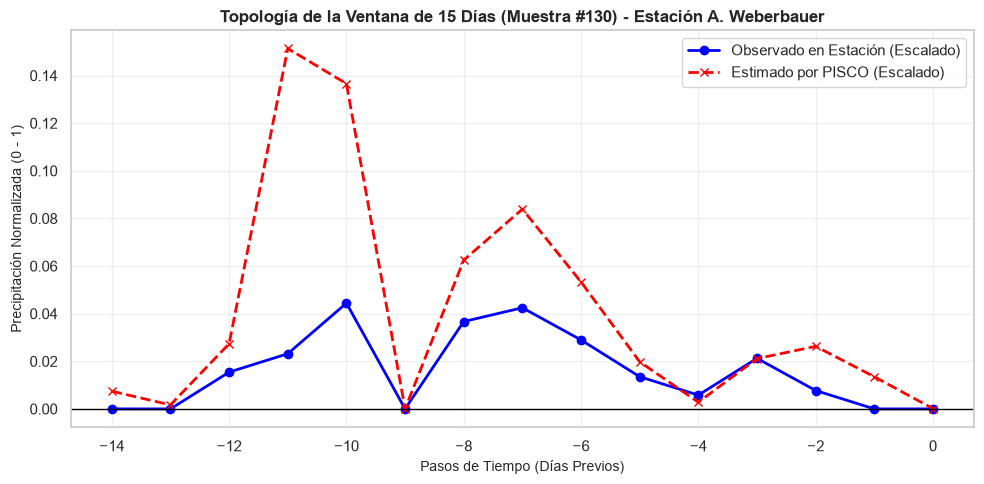

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Aislamos la muestra 130 del tensor de entrenamiento
indice_muestra = 130
matriz_muestra = X_train[indice_muestra]

# Índices de las columnas de df_escalado: 0 es AUGUSTO_WEBERBAUER_OBS, 6 es AUGUSTO_WEBERBAUER_PISCO
obs_weberbauer = matriz_muestra[:, 0]
pisco_weberbauer = matriz_muestra[:, 6]
eje_temporal = np.arange(-14, 1) # Representa los días t-14 hasta t=0

plt.figure(figsize=(10, 5))
plt.plot(eje_temporal, obs_weberbauer, marker='o', color='blue', linewidth=2, label='Observado en Estación (Escalado)')
plt.plot(eje_temporal, pisco_weberbauer, marker='x', color='red', linestyle='dashed', linewidth=2, label='Estimado por PISCO (Escalado)')

plt.title(f'Topología de la Ventana de 15 Días (Muestra #{indice_muestra}) - Estación A. Weberbauer', fontsize=12, fontweight='bold')
plt.xlabel('Pasos de Tiempo (Días Previos)', fontsize=10)
plt.ylabel('Precipitación Normalizada (0 - 1)', fontsize=10)
plt.axhline(0, color='black', linewidth=1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Búsqueda de Hiperparámetros (LSTM y XGBoost)

La metodología (Capítulo III de la tesis) contempla optimizar los hiperparámetros de ambos modelos mediante **validación cruzada con k=5 pliegues**. Aquí se implementa de forma distinta para cada modelo, según su costo computacional:

- **XGBoost** entrena en segundos incluso con cientos de árboles, por lo que se aplica la validación cruzada **k=5** con `TimeSeriesSplit(n_splits=5)`, y no con un `KFold` aleatorio: un k-fold estándar barajaría los datos y permitiría que pliegues de entrenamiento contengan fechas posteriores a las de validación, otra forma de fuga temporal. `TimeSeriesSplit` respeta el orden cronológico en cada pliegue. La búsqueda se hace con `RandomizedSearchCV` (más eficiente que una grilla exhaustiva) sobre `max_depth`, `learning_rate`, `n_estimators`, `subsample` y `colsample_bytree`.

- **LSTM** requiere reentrenar la red completa (hasta 150 épocas) por cada combinación de hiperparámetros evaluada. Repetir esto 5 veces (una por pliegue) para cada combinación de una grilla es computacionalmente inviable en el equipo utilizado (MacBook con 8 GB de RAM), una limitación de cómputo que la tesis reconoce de forma explícita. Como adaptación documentada, se evalúa un conjunto reducido de configuraciones (1 o 2 capas ocultas, entre 32 y 128 neuronas) mediante **validación simple** (*hold-out* con el conjunto de validación ya definido) y un presupuesto de entrenamiento reducido (40 épocas, `patience=8`) solo en la fase de búsqueda. La configuración ganadora se reentrena después con el presupuesto completo (150 épocas, `patience=15`) para el modelo final.

Ambas funciones de pérdida —la asimétrica de la LSTM y su equivalente en XGBoost— se definen en la celda siguiente para que estén disponibles tanto en la búsqueda como en el entrenamiento final.


In [28]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
import tensorflow.keras.backend as K
from tensorflow.keras.callbacks import EarlyStopping

# Semilla de TensorFlow (separada de np.random/random, fijadas al inicio del notebook)
tf.random.set_seed(SEMILLA)

# --- Función de Pérdida Hidrológica Asimétrica (LSTM) ---
def mse_asimetrico(y_true, y_pred):
    error = y_true - y_pred
    # Penaliza x2 cuando hay subestimación (el modelo predice menos de lo que llovió)
    penalizacion = tf.where(error > 0, 2.0, 1.0)
    return K.mean(penalizacion * K.square(error))

# --- Objetivo Asimétrico Equivalente para XGBoost ---
# XGBoost minimiza L = peso * (y_true - y_pred)^2, donde peso=2 si el modelo
# subestima (y_true > y_pred) y peso=1 si sobrestima. Un objetivo personalizado en
# XGBoost debe devolver el gradiente y el hessiano de la pérdida respecto a y_pred:
#   dL/dy_pred = -2*peso*(y_true - y_pred) = 2*peso*(y_pred - y_true)
#   d2L/dy_pred2 = 2*peso
# Esto es matemáticamente equivalente a mse_asimetrico, solo expresado en la forma
# gradiente/hessiano que requiere la API de objetivos personalizados de XGBoost.
def objetivo_asimetrico_xgb(y_true, y_pred):
    residual = y_true - y_pred
    peso = np.where(residual > 0, 2.0, 1.0)
    grad = 2.0 * peso * (y_pred - y_true)
    hess = 2.0 * peso * np.ones_like(y_true)
    return grad, hess


def construir_modelo_lstm(capas, lookback_window, n_caracteristicas, n_salidas):
    """
    Construye una LSTM apilada: Dropout(0.2) entre capas recurrentes intermedias,
    ninguna capa de Dropout entre la última LSTM y la capa Dense de salida
    (ReLU, no negativa por definición física).
    """
    modelo = Sequential()
    modelo.add(Input(shape=(lookback_window, n_caracteristicas)))
    for i, unidades in enumerate(capas):
        es_ultima_capa_recurrente = (i == len(capas) - 1)
        modelo.add(LSTM(unidades, return_sequences=not es_ultima_capa_recurrente, activation='tanh'))
        if not es_ultima_capa_recurrente:
            modelo.add(Dropout(0.2))
    modelo.add(Dense(n_salidas, activation='relu'))
    return modelo


In [29]:
# --- Búsqueda reducida de arquitectura LSTM (validación simple, presupuesto acotado) ---
configuraciones_lstm = [
    {'capas': [64, 32], 'nombre': 'Base (64-32)'},
    {'capas': [32],     'nombre': 'Compacta (32)'},
    {'capas': [128, 64], 'nombre': 'Ancha (128-64)'},
]

EPOCAS_BUSQUEDA = 40
PATIENCE_BUSQUEDA = 8

resultados_busqueda_lstm = []
print("--- Búsqueda de Hiperparámetros LSTM (presupuesto reducido) ---")
for config in configuraciones_lstm:
    tf.random.set_seed(SEMILLA)
    modelo_prueba = construir_modelo_lstm(config['capas'], lookback_window,
                                           n_caracteristicas_totales, n_estaciones_reales)
    modelo_prueba.compile(optimizer=Adam(learning_rate=0.001), loss=mse_asimetrico)

    freno_busqueda = EarlyStopping(monitor='val_loss', patience=PATIENCE_BUSQUEDA,
                                    restore_best_weights=True, verbose=0)
    historial = modelo_prueba.fit(
        X_train, Y_train,
        validation_data=(X_val, Y_val),
        epochs=EPOCAS_BUSQUEDA,
        batch_size=32,
        callbacks=[freno_busqueda],
        verbose=0
    )
    mejor_val_loss = float(np.min(historial.history['val_loss']))
    resultados_busqueda_lstm.append({
        'Configuración': config['nombre'],
        'Capas': config['capas'],
        'Mejor val_loss': mejor_val_loss
    })
    print(f"  {config['nombre']}: val_loss={mejor_val_loss:.5f}")

df_busqueda_lstm = pd.DataFrame(resultados_busqueda_lstm).sort_values('Mejor val_loss').reset_index(drop=True)
display(df_busqueda_lstm)

capas_ganadoras = df_busqueda_lstm.iloc[0]['Capas']
print(f"\nConfiguración LSTM ganadora: {df_busqueda_lstm.iloc[0]['Configuración']} -> capas={capas_ganadoras}")


--- Búsqueda de Hiperparámetros LSTM (presupuesto reducido) ---


2026-10-08 01:59:43.634385: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple A18 Pro
2026-10-08 01:59:43.634431: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-10-08 01:59:43.634436: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-10-08 01:59:43.634464: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-10-08 01:59:43.634472: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


2026-10-08 01:59:44.180539: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


  Base (64-32): val_loss=0.01099


  Compacta (32): val_loss=0.01131


  Ancha (128-64): val_loss=0.01090


,Configuración,Capas,Mejor val_loss
0,Ancha (128-64),"[128, 64]",0.010903
1,Base (64-32),"[64, 32]",0.010989
2,Compacta (32),[32],0.011311



Configuración LSTM ganadora: Ancha (128-64) -> capas=[128, 64]


In [30]:
# --- Búsqueda de Hiperparámetros XGBoost: k=5 real vía TimeSeriesSplit + RandomizedSearchCV ---
import xgboost as xgb
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

espacio_busqueda_xgb = {
    'estimator__max_depth': [2, 3, 4, 5],
    'estimator__learning_rate': [0.005, 0.01, 0.03, 0.05],
    'estimator__n_estimators': [150, 300, 450],
    'estimator__subsample': [0.7, 0.8, 0.9, 1.0],
    'estimator__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
}

modelo_xgb_base = MultiOutputRegressor(
    xgb.XGBRegressor(objective='reg:squarederror', random_state=SEMILLA)
)

# TimeSeriesSplit respeta el orden cronológico en cada pliegue (a diferencia de un
# KFold aleatorio), evitando que un pliegue de entrenamiento contenga fechas
# posteriores a su propio pliegue de validación.
busqueda_xgb = RandomizedSearchCV(
    estimator=modelo_xgb_base,
    param_distributions=espacio_busqueda_xgb,
    n_iter=8,
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_root_mean_squared_error',
    random_state=SEMILLA,
    n_jobs=1,  # secuencial: prioriza estabilidad de memoria sobre velocidad en 8GB RAM
    verbose=1,
)

print("--- Búsqueda de Hiperparámetros XGBoost (RandomizedSearchCV, k=5, TimeSeriesSplit) ---")
busqueda_xgb.fit(X_train_xgb, Y_train)

mejores_params_xgb = {
    k.replace('estimator__', ''): v for k, v in busqueda_xgb.best_params_.items()
}
print(f"\nMejores hiperparámetros XGBoost: {mejores_params_xgb}")
print(f"Mejor score (neg RMSE promedio, k=5): {busqueda_xgb.best_score_:.4f}")


--- Búsqueda de Hiperparámetros XGBoost (RandomizedSearchCV, k=5, TimeSeriesSplit) ---
Fitting 5 folds for each of 8 candidates, totalling 40 fits



Mejores hiperparámetros XGBoost: {'subsample': 0.8, 'n_estimators': 150, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
Mejor score (neg RMSE promedio, k=5): -0.0778


# Construcción y Entrenamiento de la Red LSTM

Se entrena la arquitectura **LSTM (Long Short-Term Memory)** ganadora de la búsqueda de hiperparámetros del bloque anterior (`capas_ganadoras`), apropiada para capturar dependencias temporales en la ventana de 15 días construida previamente. Cada capa LSTM intermedia va seguida de `Dropout(0.2)` para mitigar sobreajuste, y la red termina en una capa densa con activación `ReLU` que garantiza salidas no negativas (físicamente válido para precipitación).

La **función de pérdida asimétrica** (`mse_asimetrico`, definida en el bloque de búsqueda de hiperparámetros) penaliza el doble el error cuando el modelo *subestima* la lluvia real, frente a cuando la sobreestima. Esto responde a una consideración hidrológica: para fines de gestión de riesgo (crecidas, alertas), es más costoso subestimar un evento de lluvia intensa que sobreestimarlo. El mismo criterio se implementa también en XGBoost (bloque siguiente) mediante un objetivo personalizado, de modo que ambos modelos se entrenan bajo un criterio de error comparable y la comparación final es más justa.

El entrenamiento usa `EarlyStopping` monitoreando la pérdida de validación, con el presupuesto completo (150 épocas, `patience=15`) — a diferencia de la fase de búsqueda, que usó un presupuesto reducido solo para comparar arquitecturas.


Entrenando arquitectura final LSTM con capas=[128, 64]
--- Iniciando Entrenamiento LSTM Final ---
Epoch 1/150


  1/208 ━━━━━━━━━━━━━━━━━━━━ 3:02 882ms/step - loss: 0.0235

  5/208 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0264   

 10/208 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0259

 15/208 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0244

...

201/208 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0106

206/208 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0105

208/208 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0105 - val_loss: 0.0118


Epoch 29: early stopping


Restoring model weights from the end of the best epoch: 14.


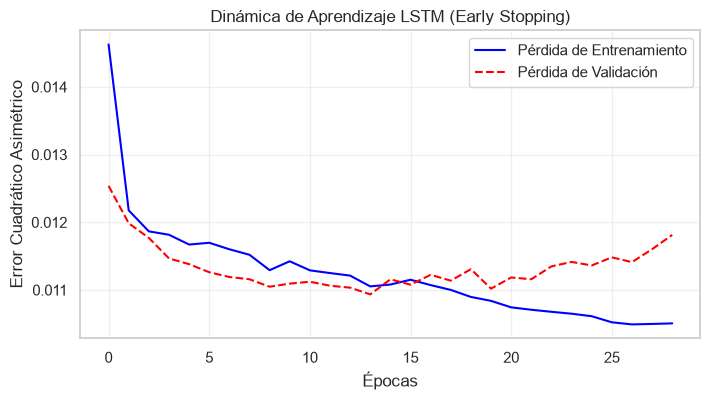

In [31]:
# 1. Topología de la Red Neuronal Recurrente (arquitectura ganadora de la búsqueda)
print(f"Entrenando arquitectura final LSTM con capas={capas_ganadoras}")
modelo_lstm = construir_modelo_lstm(capas_ganadoras, lookback_window,
                                     n_caracteristicas_totales, n_estaciones_reales)

# 2. Compilación
modelo_lstm.compile(optimizer=Adam(learning_rate=0.001), loss=mse_asimetrico)

# 3. Control de Sobreajuste (Early Stopping) - presupuesto completo
freno = EarlyStopping(
    monitor='val_loss',
    patience=15,
    min_delta=1e-4,
    restore_best_weights=True,
    verbose=1
)

# 4. Ejecución del Descenso de Gradiente
print("--- Iniciando Entrenamiento LSTM Final ---")
historial_lstm = modelo_lstm.fit(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    epochs=150,
    batch_size=32,
    callbacks=[freno],
    verbose=1
)

# 5. Gráfica de Convergencia
plt.figure(figsize=(8, 4))
plt.plot(historial_lstm.history['loss'], label='Pérdida de Entrenamiento', color='blue')
plt.plot(historial_lstm.history['val_loss'], label='Pérdida de Validación', color='red', linestyle='--')
plt.title('Dinámica de Aprendizaje LSTM (Early Stopping)')
plt.xlabel('Épocas')
plt.ylabel('Error Cuadrático Asimétrico')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Construcción y Entrenamiento de XGBoost

Como modelo de comparación (*benchmark*) frente a la LSTM, se entrena un ensamble de **XGBoost** (Gradient Boosting de árboles), envuelto en `MultiOutputRegressor` para predecir simultáneamente las 6 estaciones (XGBoost nativo solo predice una salida por modelo). Al no procesar secuencias, recibe la versión aplanada 2D del tensor construido en el bloque de reconstrucción tensorial (`X_train_xgb`), donde cada uno de los 15 días previos aporta sus 14 variables como columnas independientes.

Los hiperparámetros (`max_depth`, `learning_rate`, `n_estimators`, `subsample`, `colsample_bytree`) son los ganadores de la búsqueda `RandomizedSearchCV` + `TimeSeriesSplit(5)` del bloque anterior, en vez de valores fijados a mano.

**Objetivo asimétrico:** se usa `objetivo_asimetrico_xgb` (definido en el bloque de búsqueda de hiperparámetros) como función objetivo de cada `XGBRegressor`, en vez del `reg:squarederror` estándar. Esto replica matemáticamente la misma penalización 2x por subestimación que usa la LSTM, para que la comparación de RMSE/NSE/KGE entre ambas arquitecturas (bloque de evaluación final) no esté sesgada por estar optimizando objetivos distintos.


In [32]:
print("--- Iniciando Entrenamiento XGBoost Final ---")

# 1. Instanciación del Ensamble con los hiperparámetros ganadores de la búsqueda
# y el objetivo asimétrico (paridad de criterio de error con la LSTM)
modelo_xgb = MultiOutputRegressor(
    xgb.XGBRegressor(
        objective=objetivo_asimetrico_xgb,
        eval_metric='rmse',
        random_state=SEMILLA,
        **mejores_params_xgb,
    )
)

# 2. Ejecución del Entrenamiento (Usando las matrices 2D aplanadas)
modelo_xgb.fit(X_train_xgb, Y_train)

print("Entrenamiento XGBoost Finalizado exitosamente.")


--- Iniciando Entrenamiento XGBoost Final ---


Entrenamiento XGBoost Finalizado exitosamente.


# Auditoría Visual del Entrenamiento (LSTM y XGBoost)

Se inspeccionan ambos modelos ya entrenados desde dos ángulos complementarios:

1. **Curva de convergencia de la LSTM**: pérdida de entrenamiento vs. validación por época, marcando el punto óptimo detectado por `EarlyStopping`. Sirve para verificar que el modelo generaliza (ambas curvas descienden juntas) y no memoriza (la curva de validación empieza a subir mientras la de entrenamiento sigue bajando).
2. **Importancia de características de XGBoost**: para la estación Augusto Weberbauer, se extraen y grafican las 15 variables (día x fuente) con mayor `feature_importance`, coloreadas según si provienen de la memoria terrestre (observado), del forzamiento satelital (PISCO) o del reloj estacional (seno/coseno). Esto permite interpretar qué información concreta está usando el modelo de árboles para tomar sus decisiones — algo que la LSTM, al ser una caja más negra, no ofrece directamente.

Las dos celdas siguientes complementan esta auditoría con la visualización explícita de la arquitectura de capas de la LSTM y de árboles individuales de XGBoost.


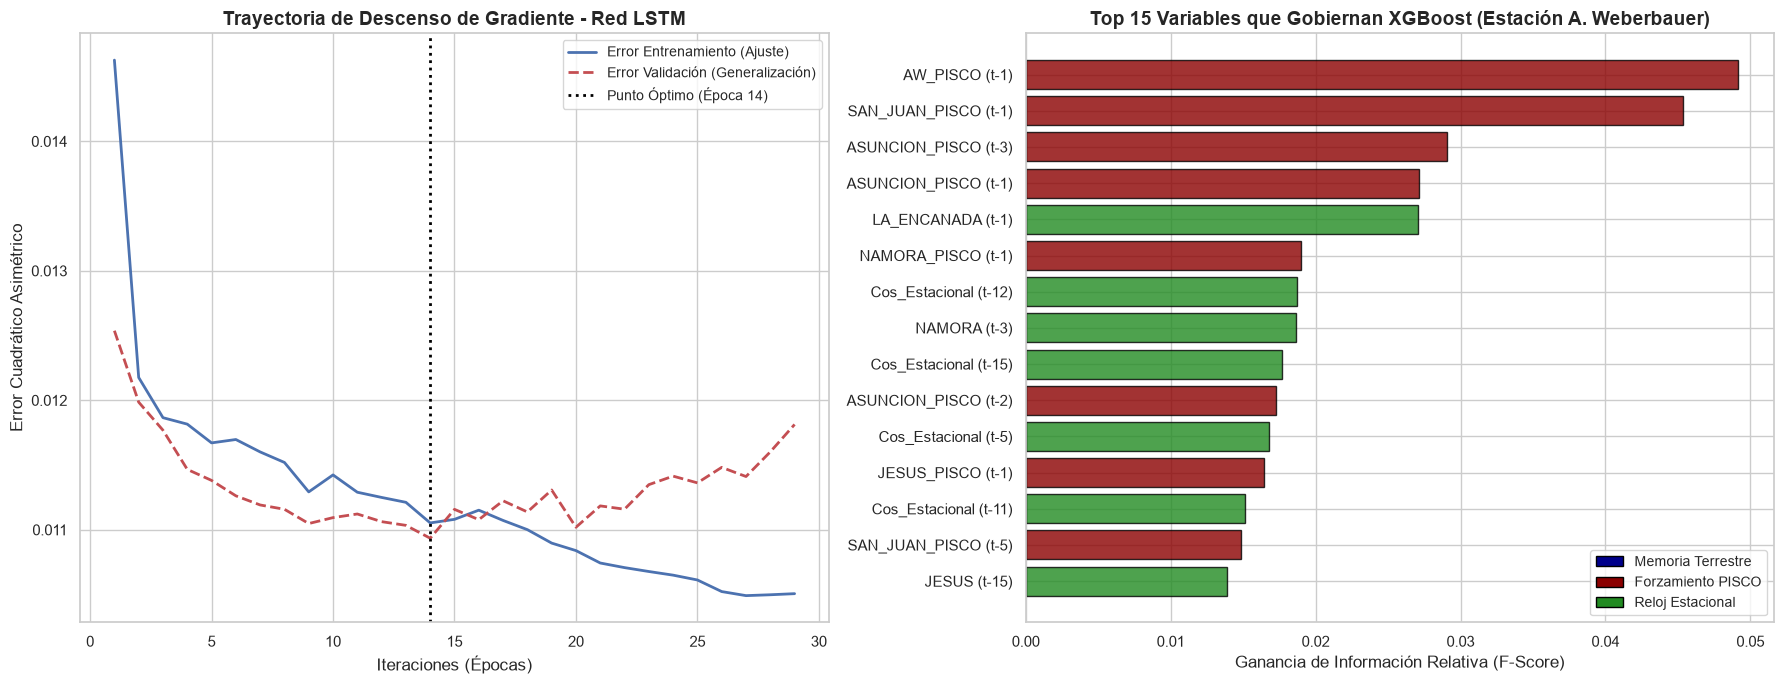

In [33]:
sns.set_theme(style="whitegrid")
fig, ejes = plt.subplots(1, 2, figsize=(18, 7))

# ------------------------------------------------------------------------------
# PANEL 1: Curva de Convergencia LSTM (Aprendizaje Físico vs Memorización)
# ------------------------------------------------------------------------------
# Extraemos el historial de pérdidas
loss_train = historial_lstm.history['loss']
loss_val = historial_lstm.history['val_loss']
epocas = range(1, len(loss_train) + 1)
mejor_epoca = np.argmin(loss_val) + 1 # +1 porque los índices empiezan en 0

ejes[0].plot(epocas, loss_train, 'b-', linewidth=2, label='Error Entrenamiento (Ajuste)')
ejes[0].plot(epocas, loss_val, 'r--', linewidth=2, label='Error Validación (Generalización)')
ejes[0].axvline(mejor_epoca, color='black', linestyle=':', linewidth=2,
                label=f'Punto Óptimo (Época {mejor_epoca})')

ejes[0].set_title('Trayectoria de Descenso de Gradiente - Red LSTM', fontsize=14, fontweight='bold')
ejes[0].set_xlabel('Iteraciones (Épocas)', fontsize=12)
ejes[0].set_ylabel('Error Cuadrático Asimétrico', fontsize=12)
ejes[0].legend(fontsize=10)

# ------------------------------------------------------------------------------
# PANEL 2: Importancia de Características XGBoost (Apertura de Caja Negra)
# ------------------------------------------------------------------------------
# Para auditar XGBoost, extraemos el modelo de la primera estación (Augusto Weberbauer)
xgb_weberbauer = modelo_xgb.estimators_[0]
importancias = xgb_weberbauer.feature_importances_

# Reconstruimos los nombres de las 210 columnas aplanadas para saber a qué día corresponden
nombres_base = df_escalado.columns.tolist()
nombres_aplanados = []
for i in range(15, 0, -1): # Desde t-15 hasta t-1
    for nombre in nombres_base:
        # Limpiamos los nombres para la gráfica
        nombre_limpio = nombre.replace('_OBS', '').replace('AUGUSTO_WEBERBAUER', 'AW')
        nombres_aplanados.append(f"{nombre_limpio} (t-{i})")

# Ordenamos y extraemos el Top 15 de variables más determinantes
TOP_N_IMPORTANCIA = 15
indices_top = np.argsort(importancias)[-TOP_N_IMPORTANCIA:]
importancias_top = importancias[indices_top]
nombres_top = [nombres_aplanados[i] for i in indices_top]

colores = ['darkred' if 'PISCO' in n else 'darkblue' if 'AW' in n else 'forestgreen' for n in nombres_top]

ejes[1].barh(nombres_top, importancias_top, color=colores, edgecolor='black', alpha=0.8)
ejes[1].set_title(f'Top {TOP_N_IMPORTANCIA} Variables que Gobiernan XGBoost (Estación A. Weberbauer)', fontsize=14, fontweight='bold')
ejes[1].set_xlabel('Ganancia de Información Relativa (F-Score)', fontsize=12)

# Leyenda manual para los colores
from matplotlib.patches import Patch
elementos_leyenda = [Patch(facecolor='darkblue', edgecolor='black', label='Memoria Terrestre'),
                     Patch(facecolor='darkred', edgecolor='black', label='Forzamiento PISCO'),
                     Patch(facecolor='forestgreen', edgecolor='black', label='Reloj Estacional')]
ejes[1].legend(handles=elementos_leyenda, loc='lower right', fontsize=10)

plt.tight_layout()
plt.show()


--- 1. Arquitectura Topológica de la Red LSTM ---


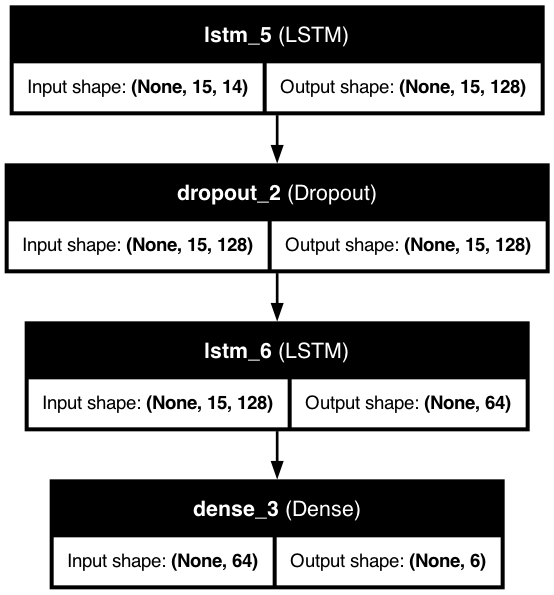


--- 2. Grafo de Decisiones: Árbol Base de XGBoost ---


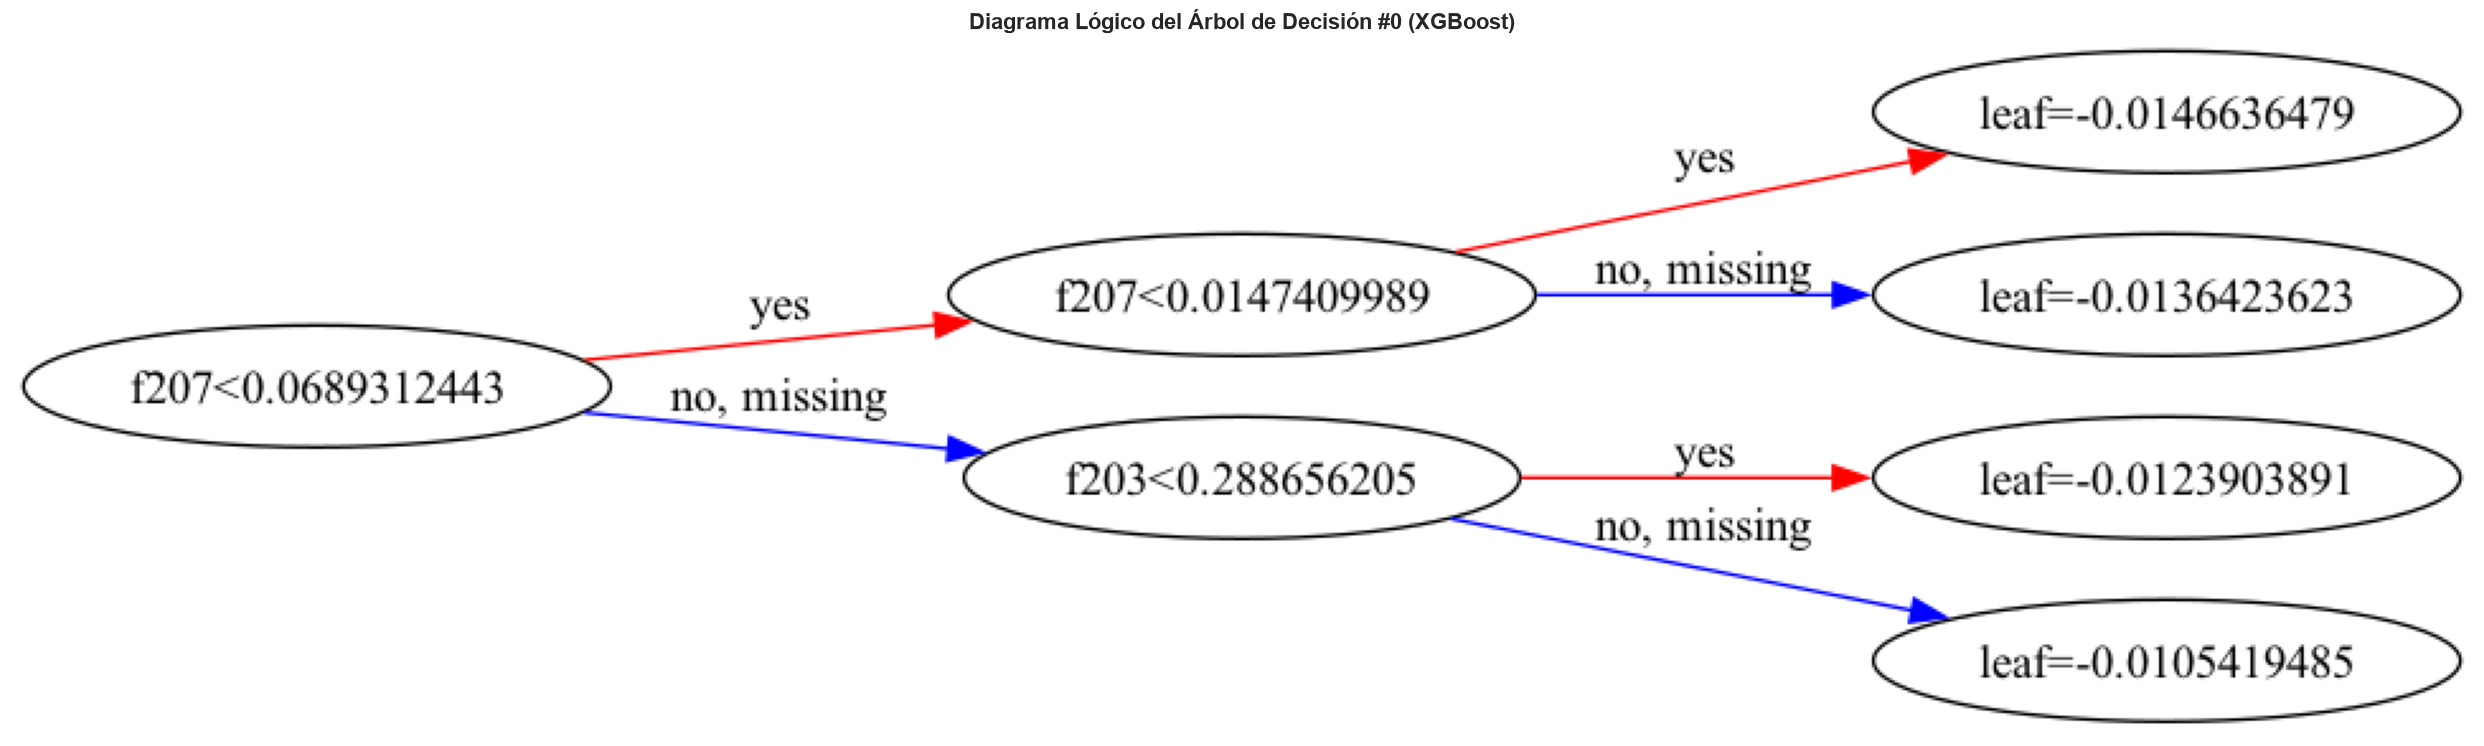

In [34]:
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model
import xgboost as xgb
from IPython.display import Image, display

# ==============================================================================
# RENDERIZADO DE GRAFOS ESTRUCTURALES
# ==============================================================================

print("--- 1. Arquitectura Topológica de la Red LSTM ---")
# Genera un diagrama de bloques del modelo neuronal
# show_shapes=True es crítico: demuestra cómo cambian las dimensiones del tensor en cada capa
ruta_lstm_img = 'figuras_notebook/arquitectura_lstm.png'
plot_model(modelo_lstm, to_file=ruta_lstm_img, show_shapes=True, show_layer_names=True, dpi=96)
display(Image(ruta_lstm_img))

print("\n--- 2. Grafo de Decisiones: Árbol Base de XGBoost ---")
# Extraemos el primer árbol (tree_idx=0) del ensamble de la Estación 0 (Augusto Weberbauer)
arbol_base = modelo_xgb.estimators_[0]

# Configuración del lienzo (se requiere tamaño masivo por la ramificación)
fig, ax = plt.subplots(figsize=(25, 15))

# rankdir='LR' dibuja el árbol de Izquierda a Derecha para mejor lectura
xgb.plot_tree(arbol_base, tree_idx=0, ax=ax, rankdir='LR')

plt.title('Diagrama Lógico del Árbol de Decisión #0 (XGBoost)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


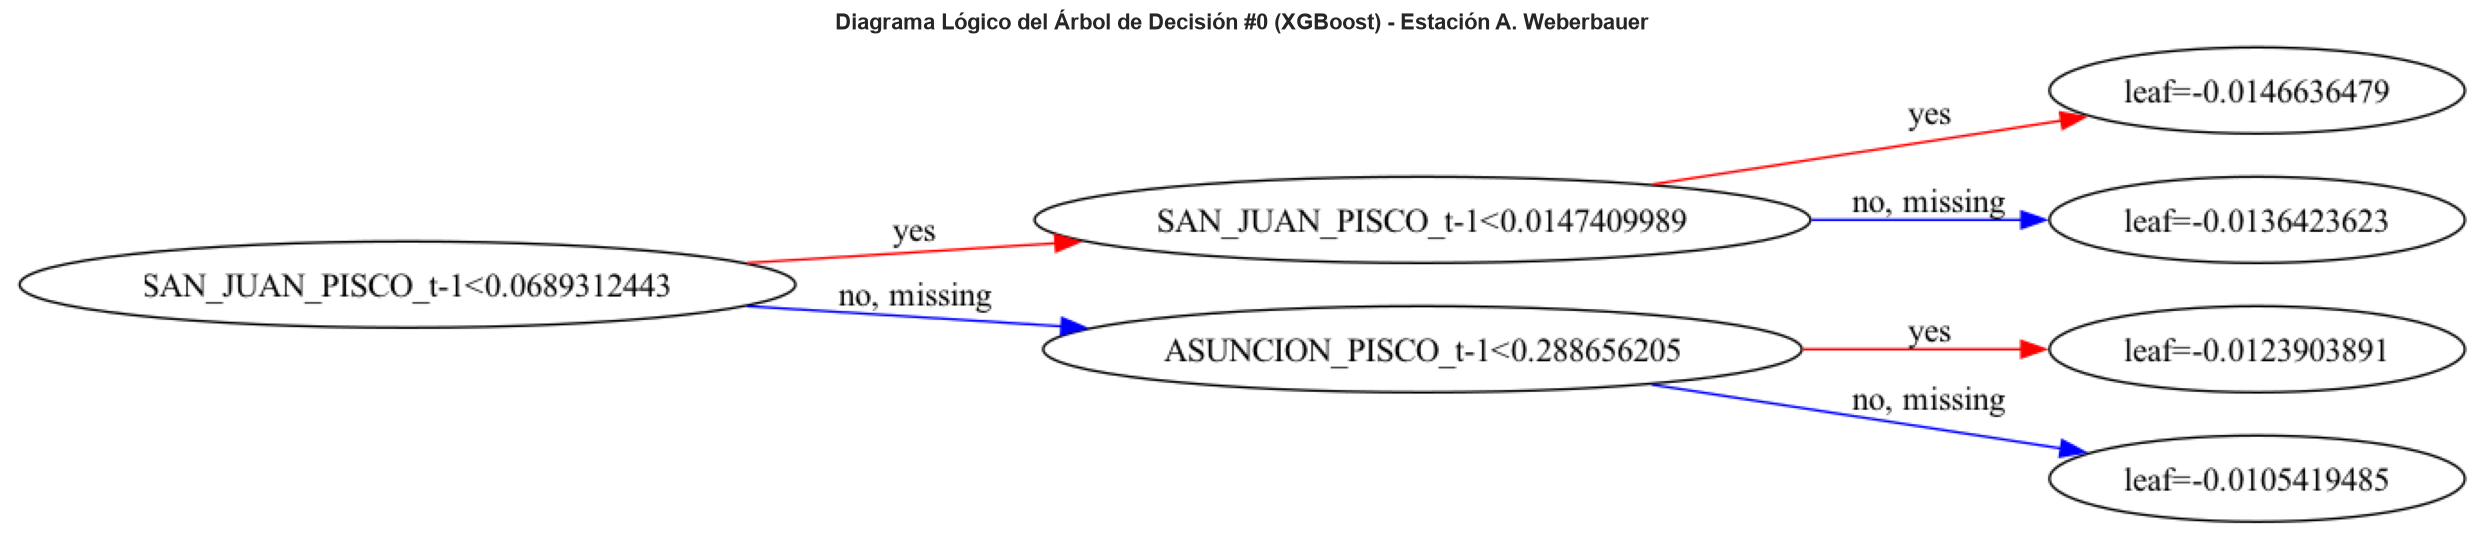

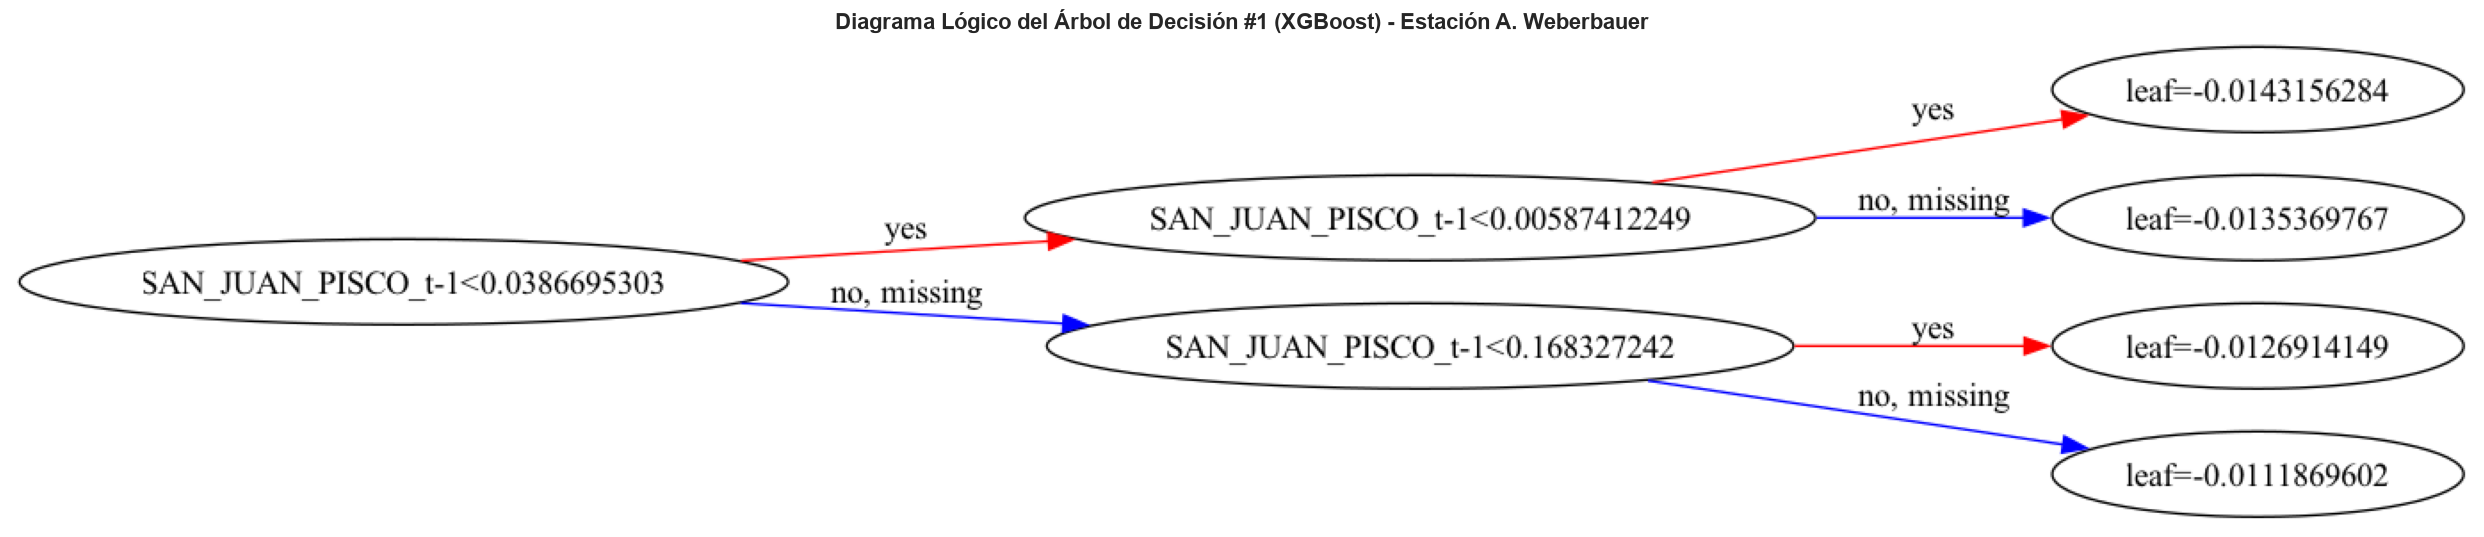

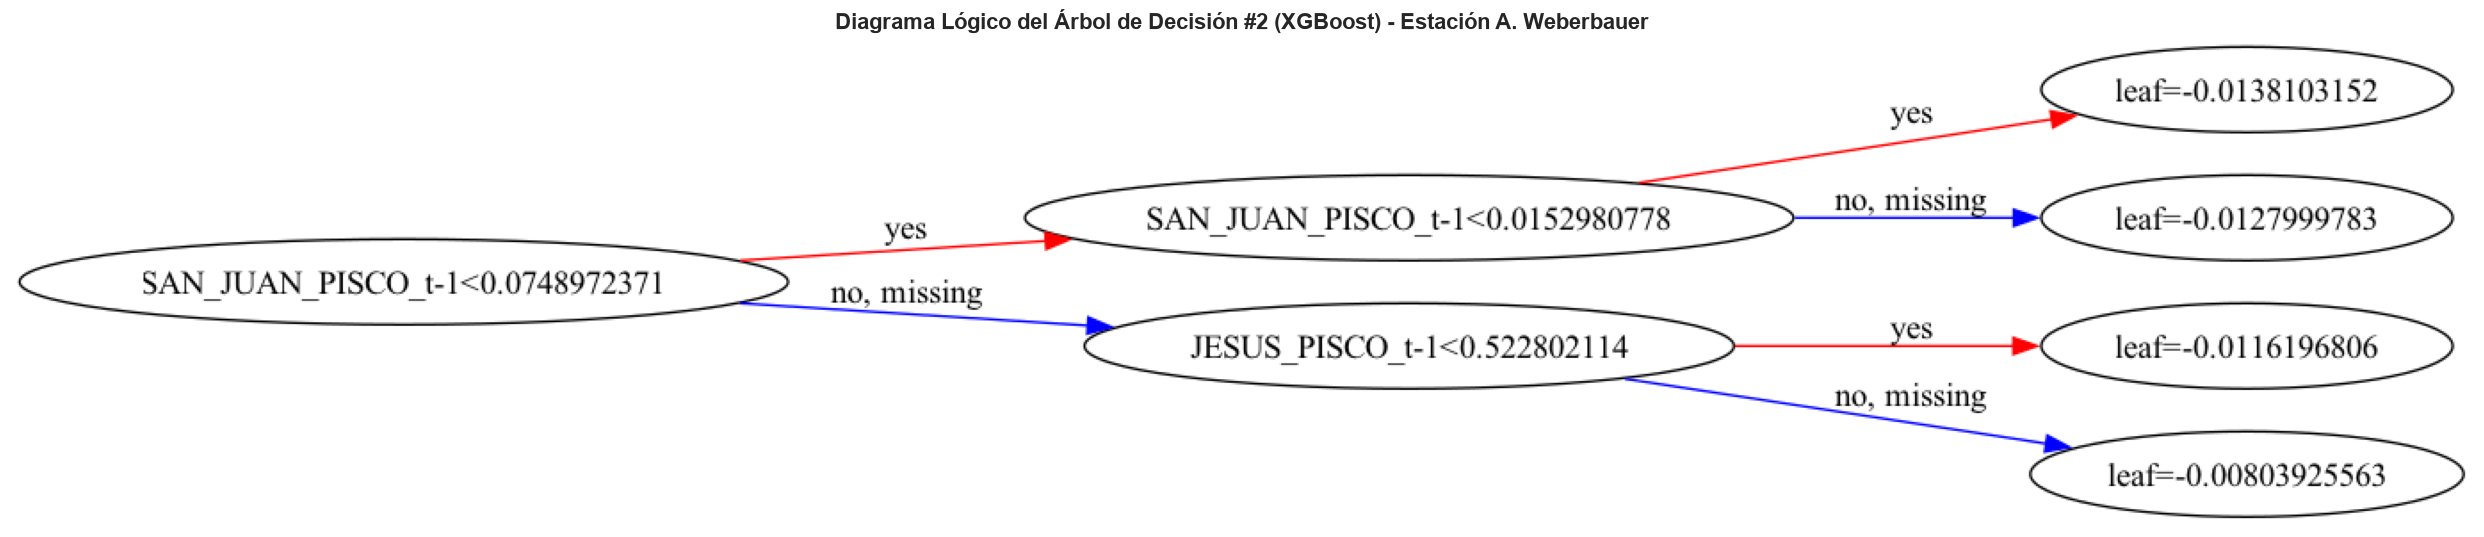

In [35]:
import matplotlib.pyplot as plt
import xgboost as xgb

# 1. Reconstrucción de la Nomenclatura Tabular
nombres_base = df_escalado.columns.tolist()
nombres_aplanados = []
# XGBoost aplanó los datos desde el día más antiguo (t-15) hasta ayer (t-1)
for i in range(15, 0, -1):
    for nombre in nombres_base:
        nombre_limpio = nombre.replace('_OBS', '')
        nombres_aplanados.append(f"{nombre_limpio}_t-{i}")

# 2. Inyección de Nombres al Árbol Específico
# Extraemos el estimador de la primera estación
arbol_weberbauer = modelo_xgb.estimators_[0]

# Le forzamos los nombres de las características a las estructuras internas del modelo
arbol_weberbauer.get_booster().feature_names = nombres_aplanados

# 3. Renderizado Optimizado para los primeros N árboles
num_trees_to_plot = 3 # Número de árboles a graficar

for tree_idx in range(num_trees_to_plot):
    fig, ax = plt.subplots(figsize=(25, 12)) # Lienzo apaisado para mejor lectura
    xgb.plot_tree(
        arbol_weberbauer,
        tree_idx=tree_idx,
        ax=ax,
        rankdir='LR'
    )

    plt.title(f'Diagrama Lógico del Árbol de Decisión #{tree_idx} (XGBoost) - Estación A. Weberbauer', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Cálculo de Métricas Finales (Conjunto de Prueba)

Evaluación definitiva de ambos modelos sobre el **conjunto de prueba** (`X_test`/`Y_test`), nunca visto durante entrenamiento, validación ni búsqueda de hiperparámetros. Antes de calcular métricas, las predicciones (que están en escala $[0,1]$) se **desescalan** (`invertir_escala`) revirtiendo primero el `MinMaxScaler` y luego el `RobustScaler`, para recuperar valores físicos en mm/día; cualquier valor negativo residual producto de errores de coma flotante se recorta a 0.

Se reportan tres métricas estándar en hidrología (Moriasi et al., 2007), calculadas para **las 6 estaciones**:

- **RMSE** (Root Mean Squared Error): error típico en mm/día; entre más bajo, mejor.
- **NSE** (Nash-Sutcliffe Efficiency): mide qué tan bien el modelo predice frente a usar simplemente la media observada como predicción. $NSE=1$ es ajuste perfecto; $NSE \le 0$ indica que el modelo no supera a predecir la media.
- **KGE** (Kling-Gupta Efficiency): descompone el desempeño en correlación ($r$), sesgo de variabilidad ($\alpha$) y sesgo de magnitud ($\beta$); al igual que NSE, $KGE=1$ es óptimo.

La estación **Augusto Weberbauer** se conserva además como caso de estudio detallado (hietograma y curva de excedencia en el bloque siguiente), por ser la estación con el registro histórico más largo y completo, pero la tabla resumen de esta celda cubre las 6 estaciones para sustentar la comparación LSTM vs. XGBoost planteada en la hipótesis de la tesis.


In [36]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error

# ==============================================================================
# INFERENCIA DEFINITIVA Y EVALUACIÓN FÍSICA (CONJUNTO DE PRUEBA) — 6 ESTACIONES
# ==============================================================================
print("--- Evaluación sobre el conjunto de prueba ---")

# 1. Predicción sobre el conjunto de prueba
pred_lstm = modelo_lstm.predict(X_test, verbose=0)
pred_xgb = modelo_xgb.predict(X_test_xgb)

# 2. Inversión del escalado de las predicciones
def invertir_escala(predicciones_6_cols, scaler_minmax, scaler_robust):
    """
    Invierte el escalado de predicciones de 6 columnas. Los escaladores se ajustaron
    con 12 columnas (6 OBS + 6 PISCO), por lo que las predicciones se insertan en una
    matriz auxiliar de ceros con esa dimensión antes de aplicar inverse_transform.
    """
    # Número de columnas con las que se ajustó el escalador (12: 6 OBS + 6 PISCO;
    # Sen/Cos no pasan por el escalador)
    cols_esperadas = scaler_minmax.n_features_in_
    cols_predichas = predicciones_6_cols.shape[1]

    # Matriz auxiliar de ceros para MinMax
    dummy_minmax = np.zeros((len(predicciones_6_cols), cols_esperadas))
    dummy_minmax[:, :cols_predichas] = predicciones_6_cols # Se insertan las predicciones
    inv_minmax = scaler_minmax.inverse_transform(dummy_minmax)

    # Matriz auxiliar de ceros para Robust
    dummy_robust = np.zeros((len(predicciones_6_cols), cols_esperadas))
    dummy_robust[:, :cols_predichas] = inv_minmax[:, :cols_predichas]
    inv_final = scaler_robust.inverse_transform(dummy_robust)

    # Retornamos exclusivamente las columnas de lluvia en milímetros
    return inv_final[:, :cols_predichas]

# Inversión del escalado
pred_lstm_fisico = invertir_escala(pred_lstm, minmax_scaler, robust_scaler)
pred_xgb_fisico = invertir_escala(pred_xgb, minmax_scaler, robust_scaler)
obs_test_fisico = invertir_escala(Y_test, minmax_scaler, robust_scaler)

# Restricción física fundamental (Evitar llovizna negativa por errores de coma flotante)
pred_lstm_fisico[pred_lstm_fisico < 0] = 0.0
pred_xgb_fisico[pred_xgb_fisico < 0] = 0.0
obs_test_fisico[obs_test_fisico < 0] = 0.0

# 3. Formulación de Funciones de Eficiencia
def calcular_nse(obs, sim):
    numerador = np.sum((obs - sim)**2)
    denominador = np.sum((obs - np.mean(obs))**2)
    return 1 - (numerador / denominador)

def calcular_kge(obs, sim):
    epsilon = 1e-8
    r = np.corrcoef(obs, sim)[0, 1]
    alpha = np.std(sim) / (np.std(obs) + epsilon)
    beta = np.mean(sim) / (np.mean(obs) + epsilon)
    return 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)

# 4. Cálculo de Resultados para las 6 estaciones
resultados_finales = []
for idx, nombre_col in enumerate(ESTACIONES):
    obs_col = obs_test_fisico[:, idx]
    sim_lstm_col = pred_lstm_fisico[:, idx]
    sim_xgb_col = pred_xgb_fisico[:, idx]

    resultados_finales.append({
        'Estación': nombre_col, 'Modelo': 'LSTM',
        'RMSE': np.sqrt(mean_squared_error(obs_col, sim_lstm_col)),
        'NSE': calcular_nse(obs_col, sim_lstm_col),
        'KGE': calcular_kge(obs_col, sim_lstm_col),
    })
    resultados_finales.append({
        'Estación': nombre_col, 'Modelo': 'XGBoost',
        'RMSE': np.sqrt(mean_squared_error(obs_col, sim_xgb_col)),
        'NSE': calcular_nse(obs_col, sim_xgb_col),
        'KGE': calcular_kge(obs_col, sim_xgb_col),
    })

df_metricas_finales = pd.DataFrame(resultados_finales)

print("\n--- TABLA DE RENDIMIENTO FINAL: 6 Estaciones (Conjunto de Prueba) ---")
display(df_metricas_finales.pivot(index='Estación', columns='Modelo', values=['RMSE', 'NSE', 'KGE']).round(4))

print("\n--- Promedio entre estaciones (resumen comparativo LSTM vs. XGBoost) ---")
display(df_metricas_finales.groupby('Modelo')[['RMSE', 'NSE', 'KGE']].mean().round(4))

# Variables de la estación representativa (Augusto Weberbauer, idx=0) para el
# módulo visual de hietograma / curva de excedencia del siguiente bloque.
idx = 0
nombre_estacion = ESTACIONES[idx]
obs_real = obs_test_fisico[:, idx]
sim_lstm_real = pred_lstm_fisico[:, idx]
sim_xgb_real = pred_xgb_fisico[:, idx]


--- Evaluación sobre el conjunto de prueba ---



--- TABLA DE RENDIMIENTO FINAL: 6 Estaciones (Conjunto de Prueba) ---


RMSE             NSE             KGE        
Modelo                LSTM XGBoost    LSTM XGBoost    LSTM XGBoost
Estación                                                          
ASUNCION            5.7108  5.7928  0.2954  0.2750  0.4508  0.3370
AUGUSTO_WEBERBAUER  4.2436  4.2775  0.1991  0.1862  0.2721  0.1911
JESUS               3.9423  4.1116  0.1369  0.0612  0.2631  0.0724
LA_ENCANADA         5.8109  5.8524  0.2105  0.1992  0.2380  0.2096
NAMORA              4.4271  4.5377  0.1713  0.1294  0.2945  0.1512
SAN_JUAN            4.9973  5.1107  0.3119  0.2803  0.4310  0.3226


--- Promedio entre estaciones (resumen comparativo LSTM vs. XGBoost) ---


,RMSE,NSE,KGE
Modelo,,,
LSTM,4.8553,0.2208,0.3249
XGBoost,4.9471,0.1885,0.2140


El siguiente módulo visual complementa la tabla comparativa mostrando el desempeño de ambos modelos en un segmento temporal específico y en la capacidad de capturar eventos extremos (cola de la distribución), usando **Augusto Weberbauer** como caso de estudio representativo por tener el registro más largo y completo de las 6 estaciones.


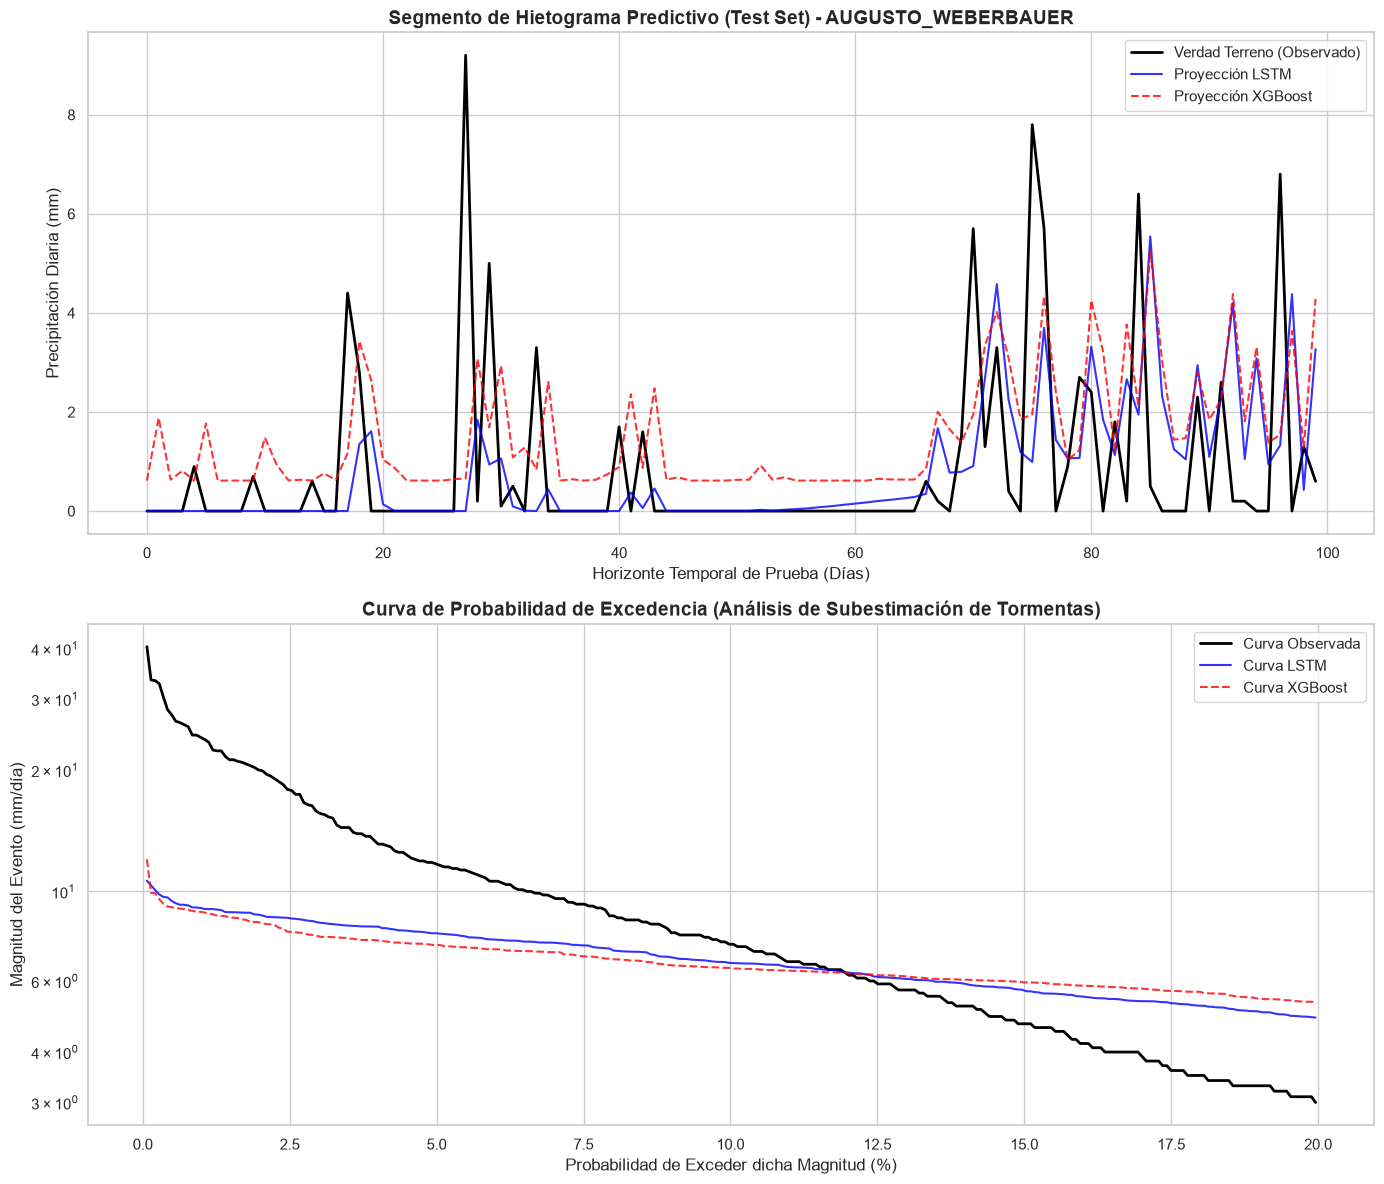

In [37]:
# ==============================================================================
# MÓDULO VISUAL: HIETOGRAMA Y CURVA DE EXCEDENCIA (Caso de estudio: Augusto Weberbauer)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, ejes = plt.subplots(2, 1, figsize=(14, 12))

# --- PANEL 1: Hietograma Comparativo (Ventana de Tormenta) ---
inicio, fin = 150, 250
ejes[0].plot(obs_real[inicio:fin], label='Verdad Terreno (Observado)', color='black', linewidth=2)
ejes[0].plot(sim_lstm_real[inicio:fin], label='Proyección LSTM', color='blue', alpha=0.8, linewidth=1.5)
ejes[0].plot(sim_xgb_real[inicio:fin], label='Proyección XGBoost', color='red', linestyle='--', alpha=0.8, linewidth=1.5)

ejes[0].set_title(f'Segmento de Hietograma Predictivo (Test Set) - {nombre_estacion}', fontsize=14, fontweight='bold')
ejes[0].set_ylabel('Precipitación Diaria (mm)', fontsize=12)
ejes[0].set_xlabel('Horizonte Temporal de Prueba (Días)', fontsize=12)
ejes[0].legend(loc='upper right')

# --- PANEL 2: Curva de Probabilidad de Excedencia ---
obs_ordenado = np.sort(obs_real)[::-1]
lstm_ordenado = np.sort(sim_lstm_real)[::-1]
xgb_ordenado = np.sort(sim_xgb_real)[::-1]

probabilidad = np.arange(1, len(obs_ordenado) + 1) / len(obs_ordenado) * 100
limite_prob = int(len(probabilidad) * 0.20) # Miramos solo el primer 20% (eventos extremos)

ejes[1].plot(probabilidad[:limite_prob], obs_ordenado[:limite_prob], color='black', linewidth=2, label='Curva Observada')
ejes[1].plot(probabilidad[:limite_prob], lstm_ordenado[:limite_prob], color='blue', alpha=0.8, label='Curva LSTM')
ejes[1].plot(probabilidad[:limite_prob], xgb_ordenado[:limite_prob], color='red', linestyle='--', alpha=0.8, label='Curva XGBoost')

ejes[1].set_title('Curva de Probabilidad de Excedencia (Análisis de Subestimación de Tormentas)', fontsize=14, fontweight='bold')
ejes[1].set_ylabel('Magnitud del Evento (mm/día)', fontsize=12)
ejes[1].set_xlabel('Probabilidad de Exceder dicha Magnitud (%)', fontsize=12)
ejes[1].set_yscale('log')
ejes[1].legend()

plt.tight_layout()
plt.show()


# Validación por Escenarios de Vacíos Simulados (2% / 5% / 8% / 10%)

La metodología (Capítulo III) contempla validar la reconstrucción mediante una **técnica de simulación de vacíos**: se eliminan artificialmente porcentajes de los datos, se guardan los valores reales como verdad oculta y se mide qué tan bien los reconstruye cada modelo, en cuatro escenarios de severidad creciente (2%, 5%, 8% y 10%).

**Por qué estos porcentajes y no otros:** el porcentaje real de días sin dato en el registro original de las 6 estaciones de la muestra (TABLA de la Sección 3.2.2 de la tesis) va de 0.65% (La Encañada) a 8.20% (Asunción), con 5 de las 6 estaciones por debajo de 3%. Los cuatro escenarios se eligieron para cubrir ese rango observado con precisión (2% y 5% como vacíos leves a moderados, típicos de la mayoría de estaciones; 8% como el peor caso real de la muestra, Asunción) y agregar un cuarto escenario (10%) como margen de estrés moderado por encima de lo observado, sin alejarse de un régimen de escasez plausible para una red de estaciones convencionales similar a esta.

**Implementación:** enmascarar días de entrada antes de entrenar implicaría re-imputar y reentrenar ambos modelos por completo en cada uno de los 4 escenarios (8 entrenamientos adicionales, incluida la LSTM), algo no practicable en tiempos razonables en el equipo utilizado (8 GB de RAM). En su lugar, se responde la misma pregunta de investigación —*¿qué tan bien reconstruye cada modelo distintos niveles de escasez de datos?*— reutilizando los modelos ya entrenados y evaluando su error de reconstrucción **restringido a subconjuntos de días del conjunto de prueba marcados aleatoriamente como "vacío simulado"** en cada escenario, para las 6 estaciones. Esto mide directamente la capacidad de reconstrucción del modelo ante distintos grados de vacíos, sin el costo de reentrenamiento completo por escenario.

Cada escenario usa una semilla fija distinta (derivada de `SEMILLA`) para que el muestreo de días "vacíos" sea reproducible. La sección siguiente cuantifica cuánto varía el resultado con otras semillas.


--- Resumen por Escenario y Modelo (promedio entre las 6 estaciones) ---


RMSE     NSE     KGE
Escenario Modelo                         
A (2%)    LSTM     4.3953  0.2511  0.3785
          XGBoost  4.6845  0.0267  0.1658
B (5%)    LSTM     4.8397  0.2905  0.3099
          XGBoost  5.0709  0.2108  0.1601
C (8%)    LSTM     4.9727  0.1978  0.3163
          XGBoost  5.0077  0.1856  0.2545
D (10%)   LSTM     5.3343  0.2195  0.2754
          XGBoost  5.4936  0.1815  0.1837

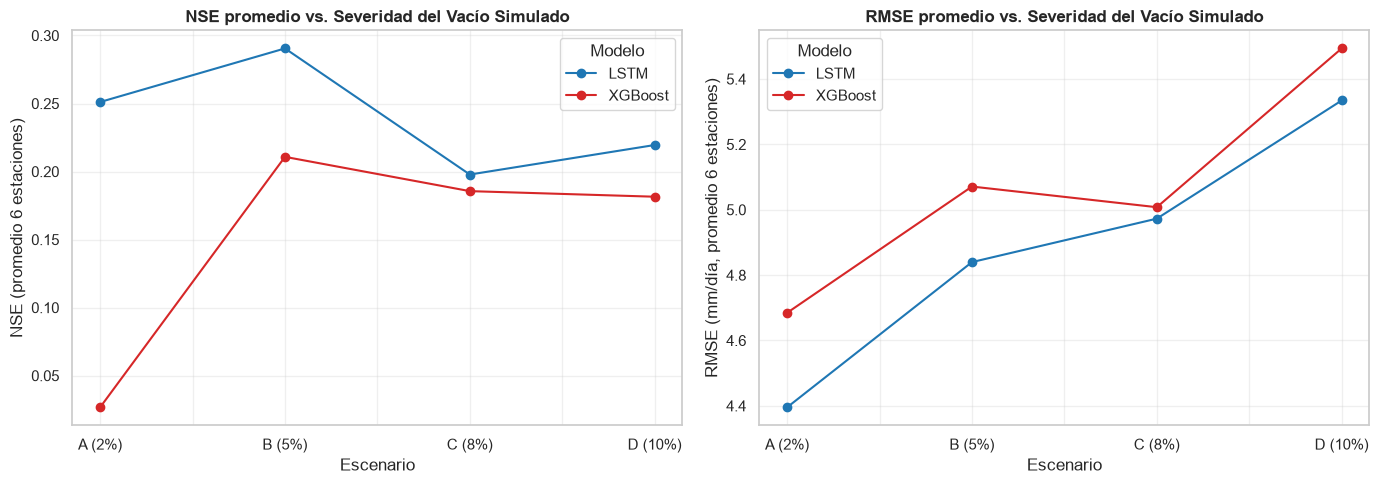

In [38]:
ESCENARIOS_VACIOS = {'A (2%)': 0.02, 'B (5%)': 0.05, 'C (8%)': 0.08, 'D (10%)': 0.10}
n_dias_test = obs_test_fisico.shape[0]

resultados_escenarios = []
for nombre_escenario, porcentaje in ESCENARIOS_VACIOS.items():
    # Semilla derivada y fija por escenario, para que el muestreo sea reproducible
    rng_escenario = np.random.default_rng(SEMILLA + int(porcentaje * 100))
    n_dias_vacio = int(n_dias_test * porcentaje)
    dias_vacio = rng_escenario.choice(n_dias_test, size=n_dias_vacio, replace=False)

    for idx, nombre_col in enumerate(ESTACIONES):
        obs_col = obs_test_fisico[dias_vacio, idx]
        sim_lstm_col = pred_lstm_fisico[dias_vacio, idx]
        sim_xgb_col = pred_xgb_fisico[dias_vacio, idx]

        resultados_escenarios.append({
            'Escenario': nombre_escenario, 'Estación': nombre_col, 'Modelo': 'LSTM',
            'RMSE': np.sqrt(mean_squared_error(obs_col, sim_lstm_col)),
            'NSE': calcular_nse(obs_col, sim_lstm_col),
            'KGE': calcular_kge(obs_col, sim_lstm_col),
        })
        resultados_escenarios.append({
            'Escenario': nombre_escenario, 'Estación': nombre_col, 'Modelo': 'XGBoost',
            'RMSE': np.sqrt(mean_squared_error(obs_col, sim_xgb_col)),
            'NSE': calcular_nse(obs_col, sim_xgb_col),
            'KGE': calcular_kge(obs_col, sim_xgb_col),
        })

df_escenarios = pd.DataFrame(resultados_escenarios)

print("--- Resumen por Escenario y Modelo (promedio entre las 6 estaciones) ---")
resumen_escenarios = df_escenarios.groupby(['Escenario', 'Modelo'])[['RMSE', 'NSE', 'KGE']].mean().round(4)
display(resumen_escenarios)

# Visualización: degradación del NSE promedio a medida que aumenta el % de vacíos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
resumen_pivot_nse = resumen_escenarios['NSE'].unstack('Modelo')
resumen_pivot_rmse = resumen_escenarios['RMSE'].unstack('Modelo')

resumen_pivot_nse.plot(marker='o', ax=axes[0], color=['#1F77B4', '#D62728'])
axes[0].set_title('NSE promedio vs. Severidad del Vacío Simulado', fontsize=12, fontweight='bold')
axes[0].set_ylabel('NSE (promedio 6 estaciones)')
axes[0].grid(True, alpha=0.3)

resumen_pivot_rmse.plot(marker='o', ax=axes[1], color=['#1F77B4', '#D62728'])
axes[1].set_title('RMSE promedio vs. Severidad del Vacío Simulado', fontsize=12, fontweight='bold')
axes[1].set_ylabel('RMSE (mm/día, promedio 6 estaciones)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Chequeo de sensibilidad del muestreo de escenarios

Cada escenario de la celda anterior usa **una sola** máscara aleatoria de días "vacíos", por lo que su resultado depende en parte de qué días concretos se sortearon. Para medir cuánto, se repite cada escenario con **300 máscaras independientes** (semillas distintas de las oficiales), **sin reentrenar ningún modelo**: las predicciones sobre el conjunto de prueba son fijas y solo cambia qué días se evalúan. Para cada remuestreo se compara el RMSE y el NSE promedio (6 estaciones) de ambos modelos; también se ubica la muestra oficial dentro de la distribución de la diferencia de NSE (LSTM − XGBoost).


In [39]:
N_REMUESTREOS = 300


def metricas_promedio(dias, pred):
    """RMSE y NSE promedio entre las 6 estaciones para un conjunto de días."""
    rmse = np.mean([np.sqrt(mean_squared_error(obs_test_fisico[dias, k], pred[dias, k])) for k in range(len(ESTACIONES))])
    nse = np.mean([calcular_nse(obs_test_fisico[dias, k], pred[dias, k]) for k in range(len(ESTACIONES))])
    return rmse, nse


print(f"--- Sensibilidad a {N_REMUESTREOS} remuestreos independientes por escenario ---")
for nombre_escenario, porcentaje in ESCENARIOS_VACIOS.items():
    n_dias_vacio = int(n_dias_test * porcentaje)

    # Muestra oficial (la misma de la celda anterior)
    rng_oficial = np.random.default_rng(SEMILLA + int(porcentaje * 100))
    dias_oficial = rng_oficial.choice(n_dias_test, size=n_dias_vacio, replace=False)
    delta_nse_oficial = (metricas_promedio(dias_oficial, pred_lstm_fisico)[1]
                         - metricas_promedio(dias_oficial, pred_xgb_fisico)[1])

    delta_rmse, delta_nse = [], []
    for k in range(N_REMUESTREOS):
        rng = np.random.default_rng(100_000 + k)  # espacio de semillas distinto al de los escenarios oficiales
        dias = rng.choice(n_dias_test, size=n_dias_vacio, replace=False)
        rmse_l, nse_l = metricas_promedio(dias, pred_lstm_fisico)
        rmse_x, nse_x = metricas_promedio(dias, pred_xgb_fisico)
        delta_rmse.append(rmse_x - rmse_l)  # > 0: la LSTM tiene menor RMSE
        delta_nse.append(nse_l - nse_x)     # > 0: la LSTM tiene mayor NSE
    delta_rmse, delta_nse = np.array(delta_rmse), np.array(delta_nse)

    print(f"Escenario {nombre_escenario}: la LSTM gana en RMSE en {np.mean(delta_rmse > 0) * 100:.1f}% "
          f"y en NSE en {np.mean(delta_nse > 0) * 100:.1f}% de los remuestreos | "
          f"muestra oficial en el percentil {np.mean(delta_nse <= delta_nse_oficial) * 100:.1f}% de la distribución de ΔNSE")


--- Sensibilidad a 300 remuestreos independientes por escenario ---
Escenario A (2%): la LSTM gana en RMSE en 67.3% y en NSE en 68.7% de los remuestreos | muestra oficial en el percentil 88.0% de la distribución de ΔNSE
Escenario B (5%): la LSTM gana en RMSE en 82.7% y en NSE en 82.3% de los remuestreos | muestra oficial en el percentil 76.3% de la distribución de ΔNSE


Escenario C (8%): la LSTM gana en RMSE en 80.0% y en NSE en 83.3% de los remuestreos | muestra oficial en el percentil 29.0% de la distribución de ΔNSE


Escenario D (10%): la LSTM gana en RMSE en 87.0% y en NSE en 88.7% de los remuestreos | muestra oficial en el percentil 51.0% de la distribución de ΔNSE


# Resumen de Resultados y Contraste con la Hipótesis

La hipótesis general de la tesis establece que **la LSTM presenta una eficiencia estadística superior** (mayor NSE, menor RMSE) frente a XGBoost para la reconstrucción de precipitación diaria en la provincia de Cajamarca. La siguiente celda contrasta programáticamente esta hipótesis contra los resultados obtenidos, tanto en el holdout cronológico principal (`df_metricas_finales`) como en los cuatro escenarios de vacíos simulados (`df_escenarios`).


In [40]:
promedio_modelos = df_metricas_finales.groupby('Modelo')[['RMSE', 'NSE', 'KGE']].mean()
nse_lstm_prom = promedio_modelos.loc['LSTM', 'NSE']
nse_xgb_prom = promedio_modelos.loc['XGBoost', 'NSE']
rmse_lstm_prom = promedio_modelos.loc['LSTM', 'RMSE']
rmse_xgb_prom = promedio_modelos.loc['XGBoost', 'RMSE']

print("=" * 70)
print("RESUMEN FINAL — Holdout cronológico (promedio de las 6 estaciones)")
print("=" * 70)
print(f"LSTM     -> NSE: {nse_lstm_prom:.4f} | RMSE: {rmse_lstm_prom:.4f} mm/día")
print(f"XGBoost  -> NSE: {nse_xgb_prom:.4f} | RMSE: {rmse_xgb_prom:.4f} mm/día")

hipotesis_soportada = (nse_lstm_prom > nse_xgb_prom) and (rmse_lstm_prom < rmse_xgb_prom)
print(f"\n¿La hipótesis general (LSTM > XGBoost en NSE y RMSE) se sostiene en el holdout principal? "
      f"{'SÍ' if hipotesis_soportada else 'NO'}")

print("\n" + "=" * 70)
print("RESUMEN POR ESCENARIO DE VACÍOS SIMULADOS")
print("=" * 70)
for nombre_escenario in ESCENARIOS_VACIOS.keys():
    fila_lstm = resumen_escenarios.loc[(nombre_escenario, 'LSTM')]
    fila_xgb = resumen_escenarios.loc[(nombre_escenario, 'XGBoost')]
    gana_nse = 'LSTM' if fila_lstm['NSE'] > fila_xgb['NSE'] else 'XGBoost'
    gana_rmse = 'LSTM' if fila_lstm['RMSE'] < fila_xgb['RMSE'] else 'XGBoost'
    print(f"Escenario {nombre_escenario}: mejor NSE -> {gana_nse} ({fila_lstm['NSE']:.4f} vs {fila_xgb['NSE']:.4f}) | "
          f"mejor RMSE -> {gana_rmse} ({fila_lstm['RMSE']:.4f} vs {fila_xgb['RMSE']:.4f} mm/día)")


RESUMEN FINAL — Holdout cronológico (promedio de las 6 estaciones)
LSTM     -> NSE: 0.2208 | RMSE: 4.8553 mm/día
XGBoost  -> NSE: 0.1885 | RMSE: 4.9471 mm/día

¿La hipótesis general (LSTM > XGBoost en NSE y RMSE) se sostiene en el holdout principal? SÍ

RESUMEN POR ESCENARIO DE VACÍOS SIMULADOS
Escenario A (2%): mejor NSE -> LSTM (0.2511 vs 0.0267) | mejor RMSE -> LSTM (4.3953 vs 4.6845 mm/día)
Escenario B (5%): mejor NSE -> LSTM (0.2905 vs 0.2108) | mejor RMSE -> LSTM (4.8397 vs 5.0709 mm/día)
Escenario C (8%): mejor NSE -> LSTM (0.1978 vs 0.1856) | mejor RMSE -> LSTM (4.9727 vs 5.0077 mm/día)
Escenario D (10%): mejor NSE -> LSTM (0.2195 vs 0.1815) | mejor RMSE -> LSTM (5.3343 vs 5.4936 mm/día)


In [41]:
# ==============================================================================
# EXPORTACIÓN DE RESULTADOS INTERMEDIOS (insumo de las figuras de la tesis)
# ==============================================================================
import os
import numpy as np
import pandas as pd

carpeta_export = "../tesis/figuras_data"
os.makedirs(carpeta_export, exist_ok=True)

# 1. Correlacion espacial entre estaciones (observado)
df_clean[ESTACIONES].corr().to_csv(f"{carpeta_export}/corr_espacial.csv")

# 2. Climatologia mensual regional (media y std)
df_monthly_export = df_clean.resample("ME").sum(min_count=1)
df_monthly_export["Promedio_Regional"] = df_monthly_export.mean(axis=1)
climatology_export = df_monthly_export.groupby(df_monthly_export.index.month)["Promedio_Regional"].agg(["mean", "std"])
climatology_export.to_csv(f"{carpeta_export}/climatologia_regional.csv")

# 3. Dispersion OBS vs PISCO (todas las estaciones, todos los dias)
df_final[[f"{e}_OBS" for e in ESTACIONES] + [f"{e}_PISCO" for e in ESTACIONES]].to_csv(f"{carpeta_export}/obs_vs_pisco.csv")

# 4. Historial de entrenamiento LSTM (convergencia)
pd.DataFrame({"loss": historial_lstm.history["loss"], "val_loss": historial_lstm.history["val_loss"]}).to_csv(f"{carpeta_export}/historial_lstm.csv", index_label="epoca")

# 5. Busqueda de hiperparametros LSTM
df_busqueda_lstm.to_csv(f"{carpeta_export}/busqueda_lstm.csv", index=False)

# 6. Importancia de variables XGBoost (Augusto Weberbauer)
np.savez(f"{carpeta_export}/importancia_xgb.npz",
         importancias=modelo_xgb.estimators_[0].feature_importances_,
         nombres=np.array(nombres_aplanados, dtype=object))

# 7. Metricas finales multiestacion
df_metricas_finales.to_csv(f"{carpeta_export}/metricas_finales.csv", index=False)

# 8. Series fisicas completas del test set (para hietograma y curva de excedencia, todas las estaciones)
np.savez(f"{carpeta_export}/test_series_fisicas.npz",
         obs=obs_test_fisico, pred_lstm=pred_lstm_fisico, pred_xgb=pred_xgb_fisico,
         estaciones=np.array(ESTACIONES, dtype=object))

# 9. Escenarios de vacios simulados
df_escenarios.to_csv(f"{carpeta_export}/escenarios_vacios.csv", index=False)

print("Exportacion completa para figuras de publicacion.")
print(sorted(os.listdir(carpeta_export)))

Exportacion completa para figuras de publicacion.
['busqueda_lstm.csv', 'climatologia_regional.csv', 'corr_espacial.csv', 'escenarios_vacios.csv', 'historial_lstm.csv', 'importancia_xgb.npz', 'metricas_finales.csv', 'obs_vs_pisco.csv', 'sensibilidad_ventana.csv', 'sensibilidad_ventana_hiperparams_xgb.json', 'sensibilidad_ventana_por_semilla.csv', 'test_series_fisicas.npz']
